#**OBJETIVO**

Notebook Python com o modelo preditivo da análise de risco de defasagem, demonstrando as etapas de: feature engineering; separação dos dados em treino e teste; modelagem preditiva; avaliação dos resultados.
___

**Dicionário dos dados e arquivo complementar:** encontrado em "/data"
___

**Anotações e constatações iniciais importantes**:

<br>

**Sobre a Passos Mágicos**: é uma associação sem fins lucrativos que oferece um programa de educação de qualidade para jovens e crianças do município de Embu-Guaçu. A Passos Mágicos não trabalha somente com desempenho escolar. O acompanhamento é multidimensional: envolve aprendizagem, engajamento, autoavaliação, aspectos psicossociais, aspectos psicopedagógicos e o chamado Ponto de Virada.

<br>

* A defasagem é calculada por: **Fase efetiva - Fase ideal**.
* Indicadores de avaliação: IAN, IDA, IEG e IAA
* Indicadores de Conselho: IPS, IPP e IPV

<br>

Significado dos indicadores:
* IAN = Indicador de adequação de nível
* IDA = Indicador de desempenho acadêmico
* IEG = Indicador de engajamento
* IAA = Indicador de autoavaliação
* IPS = Indicador Psicosocial
* IPP = Indicador Psicopedagógico
* IPV = Indicador de Ponto de virada

<br>

Composição do INDE:
* Fases 0 a 7: <br>
  IAN x 0,1 + IDA x 0,2 + IEG x 0,2 + IAA x 0,1 + IPS x 0,1 + IPP x 0,1 + IPV x 0,2
* Fase 8: <br>
  IAN x 0,1 + IDA x 0,4 + IEG x 0,2 + IAA x 0,1 + IPS x 0,2

<br>

A nota do INDE determina a pedra:
* 3,0 ~ 6,0 = Quartzo
* 6,1 ~ 7,1 = Ágata
* 7,2 ~ 8,1 = Ametista
* 8,2 >= Topázio

<br>

Cálculos dos indicadores:
* IAN = Fase atual - Fase Ideal
* IDA = (Mat + Por + Ing)/3
* IEG = Soma das pontuações das tarefas realizadas e registradas / Número de tarefas
* IAA = Soma das pontuações das respostas do estudante / Número total de perguntas
* IPS = Soma das pontuações dos avaliadores / Número de avaliadores
* IPP = Soma das avaliações sobre aspectos pedagógicos / Número de avaliações
* IPV = Análises longitudinais de progresso acadêmico, engajamento e desenvolvimento emocional

<br>

Claramente risco de data leakege porque entrega se o aluno está em defasagem:

* IAN


## ETAPA 1: Leitura dos dados.

In [1]:
import pandas as pd

In [2]:
df = pd.read_excel('BASE DE DADOS PEDE 2024 - DATATHON.xlsx', sheet_name=None)

In [3]:
# vou checar se há mais de uma aba/planilha no arquivo principal
df.keys()

dict_keys(['PEDE2022', 'PEDE2023', 'PEDE2024'])

In [4]:
# como há 3 planilhas, vou atribuir cada uma em um df individual
df_PEDE2022 = pd.read_excel('BASE DE DADOS PEDE 2024 - DATATHON.xlsx', sheet_name='PEDE2022')
df_PEDE2023 = pd.read_excel('BASE DE DADOS PEDE 2024 - DATATHON.xlsx', sheet_name='PEDE2023')
df_PEDE2024 = pd.read_excel('BASE DE DADOS PEDE 2024 - DATATHON.xlsx', sheet_name='PEDE2024')

In [5]:
# já vou configurar para o pandas não ocultar nenhuma coluna
pd.set_option('display.max_columns', None)

In [6]:
# vou realizar a visualização prévia dos dados de cada uma das planilhas
# 2022
df_PEDE2022.head()

,RA,Fase,Turma,Nome,Ano nasc,Idade 22,Gênero,Ano ingresso,Instituição de ensino,Pedra 20,Pedra 21,Pedra 22,INDE 22,Cg,Cf,Ct,Nº Av,Avaliador1,Rec Av1,Avaliador2,Rec Av2,Avaliador3,Rec Av3,Avaliador4,Rec Av4,IAA,IEG,IPS,Rec Psicologia,IDA,Matem,Portug,Inglês,Indicado,Atingiu PV,IPV,IAN,Fase ideal,Defas,Destaque IEG,Destaque IDA,Destaque IPV
0,RA-1,7,A,Aluno-1,2003,19,Menina,2016,Escola Pública,Ametista,Ametista,Quartzo,5.783,753,18,10,4,Avaliador-5,Mantido na Fase atual,Avaliador-27,Promovido de Fase + Bolsa,Avaliador-28,Promovido de Fase,Avaliador-31,Mantido na Fase atual,8.3,4.1,5.6,Requer avaliação,4.0,2.7,3.5,6.0,Sim,Não,7.278,5.0,Fase 8 (Universitários),-1,Melhorar: Melhorar a sua entrega de lições de ...,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Melhorar: Integrar-se mais aos Princípios Pass...
1,RA-2,7,A,Aluno-2,2005,17,Menina,2017,Rede Decisão,Ametista,Ametista,Ametista,7.055,469,8,3,4,Avaliador-5,Promovido de Fase,Avaliador-27,Promovido de Fase + Bolsa,Avaliador-28,Promovido de Fase,Avaliador-31,Promovido de Fase + Bolsa,8.8,5.2,6.3,Sem limitações,6.8,6.3,4.5,9.7,Não,Não,6.778,10.0,Fase 7 (3º EM),0,Melhorar: Melhorar a sua entrega de lições de ...,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Melhorar: Integrar-se mais aos Princípios Pass...
2,RA-3,7,A,Aluno-3,2005,17,Menina,2016,Rede Decisão,Ametista,Ametista,Ágata,6.591,629,13,6,4,Avaliador-5,Promovido de Fase,Avaliador-27,Promovido de Fase + Bolsa,Avaliador-28,Promovido de Fase + Bolsa,Avaliador-31,Promovido de Fase + Bolsa,0.0,7.9,5.6,Sem limitações,5.6,5.8,4.0,6.9,Não,Não,7.556,10.0,Fase 7 (3º EM),0,Destaque: A sua boa entrega das lições de casa.,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Destaque: A sua boa integração aos Princípios ...
3,RA-4,7,A,Aluno-4,2005,17,Menino,2017,Rede Decisão,Ametista,Ametista,Quartzo,5.951,731,15,7,4,Avaliador-5,Promovido de Fase,Avaliador-27,Mantido na Fase atual,Avaliador-28,Mantido na Fase atual,Avaliador-31,Mantido na Fase atual,8.8,4.5,5.6,Requer avaliação,5.0,2.8,3.5,8.7,Não,Não,5.278,10.0,Fase 7 (3º EM),0,Melhorar: Melhorar a sua entrega de lições de ...,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Melhorar: Integrar-se mais aos Princípios Pass...
4,RA-5,7,A,Aluno-5,2005,17,Menina,2016,Rede Decisão,Ametista,Ametista,Ametista,7.427,344,6,2,4,Avaliador-5,Promovido de Fase,Avaliador-27,Promovido de Fase + Bolsa,Avaliador-28,Promovido de Fase + Bolsa,Avaliador-31,Promovido de Fase + Bolsa,7.9,8.6,5.6,Requer avaliação,5.2,7.0,2.9,5.7,Não,Não,7.389,10.0,Fase 7 (3º EM),0,Destaque: A sua boa entrega das lições de casa.,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Melhorar: Integrar-se mais aos Princípios Pass...


In [7]:
df_PEDE2022.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 860 entries, 0 to 859
Data columns (total 42 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   RA                     860 non-null    object 
 1   Fase                   860 non-null    int64  
 2   Turma                  860 non-null    object 
 3   Nome                   860 non-null    object 
 4   Ano nasc               860 non-null    int64  
 5   Idade 22               860 non-null    int64  
 6   Gênero                 860 non-null    object 
 7   Ano ingresso           860 non-null    int64  
 8   Instituição de ensino  860 non-null    object 
 9   Pedra 20               323 non-null    object 
 10  Pedra 21               462 non-null    object 
 11  Pedra 22               860 non-null    object 
 12  INDE 22                860 non-null    float64
 13  Cg                     860 non-null    int64  
 14  Cf                     860 non-null    int64  
 15  Ct    

In [8]:
# 2023
df_PEDE2023.head()

,RA,Fase,INDE 2023,Pedra 2023,Turma,Nome Anonimizado,Data de Nasc,Idade,Gênero,Ano ingresso,Instituição de ensino,Pedra 20,Pedra 21,Pedra 22,Pedra 23,INDE 22,INDE 23,Cg,Cf,Ct,Nº Av,Avaliador1,Rec Av1,Avaliador2,Rec Av2,Avaliador3,Rec Av3,Avaliador4,Rec Av4,IAA,IEG,IPS,IPP,Rec Psicologia,IDA,Mat,Por,Ing,Indicado,Atingiu PV,IPV,IAN,Fase Ideal,Defasagem,Destaque IEG,Destaque IDA,Destaque IPV,Destaque IPV.1
0,RA-861,ALFA,9.31095,Topázio,ALFA A - G0/G1,Aluno-861,6/17/2015,8,Feminino,2023,Pública,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,Avaliador-11,NaN,Avaliador-2,NaN,NaN,NaN,NaN,NaN,9.5,10.0,8.13,8.4375,NaN,9.6,9.8,9.4,NaN,NaN,NaN,8.920,10.0,ALFA (1° e 2° ano),0,NaN,NaN,NaN,NaN
1,RA-862,ALFA,8.22120,Topázio,ALFA A - G0/G1,Aluno-862,5/31/2014,9,Masculino,2023,Pública,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,Avaliador-11,NaN,Avaliador-2,NaN,NaN,NaN,NaN,NaN,8.5,9.1,8.14,7.5000,NaN,8.9,8.5,9.2,NaN,NaN,NaN,8.585,5.0,Fase 1 (3° e 4° ano),-1,NaN,NaN,NaN,NaN
2,RA-863,ALFA,5.92975,Quartzo,ALFA A - G0/G1,Aluno-863,2/25/2016,7,Masculino,2023,Pública,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,Avaliador-11,NaN,Avaliador-2,NaN,NaN,NaN,NaN,NaN,0.0,7.6,3.14,5.9375,NaN,6.3,7.0,5.5,NaN,NaN,NaN,6.260,10.0,ALFA (1° e 2° ano),0,NaN,NaN,NaN,NaN
3,RA-864,ALFA,7.03400,Ametista,ALFA A - G0/G1,Aluno-864,2015-12-03 00:00:00,1900-01-08 00:00:00,Feminino,2023,Pública,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,Avaliador-11,NaN,Avaliador-2,NaN,NaN,NaN,NaN,NaN,0.0,7.6,8.14,7.5000,NaN,6.3,7.0,5.5,NaN,NaN,NaN,8.500,10.0,ALFA (1° e 2° ano),0,NaN,NaN,NaN,NaN
4,RA-865,ALFA,8.15520,Topázio,ALFA A - G0/G1,Aluno-865,11/13/2014,8,Masculino,2023,Pública,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,Avaliador-11,NaN,Avaliador-2,NaN,NaN,NaN,NaN,NaN,8.5,8.7,7.52,7.5000,NaN,7.4,7.3,7.5,NaN,NaN,NaN,7.915,10.0,ALFA (1° e 2° ano),0,NaN,NaN,NaN,NaN


In [9]:
df_PEDE2023.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 48 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   RA                     1014 non-null   object 
 1   Fase                   1014 non-null   object 
 2   INDE 2023              931 non-null    float64
 3   Pedra 2023             931 non-null    object 
 4   Turma                  1014 non-null   object 
 5   Nome Anonimizado       1014 non-null   object 
 6   Data de Nasc           1014 non-null   object 
 7   Idade                  1014 non-null   object 
 8   Gênero                 1014 non-null   object 
 9   Ano ingresso           1014 non-null   int64  
 10  Instituição de ensino  1014 non-null   object 
 11  Pedra 20               240 non-null    object 
 12  Pedra 21               335 non-null    object 
 13  Pedra 22               600 non-null    object 
 14  Pedra 23               0 non-null      float64
 15  INDE

In [10]:
# 2024
df_PEDE2024.head()

,RA,Fase,INDE 2024,Pedra 2024,Turma,Nome Anonimizado,Data de Nasc,Idade,Gênero,Ano ingresso,Instituição de ensino,Pedra 20,Pedra 21,Pedra 22,Pedra 23,INDE 22,INDE 23,Cg,Cf,Ct,Nº Av,Avaliador1,Rec Av1,Avaliador2,Rec Av2,Avaliador3,Avaliador4,Avaliador5,Avaliador6,IAA,IEG,IPS,IPP,Rec Psicologia,IDA,Mat,Por,Ing,Indicado,Atingiu PV,IPV,IAN,Fase Ideal,Defasagem,Destaque IEG,Destaque IDA,Destaque IPV,Escola,Ativo/ Inativo,Ativo/ Inativo.1
0,RA-1275,ALFA,7.611367,Ametista,ALFA A - G0/G1,Aluno-1275,2016-07-28,8,Masculino,2024,Pública,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,Avaliador-11,NaN,Avaliador-2,NaN,Avaliador-9,NaN,NaN,NaN,10.002,8.666667,6.26,5.625,NaN,8.0,10.0,6.0,NaN,NaN,NaN,5.446667,10.0,ALFA (1° e 2° ano),0,NaN,NaN,NaN,EE Chácara Florida II,Cursando,Cursando
1,RA-1276,ALFA,8.002867,Topázio,ALFA A - G0/G1,Aluno-1276,2016-10-16,8,Feminino,2024,Pública,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,Avaliador-11,NaN,Avaliador-2,NaN,Avaliador-9,NaN,NaN,NaN,10.002,9.333333,3.76,7.500,NaN,8.0,10.0,6.0,NaN,NaN,NaN,7.050000,10.0,ALFA (1° e 2° ano),0,NaN,NaN,NaN,EE Chácara Florida II,Cursando,Cursando
2,RA-1277,ALFA,7.9522,Ametista,ALFA A - G0/G1,Aluno-1277,2016-08-16,8,Masculino,2024,Pública,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,Avaliador-11,NaN,Avaliador-2,NaN,Avaliador-9,NaN,NaN,NaN,10.002,9.083333,3.76,7.500,NaN,8.0,10.0,6.0,NaN,NaN,NaN,7.046667,10.0,ALFA (1° e 2° ano),0,NaN,NaN,NaN,EE Dom Pedro Villas Boas de Souza,Cursando,Cursando
3,RA-868,ALFA,7.156367,Ametista,ALFA A - G0/G1,Aluno-868,2015-11-08,8,Masculino,2023,Pública,NaN,NaN,NaN,Topázio,NaN,8.63895,NaN,NaN,NaN,3,Avaliador-11,NaN,Avaliador-2,NaN,Avaliador-9,NaN,NaN,NaN,8.002,9.750000,3.76,6.875,NaN,7.0,8.0,6.0,NaN,NaN,NaN,7.213333,5.0,Fase 1 (3° e 4° ano),-1,NaN,NaN,NaN,EE Chácara Florida II,Cursando,Cursando
4,RA-1278,ALFA,5.4442,Quartzo,ALFA A - G0/G1,Aluno-1278,2015-03-22,9,Masculino,2024,Pública,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,Avaliador-11,NaN,Avaliador-2,NaN,Avaliador-9,NaN,NaN,NaN,9.002,4.166667,3.76,5.000,NaN,7.5,8.0,7.0,NaN,NaN,NaN,4.173333,5.0,Fase 1 (3° e 4° ano),-1,NaN,NaN,NaN,EM Etelvina Delfim Simões,Cursando,Cursando


In [11]:
df_PEDE2024.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1156 entries, 0 to 1155
Data columns (total 50 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   RA                     1156 non-null   object        
 1   Fase                   1156 non-null   object        
 2   INDE 2024              1092 non-null   object        
 3   Pedra 2024             1092 non-null   object        
 4   Turma                  1156 non-null   object        
 5   Nome Anonimizado       1156 non-null   object        
 6   Data de Nasc           1156 non-null   datetime64[ns]
 7   Idade                  1156 non-null   int64         
 8   Gênero                 1156 non-null   object        
 9   Ano ingresso           1156 non-null   int64         
 10  Instituição de ensino  1155 non-null   object        
 11  Pedra 20               191 non-null    object        
 12  Pedra 21               264 non-null    object        
 13  Ped

**Conclusões com as saídas dos últimos códigos:**
* Deu pra visualizar que a dimensão das planilhas foram crescendo a cada ano, tanto no número de registros quanto no número de colunas.
* Com o comando .info deu pra ver que aparentemente as planilhas herdam dados dos anos anteriores, então talvez a planilha de 2024 comtemple todos os dados dos anos anteriores.
* Como as planilhas trazem dados de anos anteriores dos alunos, deva ter algum
identificador por aluno que permite os registros das tabelas se relacionarem, com este identificador consiguirei checar se todos os dados de 2022 estão na planilha de 2023, e se todos de 2023 estão em 2024.
* No dicionário de dados e nos arquivos complementares não encontrei nada que confirme a existência e qual coluna seria a primary key. Olhando para uma amostra dos dados e pela posição da coluna, eu chutaria que a coluna "RA" deve ser o ID que quero.
* E como deu para ver 2022 tem 42 colunas, 2023 48 colunas e 2024 50 colunas, ou seja, há colunas que coincidem entre 2 ou 3 planilhas e pelo menos duas colunas que existem em apenas uma planilha.
* Vou checar o total de colunas (sem repetir) e com a ajuda do dicionário de dados e dos arquivos complementares, vou entender o que cada coluna refere-se, tem uns que os nomes não sção auto descritivos.




In [12]:
lista_colunas = list(dict.fromkeys(
    list(df_PEDE2022.columns) + list(df_PEDE2023.columns) + list(df_PEDE2024.columns)
))
for coluna in lista_colunas:
  print(coluna)

RA
Fase
Turma
Nome
Ano nasc
Idade 22
Gênero
Ano ingresso
Instituição de ensino
Pedra 20
Pedra 21
Pedra 22
INDE 22
Cg
Cf
Ct
Nº Av
Avaliador1
Rec Av1
Avaliador2
Rec Av2
Avaliador3
Rec Av3
Avaliador4
Rec Av4
IAA
IEG
IPS
Rec Psicologia
IDA
Matem
Portug
Inglês
Indicado
Atingiu PV
IPV
IAN
Fase ideal
Defas
Destaque IEG
Destaque IDA
Destaque IPV
INDE 2023
Pedra 2023
Nome Anonimizado
Data de Nasc
Idade
Pedra 23
INDE 23
IPP
Mat
Por
Ing
Fase Ideal
Defasagem
Destaque IPV.1
INDE 2024
Pedra 2024
Avaliador5
Avaliador6
Escola
Ativo/ Inativo
Ativo/ Inativo.1


**Entendendo o que cada coluna é**:
* RA (2022–2024): Identificador anonimizado do aluno na base.
* Fase (2022–2024): Nível/fase de aprendizado do aluno na Passos Mágicos.
* Turma (2022–2024): Turma do aluno dentro da fase.
* Nome (2022): Nome anonimizado do aluno.
* Ano nasc (2022): Ano de nascimento.
* Idade 22 (2022): Idade do aluno em 2022.
* Gênero (2022–2024): Gênero registrado para o aluno.
* Ano ingresso (2022–2024): Ano em que o aluno ingressou na Passos Mágicos.
* Instituição de ensino (2022–2024): Instituição/tipo de instituição de ensino frequentada.
* Pedra 20 (2022–2024): Classificação Pedra referente a 2020.
* Pedra 21 (2022–2024): Classificação Pedra referente a 2021.
* Pedra 22 (2022–2024): Classificação Pedra referente a 2022.
* INDE 22 (2022–2024): Índice de Desenvolvimento Educacional de 2022.
* Cg (2022–2024): Classificação/Ranking Geral do aluno.
* Cf (2022–2024): Classificação/Ranking do aluno dentro da Fase.
* Ct (2022–2024): Classificação/Ranking do aluno dentro da Turma.
* Nº Av (2022–2024): Número/quantidade de avaliações realizadas ou quantidade de avaliadores.
* Avaliador1 (2022–2024): Identificação anonimizada do primeiro avaliador.
* Rec Av1 (2022–2024): Recomendação associada à primeira avaliação.
* Avaliador2 (2022–2024): Identificação anonimizada do segundo avaliador.
* Rec Av2 (2022–2024): Recomendação associada à segunda avaliação.
* Avaliador3 (2022–2024): Identificação anonimizada do terceiro avaliador.
* Rec Av3 (2022–2023): Recomendação associada à terceira avaliação.
* Avaliador4 (2022–2024): Identificação anonimizada do quarto avaliador.
* Rec Av4 (2022–2023): Recomendação associada à quarta avaliação.
* IAA (2022–2024): Indicador de Autoavaliação.
* IEG (2022–2024): Indicador de Engajamento.
* IPS (2022–2024): Indicador Psicossocial.
* Rec Psicologia (2022–2024): Recomendação da equipe de psicologia sobre o aluno.
* IDA (2022–2024): Indicador de Desempenho Acadêmico/Aprendizagem.
* Matem (2022): Nota de Matemática.
* Portug (2022): Nota de Português.
* Inglês (2022): Nota de Inglês.
* Indicado (2022–2024): Indicação do aluno para bolsa.
* Atingiu PV (2022–2024): Indica se o aluno atingiu o chamado Ponto de Virada.
* IPV (2022–2024): Indicador de Ponto de Virada.
* IAN (2022–2024): Indicador de Adequação ao Nível.
* Fase ideal (2022): Fase considerada ideal para o aluno.
* Defas (2022): Defasagem entre fase efetiva e fase ideal.
* Destaque IEG (2022–2024): Observação/destaque dos avaliadores sobre Engajamento.
* Destaque IDA (2022–2024): Observação/destaque dos avaliadores sobre Aprendizagem/Desempenho Acadêmico.
* Destaque IPV (2022–2024): Observação/destaque dos avaliadores sobre Ponto de Virada.
* INDE 2023 (2023): INDE corrente de 2023.
* Pedra 2023 (2023): Classificação Pedra corrente calculada a partir do INDE 2023.
* Nome Anonimizado (2023–2024): Nome anonimizado do aluno.
* Data de Nasc (2023–2024): Data de nascimento.
* Idade (2023–2024): Idade no respectivo registro anual.
* Pedra 23 (2023–2024): Classificação Pedra referente a 2023 em campo histórico.
* INDE 23 (2023–2024): INDE de 2023 armazenado como campo histórico.
* IPP (2023–2024): Indicador Psicopedagógico. Não existe como coluna original em 2022.
* Mat (2023–2024): Nota de Matemática.
* Por (2023–2024): Nota de Português.
* Ing (2023–2024): Nota de Inglês.
* Fase Ideal (2023–2024): Mesmo conceito: fase considerada ideal.
* Defasagem (2023–2024): Mesmo conceito de defasagem.
* Destaque IPV.1 (2024): Observação/destaque dos avaliadores sobre Ponto de Virada.
* INDE 2024 (2024): INDE corrente de 2024.
* Pedra 2024 (2024): Classificação Pedra corrente calculada a partir do INDE 2024.
* Avaliador5 (2024): Identificação anonimizada do quinto avaliador.
* Avaliador6 (2024): Identificação anonimizada do sexto avaliador.
* Escola (2024): Nome da escola do aluno; por exemplo, aparecem nomes específicos de escolas, enquanto Instituição de ensino contém categorias como pública.
* Ativo/ Inativo (2024): Situação do aluno na base, por exemplo Cursando.
* Ativo/ Inativo.1 (2024): Situação do aluno na base, por exemplo Cursando.


___
## ETAPA 2: Análise e padronização entre as planilhas.

### 2.1: Análise para descobrir se a cada ano a planilha herda todos os alunos dos anos anteriores.

In [13]:
# vou verificar nos dataframes se existe alguma primary key que identifique cada linha
# vou checar quais colunas tem a quantidade de valor único igual a quantidade total
# de registros da tabela, consequentemente um valor diferente por linha.
# Primeiro na planilha de 2022
df_PEDE2022.nunique() == len(df_PEDE2022)

,0
RA,True
Fase,False
Turma,False
Nome,True
Ano nasc,False
Idade 22,False
Gênero,False
Ano ingresso,False
Instituição de ensino,False
Pedra 20,False


In [14]:
# 2023
df_PEDE2023.nunique() == len(df_PEDE2023)

,0
RA,True
Fase,False
INDE 2023,False
Pedra 2023,False
Turma,False
Nome Anonimizado,True
Data de Nasc,False
Idade,False
Gênero,False
Ano ingresso,False


In [15]:
# 2024
df_PEDE2024.nunique() == len(df_PEDE2024)

,0
RA,True
Fase,False
INDE 2024,False
Pedra 2024,False
Turma,False
Nome Anonimizado,True
Data de Nasc,False
Idade,False
Gênero,False
Ano ingresso,False


**Conclusões com as saídas dos últimos códigos:**
* A única coluna que confirmou ter valores distintos em todas as linhas e em todas as planilhas é a coluna "RA".
* Agora, vou checar quantos valores de "RA" são em comum nas três planilhas, se a quantidade igual o total de 2022, então confirma meu achismo, de que as planilhas herdam os alunos dos anos anteriores.

In [16]:
# vou guardar os valores da coluna "RA" em uma variável set para não ter duplicados
ra_2022 = set(df_PEDE2022["RA"])
ra_2023 = set(df_PEDE2023["RA"])
ra_2024 = set(df_PEDE2024["RA"])

# usar o intersection para guardar os valores que aparecem em ambos os sets
ra_em_ambos = ra_2022.intersection(ra_2023, ra_2024)

# vou printar pra visualizar se a quantidade presente em 2022 é a mesma do total
# de registros presentes em ambas as tabelas, para confirmar se a planilha de um
# ano herda todos os alunos do ano anterior
print("RA's em 2022:", len(ra_2022))
print("RA's em 2023:", len(ra_2023))
print("RA's em 2024:", len(ra_2024))
print("RA's em ambos:", len(ra_em_ambos))

RA's em 2022: 860
RA's em 2023: 1014
RA's em 2024: 1156
RA's em ambos: 468


**Conclusões com as saídas dos últimos códigos:**
* apenas 468 valores de "RA" são em comum nas três planilhas, infelizmente.
* como as planilhas não herdam todos os alunos dos anos anteriores, provavelmente quem deixa de ser aluno, não aparece nas planilhas dos anos seguintes, então é um histórico só de alunos matriculados naquele ano;
* agora vou confirmar que, por exemplo, o aluno "RA-1" da planilha de 2022 é o mesmo aluno "RA-1" nas planilhas de 2023 e 2024. E assim saber se de fato as RA's que repetem nas planilhas sáo o mesmo aluno.

In [17]:
# pra evitar erro, vou garantir que use colunas que é certeza que aparecem nos três df's
colunas_comuns = set(df_PEDE2022.columns) & \
                 set(df_PEDE2023.columns) & \
                 set(df_PEDE2024.columns)

colunas_comuns

{'Ano ingresso',
 'Atingiu PV',
 'Avaliador1',
 'Avaliador2',
 'Avaliador3',
 'Avaliador4',
 'Cf',
 'Cg',
 'Ct',
 'Destaque IDA',
 'Destaque IEG',
 'Destaque IPV',
 'Fase',
 'Gênero',
 'IAA',
 'IAN',
 'IDA',
 'IEG',
 'INDE 22',
 'IPS',
 'IPV',
 'Indicado',
 'Instituição de ensino',
 'Nº Av',
 'Pedra 20',
 'Pedra 21',
 'Pedra 22',
 'RA',
 'Rec Av1',
 'Rec Av2',
 'Rec Psicologia',
 'Turma'}

In [18]:
# pra fazer essa checagem, eu vou selecionar colunas que pela lógica são colunas que
# de dados que devem permanecer o mesmo valor de um ano para o outro, assim
# provando ser a mesma pessoa.
colunas_selecionadas = ['RA', 'Gênero', 'Ano ingresso', 'INDE 22', 'Pedra 20', 'Pedra 21', 'Pedra 22']

In [19]:
# visualizar uma amostra aleatória de 5 RA's que aparecem nas 3 planilhas
import random

ra_amostras = random.sample(list(ra_em_ambos), 5)

ra_amostras

['RA-326', 'RA-111', 'RA-764', 'RA-733', 'RA-147']

In [20]:
# usar um laço for para checar as 5 amostras e ver se trata-se do mesmo aluno
# nas três planilhas.

for ra in ra_amostras:
  aluno_2022 = df_PEDE2022.loc[
      df_PEDE2022["RA"] == ra,
      colunas_selecionadas
  ].iloc[0]

  aluno_2023 = df_PEDE2023.loc[
      df_PEDE2023["RA"] == ra,
      colunas_selecionadas
  ].iloc[0]

  aluno_2024 = df_PEDE2024.loc[
      df_PEDE2024["RA"] == ra,
      colunas_selecionadas
  ].iloc[0]

  comparacao = pd.DataFrame({
      "2022": aluno_2022,
      "2023": aluno_2023,
      "2024": aluno_2024
  })

  comparacao["igual_nos_3_anos"] = (
      (comparacao["2022"] == comparacao["2023"]) &
      (comparacao["2023"] == comparacao["2024"])
  )

  print(comparacao)
  print('_'*62 + '\n')

                 2022      2023      2024  igual_nos_3_anos
RA             RA-326    RA-326    RA-326              True
Gênero         Menina  Feminino  Feminino             False
Ano ingresso     2022      2022      2022              True
INDE 22          8.22      8.22  8.219955             False
Pedra 20          NaN       NaN       NaN             False
Pedra 21          NaN       NaN       NaN             False
Pedra 22      Topázio   Topázio   Topázio              True
______________________________________________________________

                  2022      2023      2024  igual_nos_3_anos
RA              RA-111    RA-111    RA-111              True
Gênero          Menina  Feminino  Feminino             False
Ano ingresso      2020      2020      2021             False
INDE 22          8.646     8.646  8.645933             False
Pedra 20      Ametista  Ametista  Ametista              True
Pedra 21       Topázio   Topázio   Topázio              True
Pedra 22       Topázio   Topá

**Conclusões com as saídas dos últimos códigos:**
* Na confirmação de que o identificador "RA" trata-se do mesmo aluno em qualquer planilha, apesar de apresentar "False" na comparação de algumas coluna-valor, dá pra concluir que SIM, a "RA" é o identificador único de cada aluno, independente do ano, ou seja, temos o caso de longitudional, onde há dados do mesmo aluno ao longo de cada ano.
* As comparações que deram "False" são claramente variações da mesma informação, deu pra ver isso nas colunas "Gênero" (2022 está como "menino", e nas demais está como "masculino"), em "Ano ingresso" parece todos os registros estão como 2021, e a coluna "INDE 22" no ano de 2024 não está com o valor arredondado em 2 casas decimais assim como nas planilhas de outros anos.
* Ou seja, já temos pistas que na etapa de limpeza dos dados tem coisa para se fazer.
* outra coisa que deu para notar mais ainda, foi que ao listar as colunas em comum, várias colunas ficaram ausentes, e não somente as colunas próprias dos anos, então, antes de fazer uma análise mais profunda dos dados (tipos, formtados fora de padrão, valores nulos, outliers, etc.), será necessário analisar sobre essa divergência das features nas bases.

<br>

**Próximo passo:**
Já deu pra ter uma prévia que várias colunas/features não estão presentes em todas as três planilhas, então vou investigar mais isso para entender o cenário.

### 2.2: Análise das colunas/features que existem nas 3 planilhas

In [21]:
# já chequei quais e quantas colunas estão presentes nas 3 planilhas, mas será
# necessário investigar todos os cenários para se ter conclusões mais precisas dos porques.
# vou checar quais colunas da base de 2022 existem na base de 2023, depois eu escalo
# essa checagem para 2024. Vou criar uma lista, para cada coluna da base de 2022,
#se existir na base de 2023, seu valor será guardado nesta lista
colunas_comuns_2022_2023 = [col for col in df_PEDE2022.columns if col in df_PEDE2023.columns]

In [22]:
# checando tamanho da lista para saber quantas colunas há em comum nas bases de 2022 e 2023
print(f'(df_PEDE2022 e df_PEDE2023) Total de colunas em comum: {len(colunas_comuns_2022_2023)}')

(df_PEDE2022 e df_PEDE2023) Total de colunas em comum: 34


In [23]:
# checando quantidade de colunas em comum entre as bases de 2022 e 2024
colunas_comuns_2022_2024 = [col for col in df_PEDE2022.columns if col in df_PEDE2024.columns]
print(f'(df_PEDE2022 e df_PEDE2024) Total de colunas em comum: {len(colunas_comuns_2022_2024)}')

(df_PEDE2022 e df_PEDE2024) Total de colunas em comum: 32


In [24]:
# checando quantidade de colunas em comum entre as bases de 2023 e 2024
colunas_comuns_2023_2024 = [col for col in df_PEDE2023.columns if col in df_PEDE2024.columns]
print(f'(df_PEDE2023 e df_PEDE2024) Total de colunas em comum: {len(colunas_comuns_2023_2024)}')

(df_PEDE2023 e df_PEDE2024) Total de colunas em comum: 43


**Conclusões com as saídas dos últimos códigos:**
* no máximo 32 colunas em comum podem estar presentes na estrutura dos 3 datasets, mas ainda preciso confirmar;
* como já está constatado que todas as 3 planilhas tem diferenças entre si na estrutura, vou analisar os seguintes cenários, além do cenário já analisado das features que estão nas 3 planilhas:
  * Quais colunas existem em apenas 2 datasets? (dentro das três possbilidades)
  * Quais colunas existem apenas em 1 dataset? (dentro das três possibilidades)
* agora o objetivo é identificar quais colunas são exclusivas de cada planilha e já tentar ter uma noção se poderei dropar a coluna ou não, também vou tentar identificar se há colunas com nomes diferentes entre as planilhas, mas que tratam-se da mesma informação/assunto.
* vou tentar clarear mais essa parte, depois eu parto para ter uma dimensão dos valores nulos nas colunas e a checagem da existência de valores duplicados.

In [25]:
# vou visualizar novamente quais e quantas colunas existem nas 3 planilhas para
# ficar nessa sessão também e facilitar na visualização no momento das comparações

# vou aplicar um for para printar 10 nomes de coluna na mesma linha, para diminuir
# o espaço vertical e facilitar a visualização.
for i in range(0, len(list(colunas_comuns)), 10):
    linha = list(colunas_comuns)[i:i+10]
    print(", ".join(linha))

print(f"\nTotal de colunas presentes nas 3 planilhas: {len(colunas_comuns)}")

IDA, Rec Av1, Indicado, Destaque IPV, IAA, Ano ingresso, RA, Avaliador4, IPS, Pedra 22
Pedra 21, Cf, Rec Psicologia, IAN, Ct, INDE 22, Avaliador2, Destaque IEG, Cg, Instituição de ensino
Turma, Pedra 20, Destaque IDA, Nº Av, Avaliador3, Atingiu PV, Rec Av2, IPV, Gênero, IEG
Avaliador1, Fase

Total de colunas presentes nas 3 planilhas: 32


In [26]:
# para ver quais colunas tem SOMENTE nas planilhas de 2022 e 2023
colunas_2022_2023 = (
    df_PEDE2022.columns
    .intersection(df_PEDE2023.columns)
    .difference(df_PEDE2024.columns)
)

for i in range(0, len(colunas_2022_2023), 10):
    linha = colunas_2022_2023[i:i+10]
    print(", ".join(linha))

print(f"\nTotal de colunas presentes nas planilhas de 2022 e 2023 e ausentes em 2024: {len(colunas_2022_2023)}")

Rec Av3, Rec Av4

Total de colunas presentes nas planilhas de 2022 e 2023 e ausentes em 2024: 2


In [27]:
# quais colunas tem SOMENTE nas planilhas de 2022 e 2024
colunas_2022_2024 = (
    df_PEDE2022.columns
    .intersection(df_PEDE2024.columns)
    .difference(df_PEDE2023.columns)
)

for i in range(0, len(colunas_2022_2024), 10):
    linha = colunas_2022_2024[i:i+10]
    print(", ".join(linha))

print(f"\nTotal de colunas presentes nas planilhas de 2022 e 2024 e ausentes em 2023: {len(colunas_2022_2024)}")


Total de colunas presentes nas planilhas de 2022 e 2024 e ausentes em 2023: 0


In [28]:
# quais colunas tem SOMENTE nas planilhas de 2023 e 2024
colunas_2023_2024 = (
    df_PEDE2023.columns
    .intersection(df_PEDE2024.columns)
    .difference(df_PEDE2022.columns)
)

for i in range(0, len(colunas_2023_2024), 10):
    linha = colunas_2023_2024[i:i+10]
    print(", ".join(linha))

print(f"\nTotal de colunas presentes nas planilhas de 2023 e 2024 e ausentes em 2022: {len(colunas_2023_2024)}")

Data de Nasc, Defasagem, Fase Ideal, INDE 23, IPP, Idade, Ing, Mat, Nome Anonimizado, Pedra 23
Por

Total de colunas presentes nas planilhas de 2023 e 2024 e ausentes em 2022: 11


In [29]:
# quais colunas tem somente na planilha de 2022
colunas_somente_2022 = (
    df_PEDE2022.columns
    .difference(df_PEDE2023.columns)
    .difference(df_PEDE2024.columns)
)

for i in range(0, len(colunas_somente_2022), 10):
    linha = colunas_somente_2022[i:i+10]
    print(", ".join(linha))

print(f"\nTotal de colunas presentes na planilha de 2022 e ausentes em 2023 e 2024: {len(colunas_somente_2022)}")

Ano nasc, Defas, Fase ideal, Idade 22, Inglês, Matem, Nome, Portug

Total de colunas presentes na planilha de 2022 e ausentes em 2023 e 2024: 8


In [30]:
# quais colunas tem somente na planilha de 2023
colunas_somente_2023 = (
    df_PEDE2023.columns
    .difference(df_PEDE2022.columns)
    .difference(df_PEDE2024.columns)
)

for i in range(0, len(colunas_somente_2023), 10):
    linha = colunas_somente_2023[i:i+10]
    print(", ".join(linha))

print(f"\nTotal de colunas presentes na planilha de 2023 e ausentes em 2022 e 2024: {len(colunas_somente_2023)}")

Destaque IPV.1, INDE 2023, Pedra 2023

Total de colunas presentes na planilha de 2023 e ausentes em 2022 e 2024: 3


In [31]:
# quais colunas tem somente na planilha de 2024
colunas_somente_2024 = (
    df_PEDE2024.columns
    .difference(df_PEDE2022.columns)
    .difference(df_PEDE2023.columns)
)

for i in range(0, len(colunas_somente_2024), 10):
    linha = colunas_somente_2024[i:i+10]
    print(", ".join(linha))

print(f"\nTotal de colunas presentes na planilha de 2024 e ausentes em 2022 e 2023: {len(colunas_somente_2024)}")

Ativo/ Inativo, Ativo/ Inativo.1, Avaliador5, Avaliador6, Escola, INDE 2024, Pedra 2024

Total de colunas presentes na planilha de 2024 e ausentes em 2022 e 2023: 7


**Conclusões com as saídas dos últimos códigos:**
* olhando as saídas separadamente eu já consegui captar, por exemplo, que nas planilhas de 2023 e 2024 tem as colunas 'Mat' e 'Por', e somente na planilha de 2022 tem as colunas 'Matem' e 'Portug', tudo indica que devem se tratar da mesma feature.
* Para checar mais casos como este com maior precisão, eu vou copiar as saídas e cruzar com suas possibilidades.

* Combinações possíveis:
  * "Tem 2022 e 2023" x "Tem só em 2024"
  * "Tem 2022 e 2024" x "Tem só em 2023"
  * "Tem 2023 e 2024" x "Tem só em 2022"
  * "Tem só em 2022" x "Tem só em 2023" x "Tem só em 2024"

<br>

**"Tem 2022 e 2023" x "Tem só em 2024"**:
* "Tem 2022 e 2023":
  * Rec Av3, Rec Av4
* "Tem só em 2024":
  * Ativo/ Inativo, Ativo/ Inativo.1, Avaliador5, Avaliador6, Escola, INDE 2024, Pedra 2024

<br>

**"Tem 2022 e 2024" x "Tem só em 2023"**
* "Tem 2022 e 2024"
  * ""
* "Tem só em 2023":
  * Destaque IPV.1, INDE 2023, Pedra 2023

<br>

**"Tem 2023 e 2024" x "Tem só em 2022"**
* "Tem 2023 e 2024":
  * **Data de Nasc**, **Defasagem**, **Fase Ideal**, INDE 23, IPP, **Idade**, **Ing**, **Mat**, **Nome Anonimizado**, Pedra 23, **Por**
* "Tem só em 2022":
  * **Ano nasc**, **Defas**, **Fase ideal**, **Idade 22**, **Inglês**, **Matem**, **Nome**, **Portug**

<br>

**"Tem só em 2022" x "Tem só em 2023" x "Tem só em 2024"**
* "Tem só em 2022":
  * Ano nasc, Defas, Fase ideal, Idade 22, Inglês, Matem, Nome, Portug
* "Tem só em 2023":
  * Destaque IPV.1, **INDE 2023**, **Pedra 2023**
* "Tem só em 2024":
  * Ativo/ Inativo, Ativo/ Inativo.1, Avaliador5, Avaliador6, Escola, **INDE 2024**, **Pedra 2024**
  ___

**Conclusão dos cruzamentos/combinações dos nomes das colunas:**

Aparentemente, olhando somente os nomes das colunas parecem se tratar da mesma feature:

* Nome (2022) = Nome Anonimizado (23/24)
* Ano nasc (2022) = Data de Nasc (23/24)
* Idade 22 (2022) = Idade (23/24)
* Matem (2022) = Mat (23/24)
* Portug (2022) = Por (23/24)
* Inglês (2022) = Ing (23/24)
* Fase ideal (2022) = Fase Ideal (23/24)
* Defas (2022) = Defasagem (23/24)
___

**Outras features que chamaram atenção também:**
* INDE 22 (tem nas três planilhas),
* INDE 23 (tem nas planilhas 2023 e 2024),  
* INDE 2023 (tem só na de 2023),
* INDE 2024 (tem só na de 2024),


<br>

* Pedra 20, Pedra 21, Pedra 22 (tem nas três planilhas),
* Pedra 23 (tem em 2023 e 2024),
* Pedra 2023 (tem só na de 2023),
* Pedra 2024 (tem só na de 2024).
* Aqui portanto tem uma lógica, a planilha de um ano tem o histórico dos anos anteriores, portanto na planilha de 2023 deve ser colunas duplicadas.

<br>

* Avaliador1, Rec Av1, Avaliador2, Rec Av2, Avaliador3, Avaliador4 (tem nas três planilhas),
* Rec Av3, Rec Av4 (tem só na de 2022 e 2023),
* Avaliador5, Avaliador6 (tem só na planilha de 2024).

<br>

* IPP (2022 não tem essa coluna e não tem nenhuma outra coluna que pareça ser equivalente)
* Destaque IPV.1 (só tem na planilha de 2023)
* Ativo/ Inativo (só tem na planilha de 2024)
* Ativo/ Inativo.1 (só tem na planilha de 2024)
* Escola (só tem na planilha de 2024)
___

**Próximos passos:**
* Para as colunas que parecem se tratar da mesma feature mas estão com nomes diferentes nas planilhas, eu vou analisar algumas amostras do dados para bater o martelo;

* As colunas de "INDE" e "Pedra" por terem os anos no nome da coluna, fazem sentido não terem a coluna de anos posteriores, a não ser que fosse um dado de previsão. Pela ausência já dá pra notar que não é o caso, então tudo indica que "INDE 2023 x INDE 23" e "Pedra 2023 x Pedra 23" são os mesmo dados, eu também vou verificar uma amostra dos dados dessas colunas para constatar ou não essa suspeita.

* Sobre "Rec Av3" e "Rec Av4": como em todas as planilhas tem Avaliador1, Rec Av1, Avaliador2, Rec Av2, Avaliador3, Avaliador4, eu vou ver se Rec Av3 e Rec Av4 são dados que dá para recuperar e inserir na planilha de 2024 onde está ausente essas colunas.
* E vou checar os outros arquivos que foram disponibilizados no drive do datathon para ver se tem algo sobre Avaliador5 e Avaliador6 que explique se essas features surgiram somente em 2024, que é o que parece.

* "IPP" deve ser alguma métrica que surgiu apartir de 2023, vou analisar amostras dos dados e/ou tentar achar algo nos outros arquivos de apoio que os professores disponibilizaram;

* As colunas "Destaque IPV.1", "Ativo/ Inativo", "Ativo/ Inativo.1", "Escola" também vou analisar amostras e checar a documentação para tentar entender o porque são features que aparecem em apenas um único ano (2024).

Após essas analises espero conseguir decidir o que irei fazer com cada uma dessas features na etapa de limpeza e tratamentos dos dados.
___

In [32]:
# vou criar um dicionario das colunas que quero comparar, assim fica mais organizado,
# e posso fazer um laço for para printar o resultado geral.

# copiei as associações que fiz para ajudar e facilitar a criação do dicionário
'''
Nome (2022) = Nome Anonimizado (23/24)
Ano nasc (2022) = Data de Nasc (23/24)
Idade 22 (2022) = Idade (23/24)
Matem (2022) = Mat (23/24)
Portug (2022) = Por (23/24)
Inglês (2022) = Ing (23/24)
Fase ideal (2022) = Fase Ideal (23/24)
Defas (2022) = Defasagem (23/24)
'''

colunas_semelhantes = {
    "nome": {
        "2022": "Nome",
        "2023": "Nome Anonimizado",
        "2024": "Nome Anonimizado"
    },
    "ano_nascimento": {
        "2022": "Ano nasc",
        "2023": "Data de Nasc",
        "2024": "Data de Nasc"
    },
    "idade": {
        "2022": "Idade 22",
        "2023": "Idade",
        "2024": "Idade"
    },
    "matematica": {
        "2022": "Matem",
        "2023": "Mat",
        "2024": "Mat"
    },
    "portugues": {
        "2022": "Portug",
        "2023": "Por",
        "2024": "Por"
    },
    "ingles": {
        "2022": "Inglês",
        "2023": "Ing",
        "2024": "Ing"
    },
    "fase ideal": {
        "2022": "Fase ideal",
        "2023": "Fase Ideal",
        "2024": "Fase Ideal"
    },
    "defasagem": {
        "2022": "Defas",
        "2023": "Defasagem",
        "2024": "Defasagem"
    }
}

In [33]:
# vou realizar um laço for em chave e valor do dicionaio para printar os resultados
# com um pouco de formatação para facilitar a visualização
ra = random.sample(list(ra_em_ambos), 1)[0]

print(f'RA: {ra}')
for feature, colunas in colunas_semelhantes.items():

      comparacao = pd.DataFrame({
          "2022": df_PEDE2022.loc[
              df_PEDE2022["RA"] == ra,
              colunas["2022"]
          ].values,

          "2023": df_PEDE2023.loc[
              df_PEDE2023["RA"] == ra,
              colunas["2023"]
          ].values,

          "2024": df_PEDE2024.loc[
              df_PEDE2024["RA"] == ra,
              colunas["2024"]
          ].values
      })
      cabecalho = f'=============== {feature.upper()} ==============='
      print(f"\n{cabecalho}")
      print(comparacao)
      print('='*len(cabecalho))

RA: RA-576

=============== NOME ===============
        2022       2023       2024
0  Aluno-576  Aluno-576  Aluno-576

=============== ANO_NASCIMENTO ===============
   2022       2023       2024
0  2012  8/23/2012 2012-08-23

=============== IDADE ===============
   2022 2023  2024
0    10   11    12

=============== MATEMATICA ===============
   2022  2023  2024
0   7.5   6.5   9.0

=============== PORTUGUES ===============
   2022  2023  2024
0   8.0   9.5   9.5

=============== INGLES ===============
   2022  2023  2024
0   NaN   NaN   NaN

=============== FASE IDEAL ===============
                   2022                  2023                  2024
0  Fase 2 (5º e 6º ano)  Fase 2 (5° e 6° ano)  Fase 2 (5° e 6° ano)

=============== DEFASAGEM ===============
   2022  2023  2024
0    -1    -1     0


**Conclusões com as saídas dos últimos códigos:**
* analisando as amostras (fui executando a célula algumas vezes para gerar amostras diferentes), eu vou concluir que as colunas/features com nomes diferentes que foram comparadas tratam-se das "mesmas colunas". Portanto, na etapa de tratamento dos dados, eu vou padronizar os nomes dessas colunas;
* essa conclusão foi devido a lógica apresentada dos resultados. O dado que, caso fossem a mesma feature, então deveria ser igual em todas as três planilhas, assim foi, no caso as colunas "Nome" (2022) = "Nome Anonimizado" (2023 e 2024) e "Ano nasc" equivalente a "Data de nasc" para saber o ano de nascimento do aluno;
* as outras colunas comparadas apresentaram fazer sentido na evolução dos anos, como as colunas "idade", "fase ideal", e as matérias mostraram se tratar de notas que estão em um padrão de valor númerico com uma casa decimal;
* através das amostras deu para constatar também mais inconsistências no formato dos dados, por exemplo a idade no ano de 2023, está em formato de data formato americano, onde o dia é a idade do aluno.

In [34]:
# agora vou ver sobre a planilha de 2023 ter duas features que parecem ser a mesma coisa,
# a "INDE 2023" e "INDE 23"; "Pedra 2023" e "Pedra 23"
# vou pegar 10 dados aleatórios da planilhas para verificar esse caso

print(df_PEDE2023[['INDE 2023','INDE 23', 'Pedra 2023', 'Pedra 23']].sample(n=10))

     INDE 2023  INDE 23 Pedra 2023  Pedra 23
597   6.774867      NaN      Agata       NaN
117   7.092700      NaN   Ametista       NaN
972        NaN      NaN        NaN       NaN
463   7.278700      NaN   Ametista       NaN
627   6.544917      NaN      Agata       NaN
103   6.270700      NaN      Agata       NaN
185   7.142500      NaN   Ametista       NaN
908   7.710500      NaN   Ametista       NaN
604   8.650750      NaN    Topázio       NaN
111   8.384700      NaN    Topázio       NaN


In [35]:
# aleatoriamente todos valores vieram nulos para "INDE 23" e "Pedra 23",
# provavelmente só tem valores nulos nessas colunas, vou conferir.

print(df_PEDE2023["INDE 23"].isna().all())
print(df_PEDE2023["Pedra 23"].isna().all())

True
True


**Conclusões com as saídas dos últimos códigos:**
* Nos testes de todos os valores serem nulos, retornou True para ambas as colunas, já sei que posso dropar essa coluna na etapa de limpeza dos dados.
___

**Sobre as próximas features que vou analisar mais afundo:**
Outras features que no início da análise da etapa 3 também trouxeram estranheza por parecem ser um padrão, mas que algumas delas estão ausentes em uma planilha ou outra, foram:

* Avaliador1, Rec Av1, Avaliador2, Rec Av2, Avaliador3, Avaliador4 (tem nas três planilhas),
* Rec Av3, Rec Av4 (tem só na de 2022 e 2023),
* Avaliador5, Avaliador6 (tem só na planilha de 2024).

<br>

No dicionário de dados eu não encontrei nada sobre "Avaliador1", "Avaliador2"..., mas no dicionário tem algo que parece ser sobre as features "Rec Av1", "Rec Av2"... etc. Lá tem por exemplo:
 * REC_EQUIPE_1_2021 = Recomendação da Equipe de Avalição 1 em 2021

 <br>

 Pela descrição parece algo importante em relação ao desempenho do aluno, mas de qualquer forma vou ter que visualizar amostras dessas features para entender melhor.

In [36]:
# vou começar pelas features que tem nas 3 planilhas e comparar os dados entre elas:
# vou usar a mesma lógica usada na etapa 2. Aqui vou usar 3 amostras aleatórias

ra_amostras = random.sample(list(ra_em_ambos),3)

# para eu conseguir visualizar todas as colunas uma do lado da outra
pd.set_option('display.width', 1000)

# as colunas que quero analisar
colunas_selecionadas = [
    "RA",
    "Avaliador1",
    "Rec Av1",
    "Avaliador2",
    "Rec Av2",
    "Avaliador3",
    "Avaliador4"
]

# laço for para imprimir os resultados
for ra in ra_amostras:
  print(f'RA: {ra}')
  aluno_2022 = df_PEDE2022.loc[
      df_PEDE2022["RA"] == ra,
      colunas_selecionadas
  ].iloc[0]

  aluno_2023 = df_PEDE2023.loc[
      df_PEDE2023["RA"] == ra,
      colunas_selecionadas
  ].iloc[0]

  aluno_2024 = df_PEDE2024.loc[
      df_PEDE2024["RA"] == ra,
      colunas_selecionadas
  ].iloc[0]

  comparacao = pd.DataFrame({
      "2022": aluno_2022,
      "2023": aluno_2023,
      "2024": aluno_2024
  })

  comparacao["igual_nos_3_anos"] = (
      (comparacao["2022"] == comparacao["2023"]) &
      (comparacao["2023"] == comparacao["2024"])
  )

  print(comparacao)
  print('_'*80 + '\n')




RA: RA-860
                             2022          2023          2024  igual_nos_3_anos
RA                         RA-860        RA-860        RA-860              True
Avaliador1           Avaliador-11  Avaliador-13  Avaliador-16             False
Rec Av1     Mantido na Fase atual           NaN           NaN             False
Avaliador2            Avaliador-3   Avaliador-3   Avaliador-3              True
Rec Av2     Mantido na Fase atual           NaN           NaN             False
Avaliador3                    NaN           NaN  Avaliador-15             False
Avaliador4                    NaN           NaN           NaN             False
________________________________________________________________________________

RA: RA-31
                                 2022   2023   2024  igual_nos_3_anos
RA                              RA-31  RA-31  RA-31              True
Avaliador1                Avaliador-5    NaN    NaN             False
Rec Av1             Promovido de Fase    NaN   

**Conclusões com as saídas dos últimos códigos:**
* Visualizando os dados dessa maneira, eu consegui compreender algumas coisas:
  * deu para perceber que cada avaliação aconteceu no respectivo ano da planilha, então não é um histórico dos anos anteriores.
  * Com a descrição do dicionário de dados e os valores das planilhas nas features com o pré fixo "Rec", parece claro que é a decisão de recomendação (ex: se permanece na fase, se avança, etc.) do avaliador.
  * Então quem está em "Avaliador1" é quem deu a Recomendação em "Rec Av1".
  * outra coisa que parece clarear, é que nas 3 amostras o valor de "Avaliador3" e "Avaliador4" na planilha de 2022 veio nulo, talvez isso justifique a ausência das features "Rec Av3" e "Rec Av4" neste ano, pois se não teve um terceiro e quarto avaliador fazendo recomendações, essas features seriam nulas também (vou checar se isso procede ou se foi somente coincidência das 3 amostras).
  * E seguindo essa lógica, se a planilha de 2024 tem "Avaliado5" e "Avaliador6" mas não tem as features "Rec Av5" e "Rec Av6", então não deve ter existido um 5° e 6° avaliadores em 2024.
  * Vou fazer essas checagens, e caso se confirme serão as features "Avaliador5" e "Avaliador6" serão outras colunas que poderei excluir na etapa de limpeza.

In [37]:
# checando se de fato a planilha de 2022 não teve nenhum avaliador 3 e 4, o
# que justifica a ausência de uma terceira e quarta recomendação

print(df_PEDE2022["Avaliador3"].isna().all())
print(df_PEDE2022["Avaliador4"].isna().all())

False
False


In [38]:
# False como saída do bloco anterior, contrariando o meu palpite.
# vou agora visualizar uma amostra desses valores para ver se não é o caso de serem
# espaços em branco, ou caracteres preecnhidos incorretamente
df_PEDE2022[["RA", "Avaliador3", "Avaliador4"]].dropna(subset=["Avaliador3", "Avaliador4"]).head(10)


,RA,Avaliador3,Avaliador4
0,RA-1,Avaliador-28,Avaliador-31
1,RA-2,Avaliador-28,Avaliador-31
2,RA-3,Avaliador-28,Avaliador-31
3,RA-4,Avaliador-28,Avaliador-31
4,RA-5,Avaliador-28,Avaliador-31
5,RA-6,Avaliador-28,Avaliador-31
6,RA-7,Avaliador-28,Avaliador-31
7,RA-8,Avaliador-28,Avaliador-31
8,RA-9,Avaliador-28,Avaliador-31
9,RA-10,Avaliador-28,Avaliador-31


**Conclusões com as saídas dos últimos códigos:**
  * Diferente do que eu tinha achado, há alunos que tinham um 3° e 4° avaliador em 2022, mas a ausência da feature "Rec Av3" e "Rec Av4" me faz crer que esses avaliadores não fizerem nenhuma recomendação, ou que realmente esses dados se perderam. Pelo o que conclui nas analises anteriores, essa feature corresponde ao ano da planilha, ou seja, não é um dado que dá para recuperar na planilha do ano anterior.

In [39]:
# vou checar a situação da planilha de 2024 ter as colunas "Avaliador5" e
#"Avaliador6" mas não tem as features "Rec Av5" e "Rec Av6"

print(df_PEDE2024["Avaliador5"].isna().all())
print(df_PEDE2024["Avaliador6"].isna().all())

False
False


In [40]:
# mesma situação anterior, parecem existir os avaliadores 5 e 6 para alguns alunos
df_PEDE2024[["RA", "Avaliador5", "Avaliador6"]].dropna(subset=["Avaliador5", "Avaliador6"]).head(10)

,RA,Avaliador5,Avaliador6
886,RA-454,Avaliador-5,Avaliador-26
887,RA-1595,Avaliador-5,Avaliador-26
888,RA-1596,Avaliador-5,Avaliador-26
889,RA-170,Avaliador-5,Avaliador-26
890,RA-1597,Avaliador-5,Avaliador-26
891,RA-1171,Avaliador-5,Avaliador-26


**Conclusões com as saídas dos últimos códigos:**
* Me parece ser a mesma situação da planilha de 2022, ou seja, há alunos que tinham um 5° e 6° avaliador, mas eles não fizeram recomendação ou o dado se perdeu.
* Em ambas as planilhas serão features que eu devo dropar, porque a recomendação é o que tem importância, e ela não existe, então a informação de quem é o avaliador não traz peso nenhum para o modelo preditivo, aliás, a feature do avaliador, independente se fez recomendação ou não, não deve agregar para o modelo, então provavelmente serão features que serão dropadas, mas na etapa certa eu decido isso.
___

**Próximo passo:**
Faltam analisar as seguintes features:
* IPP (2022 não tem essa coluna e não tem nenhuma outra coluna que pareça ser equivalente)
* Destaque IPV.1 (só tem na planilha de 2023)
* Ativo/ Inativo (só tem na planilha de 2024)
* Ativo/ Inativo.1 (só tem na planilha de 2024)
* Escola (só tem na planilha de 2024)

**Conclusão sobre a ausência do "IPP" na planilha de 2022:**
  - como eu já li o dicionário dos dados, eu sei que o IPP é uma nota/métrica que compõe o INDE, então nas linhas que tiverem os valores de as outras métrica que compõe o INDE e o valor do INDE, eu consigo recuperar esse dados ausentes na planilha de 2022. Agora vou dar uma olhada como está essa situação na planilha de 2022.

In [41]:
# para relembrar a quantidade total de registros da planilha de 2022
total_registros = len(df_PEDE2022)
print(f"Quantidade de linhas na planilha de 2022: {total_registros}")

# para verificar quantos registros tem valores no INDE e em todas as features que
# o compõe
sem_nulos = df_PEDE2022[
    df_PEDE2022[["IAN", "IDA", "IEG", "IAA", "IPS", "IPV", "INDE 22"]].notna().all(axis=1)
].shape[0]

print(f"Quantidade de linhas sem nulos nas colunas analisadas: {sem_nulos}")

Quantidade de linhas na planilha de 2022: 860
Quantidade de linhas sem nulos nas colunas analisadas: 860


**Conclusão com as saídas dos últimos códigos:**
* a princípio vai dar pra recupar o valor do IPP na planilha de 2022

In [42]:
# agora vou analisar que tipos de valores tem nessa coluna "Destaque IPV.1", coluna
# essa que só tem na planilha de 2023
df_PEDE2023['Destaque IPV.1']

,Destaque IPV.1
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
1009,NaN
1010,NaN
1011,NaN
1012,NaN


In [43]:
# como parece que é uma coluna com todos os valores nulos, vou confirmar
df_PEDE2023['Destaque IPV.1'].isna().all()

np.True_

In [44]:
# agora vou verificar as colunas que existem somente na planilha de 2024
df_PEDE2024[['Ativo/ Inativo', 'Ativo/ Inativo.1', 'Escola']]

,Ativo/ Inativo,Ativo/ Inativo.1,Escola
0,Cursando,Cursando,EE Chácara Florida II
1,Cursando,Cursando,EE Chácara Florida II
2,Cursando,Cursando,EE Dom Pedro Villas Boas de Souza
3,Cursando,Cursando,EE Chácara Florida II
4,Cursando,Cursando,EM Etelvina Delfim Simões
...,...,...,...
1151,Cursando,Cursando,Faculdade (FIAP)
1152,Cursando,Cursando,Bolsista Universitário *Formado (a)
1153,Cursando,Cursando,Faculdade (FIAP)
1154,Cursando,Cursando,Bolsista Universitário *Formado (a)


In [45]:
# vou visualizar com linhas aleatórias também
df_PEDE2024[['Ativo/ Inativo', 'Ativo/ Inativo.1', 'Escola']].sample(n=10)

,Ativo/ Inativo,Ativo/ Inativo.1,Escola
965,Cursando,Cursando,EE Donizetti Aparecido Leite Professor
462,Cursando,Cursando,Colégio Arco Íris Evolução
9,Cursando,Cursando,EE Chácara Florida II
130,Cursando,Cursando,EM Amanda Consuelo da Cunha
806,Cursando,Cursando,EE Alexandre Rodrigues Nogueira
150,Cursando,Cursando,EE Helio Luiz Dobrochinski Prof
11,Cursando,Cursando,EM Pedro Antonio de Almeida
989,Cursando,Cursando,Colégio Arco Íris Evolução
384,Cursando,Cursando,Estuda em outra cidade
749,Cursando,Cursando,EE Maria André Schunck Dona


In [46]:
# 'Ativo/ Inativo' e 'Ativo/ Inativo.1' parecem ser iguais os valores, vou confimar
(df_PEDE2024['Ativo/ Inativo'] == df_PEDE2024['Ativo/ Inativo.1']).all()


np.True_

In [47]:
# sobre a coluna "Escola" claramente é sobre o local de ensino do aluno
# apesar de já ter dado uma geral nas features, vou conferir novamente se
# essa informação aparece nas demais planilhas.

# vou visualizar valores aleatórios da planilha de 2022, a intenção é
# confirmar se tem algum dado do local da escola em alguma coluna, pelo o que eu
# vi até aqui, não deve ter, mas vou confirmar.
df_PEDE2022.sample(n=5)

,RA,Fase,Turma,Nome,Ano nasc,Idade 22,Gênero,Ano ingresso,Instituição de ensino,Pedra 20,Pedra 21,Pedra 22,INDE 22,Cg,Cf,Ct,Nº Av,Avaliador1,Rec Av1,Avaliador2,Rec Av2,Avaliador3,Rec Av3,Avaliador4,Rec Av4,IAA,IEG,IPS,Rec Psicologia,IDA,Matem,Portug,Inglês,Indicado,Atingiu PV,IPV,IAN,Fase ideal,Defas,Destaque IEG,Destaque IDA,Destaque IPV
112,RA-113,4,A,Aluno-113,2007,15,Menina,2017,Rede Decisão,Ametista,Ágata,Quartzo,3.032,862,76,16,4,Avaliador-6,Alocado em Fase anterior,Avaliador-27,Mantido na Fase atual,Avaliador-30,Promovido de Fase,Avaliador-31,Alocado em Fase anterior,0.0,0.0,5.0,Não indicado,3.7,3.3,5.5,2.3,Não,Não,3.792,5.0,Fase 5 (1º EM),-1,Melhorar: Melhorar a sua entrega de lições de ...,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Melhorar: Integrar-se mais aos Princípios Pass...
483,RA-484,1,A,Aluno-484,2011,11,Menino,2022,Escola Pública,NaN,NaN,Ágata,6.710,587,144,11,3,Avaliador-4,Mantido na Fase atual,Avaliador-2,Promovido de Fase,Avaliador-15,Mantido na Fase atual,NaN,NaN,9.5,8.7,5.0,Requer avaliação,6.5,8.0,5.0,NaN,Não,Não,6.389,5.0,Fase 2 (5º e 6º ano),-1,Destaque: A sua boa entrega das lições de casa.,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Melhorar: Integrar-se mais aos Princípios Pass...
184,RA-185,3,A,Aluno-185,2007,15,Menino,2021,Escola Pública,NaN,Quartzo,Ágata,6.615,621,81,14,4,Avaliador-6,Mantido na Fase atual,Avaliador-27,Promovido de Fase,Avaliador-30,Promovido de Fase,Avaliador-31,Promovido de Fase,7.9,7.7,7.5,Não atendido,4.5,3.3,5.7,4.5,Não,Não,6.875,5.0,Fase 5 (1º EM),-2,Destaque: A sua boa entrega das lições de casa.,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Melhorar: Integrar-se mais aos Princípios Pass...
646,RA-647,1,R,Aluno-647,2012,10,Menino,2022,Escola Pública,NaN,NaN,Ágata,6.606,624,152,12,3,Avaliador-7,Mantido na Fase atual,Avaliador-3,Mantido na Fase atual,NaN,Mantido na Fase atual,NaN,NaN,9.5,8.6,7.5,Não atendido,3.3,1.5,5.2,NaN,Não,Não,7.278,5.0,Fase 2 (5º e 6º ano),-1,Destaque: A sua boa entrega das lições de casa.,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Melhorar: Integrar-se mais aos Princípios Pass...
161,RA-162,4,L,Aluno-162,2008,14,Menina,2021,Escola Pública,NaN,Ágata,Ametista,7.215,423,34,8,4,Avaliador-6,Mantido na Fase atual,Avaliador-27,Mantido na Fase atual,Avaliador-30,Promovido de Fase,Avaliador-31,Promovido de Fase,6.7,8.5,7.5,Requer avaliação,5.5,4.7,5.5,6.4,Não,Não,6.542,10.0,Fase 4 (9º ano),0,Destaque: A sua boa entrega das lições de casa.,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Melhorar: Integrar-se mais aos Princípios Pass...


In [48]:
# nada encontrado na planilha de 2022 referente nome da escola do aluno
# agora vou verificar na de 2023
df_PEDE2023.sample(n=5)

,RA,Fase,INDE 2023,Pedra 2023,Turma,Nome Anonimizado,Data de Nasc,Idade,Gênero,Ano ingresso,Instituição de ensino,Pedra 20,Pedra 21,Pedra 22,Pedra 23,INDE 22,INDE 23,Cg,Cf,Ct,Nº Av,Avaliador1,Rec Av1,Avaliador2,Rec Av2,Avaliador3,Rec Av3,Avaliador4,Rec Av4,IAA,IEG,IPS,IPP,Rec Psicologia,IDA,Mat,Por,Ing,Indicado,Atingiu PV,IPV,IAN,Fase Ideal,Defasagem,Destaque IEG,Destaque IDA,Destaque IPV,Destaque IPV.1
537,RA-438,FASE 2,6.988300,Agata,2L,Aluno-438,2012-11-03 00:00:00,1900-01-11 00:00:00,Masculino,2022,Pública,NaN,NaN,Ametista,NaN,7.764,NaN,NaN,NaN,NaN,3.0,Avaliador-32,NaN,Avaliador-5,NaN,Avaliador-2,NaN,NaN,NaN,6.9,7.5,6.26,6.458333,NaN,5.4,3.5,7.3,NaN,NaN,NaN,7.223333,10.0,Fase 2 (5° e 6° ano),0,NaN,NaN,NaN,NaN
679,RA-467,FASE 3,6.552917,Agata,3K,Aluno-467,2009-09-06 00:00:00,1900-01-14 00:00:00,Feminino,2022,Pública,NaN,NaN,Ágata,NaN,6.380,NaN,NaN,NaN,NaN,4.0,Avaliador-21,NaN,Avaliador-6,NaN,Avaliador-4,NaN,Avaliador-8,NaN,6.3,9.2,3.14,7.187500,NaN,5.2,6.0,6.0,3.7,NaN,NaN,7.542500,5.0,Fase 4 (9° ano),-1,NaN,NaN,NaN,NaN
623,RA-1149,FASE 3,7.410108,Ametista,3C,Aluno-1149,2009-09-06 00:00:00,1900-01-14 00:00:00,Feminino,2023,Pública,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,Avaliador-21,NaN,Avaliador-6,NaN,Avaliador-4,NaN,Avaliador-8,NaN,8.3,9.8,2.52,7.968750,NaN,7.2,6.0,6.8,8.7,NaN,NaN,8.172500,5.0,Fase 4 (9° ano),-1,NaN,NaN,NaN,NaN
997,RA-35,FASE 8,NaN,NaN,8E,Aluno-35,4/22/2005,18,Feminino,2019,Privada *Parcerias com Bolsa 100%,Ametista,Topázio,Topázio,NaN,8.965,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,Fase 8 (Universitários),0,NaN,NaN,NaN,NaN
602,RA-670,FASE 2,8.606700,Topázio,2U,Aluno-670,2012-05-09 00:00:00,1900-01-11 00:00:00,Feminino,2022,Pública,NaN,NaN,Ametista,NaN,7.451,NaN,NaN,NaN,NaN,3.0,Avaliador-32,NaN,Avaliador-5,NaN,Avaliador-2,NaN,NaN,NaN,9.5,8.7,7.52,8.958333,NaN,7.0,5.8,8.2,NaN,NaN,NaN,9.343333,10.0,Fase 2 (5° e 6° ano),0,NaN,NaN,NaN,NaN


**Conclusões com as saídas dos últimos códigos:**
* a coluna "Destaque IPV.1" contindo somente na planilha de 2023, só tem valores nulos, será dropada na etapa de limpeza
* a coluna "Ativo/ Inativo.1" é uma cópia da coluna "Ativo/ Inativo", será dropada também.
* a dado do nome da "Escola" do aluno, realmente só existe na planilha de 2024, por esse motivo e pelo fato de eu achar que não será uma feature que vai agregar ao modelo para o objetivo, provavelmente vou dropar essa feature também
___

### 2.3: Padronização das bases antes da análise de qualidade

Constatei que as três planilhas possuem estruturas semelhantes, mas existem diferenças em alguns nomes das colunas, formatos dos dados e tipos da coluna, portanto vou realizar esse tratamento nessas colunas em comum, para poder conseguir fazer um concat seguro, e assim facilitar as outras análises posteriores da qualidade dos dados.

Antes de juntar os dados, vou:

- trabalhar em cópias das bases originais;
- Reconstruir o IPP de 2022;
- padronizar nomes de features equivalentes;
- corrigir formatos já identificados;
- criar uma coluna indicando o ano do registro;
- criar versões padronizadas de Fase, INDE e Pedra;
- validar as alterações antes de concatenar as bases.

#### 2.3.1: Transformação/Padronização dos nomes das colunas já analisadas

In [49]:
# vou trabalhar em cópias para preservar os df's originais.
# assim, casoeu precise conferir algum valor original, ele continuará disponível.
df_2022 = df_PEDE2022.copy()
df_2023 = df_PEDE2023.copy()
df_2024 = df_PEDE2024.copy()

In [50]:
# algumas features representam a mesma informação, mas receberam nomes diferentes,
# vou padronizar esses nomes antes de juntar as bases.
df_2022.rename(columns={
    "Idade 22": "Idade",
    "Matem": "Mat",
    "Portug": "Por",
    "Inglês": "Ing",
    "Fase ideal": "Fase Ideal",
    "Defas": "Defasagem"
}, inplace=True)

df_2023.rename(columns={
    "Nome Anonimizado": "Nome",
    "Data de Nasc": "Ano nasc"
}, inplace=True)

df_2024.rename(columns={
    "Nome Anonimizado": "Nome",
    "Data de Nasc": "Ano nasc"
}, inplace=True)

In [51]:
# vou conferir se os principais nomes ficaram iguais nas três bases.
colunas_conferir = [
    "RA", "Nome", "Ano nasc", "Idade",
    "Mat", "Por", "Ing",
    "Fase Ideal", "Defasagem"
]

for ano, dados in {
    2022: df_2022,
    2023: df_2023,
    2024: df_2024
}.items():

    print(f"\n{ano}")
    print([coluna for coluna in colunas_conferir if coluna in dados.columns])


2022
['RA', 'Nome', 'Ano nasc', 'Idade', 'Mat', 'Por', 'Ing', 'Fase Ideal', 'Defasagem']

2023
['RA', 'Nome', 'Ano nasc', 'Idade', 'Mat', 'Por', 'Ing', 'Fase Ideal', 'Defasagem']

2024
['RA', 'Nome', 'Ano nasc', 'Idade', 'Mat', 'Por', 'Ing', 'Fase Ideal', 'Defasagem']


In [52]:
# como vi na analise anterior, na planilha de 2023 os valores de INDE e Pedra estão
# coluna "INDE_2023" e "Pedra_2023" respectivamente. Para manter o padrão, eu vou
# colocar esse valores nas colunas "INDE_23" e "Pedra_23"
df_2023["INDE 23"] = df_2023["INDE 2023"]
df_2023["Pedra 23"] = df_2023["Pedra 2023"]

In [53]:
# conferindo...
df_2023[["INDE 23", "Pedra 23"]].sample(10)

,INDE 23,Pedra 23
299,6.835833,Agata
970,NaN,NaN
490,6.299167,Agata
935,8.835333,Topázio
17,6.240000,Agata
55,8.140783,Topázio
328,8.551742,Topázio
631,8.287442,Topázio
592,7.716367,Ametista
533,9.103367,Topázio


In [54]:
# e pensando já mais a frente, vou padronizar o valor de "INDE" e "Pedra". Cada
# valor respectivo do seu ano, vou guardar nas colunas "INDE_atual" e "Pedra_atual"
df_2022["INDE_atual"] = df_2022["INDE 22"]
df_2022["Pedra_atual"] = df_2022["Pedra 22"]

df_2023["INDE_atual"] = df_2023["INDE 23"]
df_2023["Pedra_atual"] = df_2023["Pedra 23"]

df_2024["INDE_atual"] = df_2024["INDE 2024"]
df_2024["Pedra_atual"] = df_2024["Pedra 2024"]

**Conclusões com as saídas dos últimos códigos:**

As features que representam a mesma informação agora possuem nomes padronizados. Isso evita que, após o concat, a mesma variável seja criada em duas colunas diferentes apenas por diferença no nome.
___

#### 2.3.2: Análise dos formatos dos dados entre as tabelas

**Próximos passos:**
Nas etapas de análises anteriores, e na visualização de amostras e prévias dos dados, já deu para identificar algumas inconsistências entre as três planilhas, como:
* Coluna 'Ano nasc" em 2022 tem somente o ano de nascimento, e em 2023 e 2024 constam data completa;
* Na coluna "Idade", na planilha de 2023, apareceram misturados nas amostras, dados no formato numérico inteiro e em formato de data.
* Na coluna "Gênero" já deu pra ver que em 2022 está "Menino" enquanto nas planilhas de 2023 e 2024 está "Masculino".
* Portanto vou checar se as demais colunas que aparecem nas 3 planilhas, e que eu não analisei com mais atenção ainda, se elas tem inconsistências de formatos em cada ano.

In [55]:
# vou iniciar tratando as colunas que já identifiquei divergências com as amostras
# de dados visualizadas.
# vou confirmar "Ano nasc" que apareceram formatos diferentes para cada ano

# 2022
df_2022['Ano nasc'].unique()

array([2003, 2005, 2004, 2002, 2001, 2006, 2007, 2009, 2008, 2010, 2011,
       2012, 2013, 2014, 2015])

In [56]:
#2023
df_2023['Ano nasc'].unique()

array(['6/17/2015', '5/31/2014', '2/25/2016',
       datetime.datetime(2015, 12, 3, 0, 0), '11/13/2014',
       datetime.datetime(2016, 10, 2, 0, 0), '6/29/2015',
       datetime.datetime(2015, 8, 11, 0, 0), '1/15/2015', '10/20/2014',
       '6/21/2014', '5/27/2013', datetime.datetime(2012, 1, 3, 0, 0),
       '11/17/2013', '4/26/2014', datetime.datetime(2015, 11, 4, 0, 0),
       '6/24/2014', '7/22/2013', datetime.datetime(2014, 5, 3, 0, 0),
       '11/29/2015', '4/23/2015', '6/15/2015',
       datetime.datetime(2015, 11, 2, 0, 0),
       datetime.datetime(2015, 2, 12, 0, 0), '10/30/2015',
       datetime.datetime(2016, 5, 1, 0, 0), '10/16/2015',
       datetime.datetime(2016, 11, 4, 0, 0),
       datetime.datetime(2015, 7, 7, 0, 0), '2/26/2015',
       datetime.datetime(2014, 3, 10, 0, 0), '1/16/2015', '11/21/2013',
       datetime.datetime(2014, 5, 10, 0, 0), '4/14/2014',
       datetime.datetime(2013, 1, 9, 0, 0), '5/27/2015', '12/24/2015',
       datetime.datetime(2015, 3, 4, 0, 0

In [57]:
#2024
df_2024['Ano nasc'].unique()

<DatetimeArray>
['2016-07-28 00:00:00', '2016-10-16 00:00:00', '2016-08-16 00:00:00', '2015-11-08 00:00:00', '2015-03-22 00:00:00', '2015-06-10 00:00:00', '2015-06-17 00:00:00', '2014-05-31 00:00:00', '2015-05-17 00:00:00', '2015-02-20 00:00:00',
 ...
 '2002-04-18 00:00:00', '2001-09-26 03:00:00', '2002-05-27 03:00:00', '2001-06-29 03:00:00', '2003-12-07 02:00:00', '2002-12-14 02:00:00', '2003-02-04 02:00:00', '2002-06-03 03:00:00', '2000-06-28 03:00:00', '2003-01-29 02:00:00']
Length: 1007, dtype: datetime64[ns]

In [58]:
# confirmado a divergência de formatos, vou tratar essa coluna.
# como decidido, vou manter somente o ano para deixar as três bases no mesmo formato.
df_2023["Ano nasc"] = pd.to_datetime(
    df_2023["Ano nasc"],
    format="mixed"
).dt.year

df_2024["Ano nasc"] = pd.to_datetime(
    df_2024["Ano nasc"]
).dt.year

In [59]:
# vou verificar tipo, menor ano e maior ano para confirmar que a transformação
# resultou em  valores coerentes.
for ano, dados in {
    2022: df_2022,
    2023: df_2023,
    2024: df_2024
}.items():

    print(
        ano,
        "| tipo:", dados["Ano nasc"].dtype,
        "| mínimo:", dados["Ano nasc"].min(),
        "| máximo:", dados["Ano nasc"].max()
    )

2022 | tipo: int64 | mínimo: 2001 | máximo: 2015
2023 | tipo: int32 | mínimo: 1996 | máximo: 2016
2024 | tipo: int32 | mínimo: 1996 | máximo: 2017


In [60]:
# agora vou tratar a coluna "Gênero" que em 2022 apareceu fora de padrão
# vou confirmar os dados

# 2022
df_2022["Gênero"].unique()

array(['Menina', 'Menino'], dtype=object)

In [61]:
# 2023
df_2023["Gênero"].unique()

array(['Feminino', 'Masculino'], dtype=object)

In [62]:
# 2024
df_2024["Gênero"].unique()

array(['Masculino', 'Feminino'], dtype=object)

In [63]:
# vou colocar a coluna "Gênero" do df de 2022 no padrão
df_2022["Gênero"] = df_2022["Gênero"].map({"Menina": "Feminino", "Menino": "Masculino"})
df_2022["Gênero"].unique()

array(['Feminino', 'Masculino'], dtype=object)

In [64]:
# como já peguei muita inconsistência entre os formatos dos dados apresentados em
# cada planilha, vou dar uma olhada geral para ver se tem mais diferenças além
# dessas colunas que já foram identificadas.

# agora que já padronizei os nomes das colunas, vou atualizar a lista de colunas em
# comuns nas 3 planilhas.
colunas_comuns = set(df_2022.columns) & \
                 set(df_2023.columns) & \
                 set(df_2024.columns)

# vou transformar em lista
colunas_comuns = list(colunas_comuns)

colunas_comuns

['Idade',
 'Ano nasc',
 'IDA',
 'Rec Av1',
 'Indicado',
 'Destaque IPV',
 'IAA',
 'Ano ingresso',
 'RA',
 'Avaliador4',
 'IPS',
 'Pedra 22',
 'Pedra_atual',
 'Pedra 21',
 'Cf',
 'Rec Psicologia',
 'IAN',
 'Ct',
 'INDE 22',
 'Avaliador2',
 'Destaque IEG',
 'Ing',
 'Cg',
 'Defasagem',
 'Instituição de ensino',
 'Mat',
 'Turma',
 'Pedra 20',
 'Destaque IDA',
 'Nº Av',
 'Avaliador3',
 'INDE_atual',
 'Atingiu PV',
 'Rec Av2',
 'IPV',
 'Gênero',
 'Por',
 'Nome',
 'IEG',
 'Fase Ideal',
 'Avaliador1',
 'Fase']

In [65]:
# eu vou iniciar checando os tipos das colunas e comparar como estão em cada ano
tipos_colunas = pd.DataFrame(
    {
        "2022": df_2022[colunas_comuns].dtypes,
        "2023": df_2023[colunas_comuns].dtypes,
        "2024": df_2024[colunas_comuns].dtypes
    }
)

# Verifica se os tipos são iguais nos três DataFrames
tipos_colunas["tipos_iguais"] = (
    (tipos_colunas["2022"] == tipos_colunas["2023"]) &
    (tipos_colunas["2022"] == tipos_colunas["2024"])
)

tipos_colunas

,2022,2023,2024,tipos_iguais
Idade,int64,object,int64,False
Ano nasc,int64,int32,int32,False
IDA,float64,float64,float64,True
Rec Av1,object,float64,float64,False
Indicado,object,float64,float64,False
Destaque IPV,object,float64,float64,False
IAA,float64,float64,float64,True
Ano ingresso,int64,int64,int64,True
RA,object,object,object,True
Avaliador4,object,object,object,True


**Conclusões com as saídas dos últimos códigos:**
* Na tabela da célula anterior ficou claro que existem colunas que a cada ano estão com tipos diferentes. Agora eu vou focar em descobrir o porque, ver a necessidade de tratar esses dados para conseguir consolidar as 3 planilhas em uma, e depois fazer uma análise mais abrangente nas outras colunas.

In [66]:
# vou começar separando as colunas que estão com tipos misturados
tipos_misturados = tipos_colunas[~tipos_colunas["tipos_iguais"]]
tipos_misturados

,2022,2023,2024,tipos_iguais
Idade,int64,object,int64,False
Ano nasc,int64,int32,int32,False
Rec Av1,object,float64,float64,False
Indicado,object,float64,float64,False
Destaque IPV,object,float64,float64,False
Cf,int64,float64,float64,False
Rec Psicologia,object,float64,float64,False
Ct,int64,float64,float64,False
Destaque IEG,object,float64,float64,False
Cg,int64,float64,float64,False


In [67]:
# vou guardar o nome dessas colunas em uma variável do tipo lista
lista_tipos_misturados = tipos_misturados.index.tolist()
lista_tipos_misturados

['Idade',
 'Ano nasc',
 'Rec Av1',
 'Indicado',
 'Destaque IPV',
 'Cf',
 'Rec Psicologia',
 'Ct',
 'Destaque IEG',
 'Cg',
 'Destaque IDA',
 'Nº Av',
 'INDE_atual',
 'Atingiu PV',
 'Rec Av2',
 'Fase']

In [68]:
# vou verificar nesse grupo a quantidade de valores únicos
df_unicos = pd.DataFrame(
    {
        "2022": df_2022[lista_tipos_misturados].nunique(),
        "2023": df_2023[lista_tipos_misturados].nunique(),
        "2024": df_2024[lista_tipos_misturados].nunique(),
    }
)

df_unicos

,2022,2023,2024
Idade,15,34,20
Ano nasc,15,19,21
Rec Av1,6,0,0
Indicado,2,0,0
Destaque IPV,2,0,0
Cf,192,0,0
Rec Psicologia,5,0,0
Ct,18,0,0
Destaque IEG,2,0,0
Cg,860,0,0


**Conclusões com as saídas dos últimos códigos:**
* Já deu pra ver que várias dessas colunas nas planilhas de 2023 e 2024 só tem valores nulos;
* Nas colunas que tem valores únicos nos 3 anos vou fazer um comparativo entre os anos para identificar algum formato diferente que justifique os tipos estarem diferentes entre as planilhas
* Na coluna "Fase" já dá pra ver algo estranho em 2024, aparecendo 72 fases diferentes neste ano.

In [69]:
# vou guardar em uma lista as colunas que apresentam valores em dois ou mais
# anos
coluna_ano_com_valor_unico = (df_unicos > 0).sum(axis=1)
frequencia_feature = coluna_ano_com_valor_unico >= 2
colunas_tipos_diferentes_com_valor = df_unicos[frequencia_feature].index.tolist()

colunas_tipos_diferentes_com_valor

['Idade', 'Ano nasc', 'Nº Av', 'INDE_atual', 'Fase']

In [70]:
# agora vou printar amostras de cada ano de cada uma dessas colunas, que tem valores
# nos três anos para comparar e entender porque estão com os tipos diferentes
ra_amostras = random.sample(list(ra_em_ambos),10)

for coluna in colunas_tipos_diferentes_com_valor:
  print(f"=== {coluna} ===")

  # Dicionário temporário para guardar os dados de cada ano para esses RAs
  dados_coluna = {}

  for ra in ra_amostras:
    # Busca o valor correspondente ao RA em cada ano
    val_2022 = df_2022.loc[df_2022["RA"] == ra, coluna].values[0]
    val_2023 = df_2023.loc[df_2023["RA"] == ra, coluna].values[0]
    val_2024 = df_2024.loc[df_2024["RA"] == ra, coluna].values[0]

    # Armazena na linha do RA correspondente
    dados_coluna[ra] = [val_2022, val_2023, val_2024]

  # Cria um DataFrame onde o índice são os RAs e as colunas são os anos
  df_comparacao = pd.DataFrame.from_dict(
      dados_coluna, orient="index", columns=["2022", "2023", "2024"]
  )

  print(df_comparacao)
  print("\n" + "=" * 50 + "\n")


=== Idade ===
        2022                 2023  2024
RA-853     8                    9    10
RA-730    10                   10    11
RA-822    10  1900-01-11 00:00:00    12
RA-470    13                   14    15
RA-782     8                    9    10
RA-740     9                   10    11
RA-320    14                   14    15
RA-851     8  1900-01-09 00:00:00    10
RA-23     17  1900-01-17 00:00:00    19
RA-796    10                   11    12


=== Ano nasc ===
        2022  2023  2024
RA-853  2014  2014  2014
RA-730  2012  2012  2012
RA-822  2012  2012  2012
RA-470  2009  2009  2009
RA-782  2014  2014  2014
RA-740  2013  2013  2013
RA-320  2008  2008  2008
RA-851  2014  2014  2014
RA-23   2005  2005  2005
RA-796  2012  2012  2012


=== Nº Av ===
        2022  2023  2024
RA-853     2   2.0     3
RA-730     2   3.0     3
RA-822     2   2.0     3
RA-470     3   4.0     4
RA-782     2   2.0     2
RA-740     2   2.0     3
RA-320     3   4.0     4
RA-851     2   2.0     3
RA-23      

**Conclusões com as saídas dos últimos códigos:**
* As colunas "Fase", "Ano nasc", "Idade" e "N° Av" necessitam de ter seus formatos padronizados, vou fazer o seguinte para cada:
  * "Fase": cada ano está de um jeito, por boa prática, vou manter a original e vou criar uma nova com os números inteiros que aparecem nas 3 planilhas. Vou realizar uma úlima análise pra ter confiança na etapa de padronizar os dados;
  * "Ano nasc": em 2022 tem somente o ano de nascimento e em 2023 e 2024 tem datas completas, então vou manter somente o ano para deixar as três bases no mesmo formato.
  * "Idade": essa vou dar uma olhada maior, porque tem idades que são datas na planilha de 2023;
  * "N° Av": na planilha de 2023 está como double, vou verificar se existe algum valor que não seja redondo, se todos forem valores redondos vou padronizar para inteiro. Ao que tudo indica "N° Av" trata-se de N° de avaliações que o aluno recebeu no ano.

  Agora vou realizar as conferências adicionais em "Fase" e "Idade" e depois aplicar as transformações e consolidar as planilhas.

In [71]:
# a coluna "Fase" como já verificado anteriormente, ela possui formato diferente
# nas 3 planilhas. A letra da planilha de 2024 como não sei do que se trata, vou
# optar por manter a coluna, e criar uma nova no padrão com número inteiro, que
# aparecer nas 3 planilhas.

# agora vou optar por visualizar os valores únicos, para ter confiança na
# transformação.

#2022
df_2022["Fase"].value_counts()

,count
Fase,
1,192
0,190
2,155
3,148
4,76
5,60
7,21
6,18


In [72]:
#2023
df_2023["Fase"].value_counts()

,count
Fase,
ALFA,231
FASE 2,200
FASE 1,173
FASE 3,132
FASE 4,94
FASE 5,65
FASE 8,63
FASE 6,33
FASE 7,23


In [73]:
#2024
df_2024["Fase"].value_counts().rename(index=str).sort_index()

,count
Fase,
1A,14
1B,15
1C,14
1D,10
1E,8
...,...
8D,12
8E,23
8F,14


In [74]:
# vou confirmar que não tem valores com 2 digitos númericos, tem que aparecer 0
numeros_buscados = "10|20|30|40|50|60|70|80|90"
df_filtrado = df_2024[df_2024["Fase"].str.contains(numeros_buscados, case=False, na=False)]
quantidade = len(df_filtrado)
quantidade

0

In [75]:
# vou olhar os valores únicos para idade na planilha de 2023
df_2023['Idade'].unique()

array([8, 9, 7, datetime.datetime(1900, 1, 8, 0, 0),
       datetime.datetime(1900, 1, 7, 0, 0), 10,
       datetime.datetime(1900, 1, 11, 0, 0),
       datetime.datetime(1900, 1, 9, 0, 0),
       datetime.datetime(1900, 1, 10, 0, 0), 12, 11,
       datetime.datetime(1900, 1, 14, 0, 0),
       datetime.datetime(1900, 1, 13, 0, 0),
       datetime.datetime(1900, 1, 12, 0, 0), 13, 14,
       datetime.datetime(1900, 1, 15, 0, 0), 15, 16,
       datetime.datetime(1900, 1, 17, 0, 0),
       datetime.datetime(1900, 1, 16, 0, 0), 17, 18,
       datetime.datetime(1900, 1, 19, 0, 0),
       datetime.datetime(1900, 1, 18, 0, 0), 19, 22,
       datetime.datetime(1900, 1, 20, 0, 0), 21,
       datetime.datetime(1900, 1, 21, 0, 0), 20,
       datetime.datetime(1900, 1, 26, 0, 0), 23, 24], dtype=object)

In [76]:
# o dia da data está parecendo ser a idade, vou calcular 2023 (planilha que está
# neste formato) menos o ano de nascimento para confirmar isso.
df_2023_confirmar_idade = df_2023.copy()

# Filtro original
df_2023_confirmar_idade = df_2023_confirmar_idade[
    df_2023_confirmar_idade["Idade"].astype(str).str.len() > 3
]

# 1. Converte para datetime forçando erros a virarem NaT (nulo)
ano_nasc_dt = pd.to_datetime(
    df_2023_confirmar_idade["Ano nasc"], errors="coerce"
)

# 2. Extrai o ano com .dt.year
df_2023_confirmar_idade["Idade_num"] = 2023 - ano_nasc_dt.dt.year

df_2023_confirmar_idade[["Ano nasc", "Idade", "Idade_num"]]

,Ano nasc,Idade,Idade_num
3,2015,1900-01-08 00:00:00,53
5,2016,1900-01-07 00:00:00,53
7,2015,1900-01-07 00:00:00,53
12,2012,1900-01-11 00:00:00,53
15,2015,1900-01-08 00:00:00,53
...,...,...,...
1000,2005,1900-01-17 00:00:00,53
1005,2005,1900-01-18 00:00:00,53
1006,2002,1900-01-21 00:00:00,53
1011,2004,1900-01-18 00:00:00,53


**Conclusões com as saídas dos últimos códigos:**
- eu tinha esquecido da Fase "ALFA", mas como será um novo campo, eu vou preferir manter em valor númerico, então vou transformar a fase ALFA em zero, porque pelos arquivos complementares, a fase ALFA vem antes da fase 1.
- como eu printei os valores únicos em ordem alfabética, e mesmo que o pandas tenha ocultado a maior parte do valor, pelo fato do primeiro valor começar com "1" e o último ser "ALFA" dá pra concluir que todos os valores na planilha de 2024 contém número no padrão "começando com número", portanto o pano inicial continua viável, de padronizar com número inteiros.
- Nos valores da coluna "Fase" da planilha de 2024, como confirmei que só tem apenas um número por valor, vou extrair o primeiro número, o que faz sentido com a quantidade de fases que existem, de acordo com os documentos complementares.
- confirmado, os dias nas datas é a idade do aluno, na comparação que eu fiz, algumas amostras deram diferença de 1 no valor, mas provavelmente é porque o aluno ainda não devia ter completado a idade quando o registro foi feito, ou seja, ainda sim está dentro de uma lógica aceitável.

#### 2.3.3: Transformação/Padronização do formato dos dados analisados entre as planilhas

In [77]:
# como constatado anteriormente, a coluna do IPP está ausente em 2022, porém os dados
# disponíveis permitem que esse indicador seja reconstruído.

'''
-- Colunas usadas na fórmula do INDE

Fases 0 a 7:
INDE = 0.1 * IAN + 0.2 * IDA + 0.2 * IEG + 0.1 * IAA + 0.1 * IPS + 0.1 * IPP + 0.2 * IPV

Fase 8 não usa o IPP como métrica para compor o INDE

-- Portanto, isolando IPP:

Fases 0 a 7
IPP = (INDE - 0.1 * IAN - 0.2 * IDA - 0.2 * IEG - 0.1 * IAA - 0.1 * IPS - 0.2 * IPV) / 0.1

Fase 8:

'''
mascara = df_2022["Fase"] < 8

df_2022.loc[mascara, "IPP"] = (
    df_2022.loc[mascara, "INDE 22"]
    - (
        df_2022.loc[mascara, "IAN"] * 0.1
        + df_2022.loc[mascara, "IDA"] * 0.2
        + df_2022.loc[mascara, "IEG"] * 0.2
        + df_2022.loc[mascara, "IAA"] * 0.1
        + df_2022.loc[mascara, "IPS"] * 0.1
        + df_2022.loc[mascara, "IPV"] * 0.2
    )
) / 0.1

df_2022[["INDE 22", "IAN", "IDA", "IEG", "IAA", "IPS", "IPV", "IPP"]].sample(10)

,INDE 22,IAN,IDA,IEG,IAA,IPS,IPV,IPP
482,5.263,5.0,2.4,4.8,9.0,5.0,6.833,5.564
362,6.644,5.0,2.0,10.0,10.0,6.9,7.056,6.428
133,6.607,5.0,4.7,6.8,8.8,7.5,7.375,7.020
738,6.820,10.0,5.9,7.3,6.4,5.6,7.083,5.634
204,5.372,5.0,4.1,3.8,9.6,7.5,4.833,6.154
552,6.390,5.0,3.3,6.9,9.5,6.9,8.167,5.766
541,7.221,5.0,6.5,9.8,8.0,6.3,7.417,5.476
340,6.854,5.0,5.8,7.7,8.0,7.5,7.500,6.040
539,7.303,5.0,7.0,9.5,8.5,5.6,7.500,5.930
218,5.942,2.5,3.5,6.9,8.8,7.5,6.375,7.070


In [78]:
# 2022 vou converter só pra garantir, mas já está no padrão adotado
df_2022["Fase_num"] = df_2022["Fase"].astype(int)

In [79]:
# 2023 vou converter ALFA pra 0 e remover o texto "FASE" dos valores
df_2023["Fase_num"] = df_2023["Fase"].apply(
    lambda valor: 0
    if valor == "ALFA"
    else int(str(valor).replace("FASE ", ""))
)

In [80]:
# 2024 vou converter ALFA pra 0 e extrair o primeiro caractere do valor

df_2024["Fase_num"] = df_2024["Fase"].apply(
    lambda valor: 0
    if valor == "ALFA"
    else int(str(valor)[0])
)

In [81]:
# vou transformar as idades que estão como datas na planilhas de 2023
# vou criar uma função para retornar o dia quando conseguir encontrar data, e quando
# não, retornar o próprio valor (número inteiro)
def corrigir_idade_2023(valor):
    try:
        return valor.day
    except:
        return valor

df_2023["Idade"] = df_2023["Idade"].apply(corrigir_idade_2023)

# depois da correção, vou garantir que a coluna fique numérica.
df_2023["Idade"] = pd.to_numeric(df_2023["Idade"])

In [82]:
# confirmando se a coluna ficou numérica e em uma faixa coerente.
for ano, dados in {
    2022: df_2022,
    2023: df_2023,
    2024: df_2024
}.items():

    print(
        ano,
        "| tipo:", dados["Idade"].dtype,
        "| idade mínima:", dados["Idade"].min(),
        "| idade máxima:", dados["Idade"].max()
    )

2022 | tipo: int64 | idade mínima: 7 | idade máxima: 21
2023 | tipo: int64 | idade mínima: 7 | idade máxima: 26
2024 | tipo: int64 | idade mínima: 7 | idade máxima: 27


In [83]:
# agora que as principais diferenças estruturais foram tratadas,
# posso empilhar (concat) as três planilhas, antes vou criar a coluna
# com o respectivo ano em cada linha
df_2022["Ano"] = 2022
df_2023["Ano"] = 2023
df_2024["Ano"] = 2024


In [84]:
# aplicando concat (empilhamento)
df_consolidado = pd.concat(
    [df_2022, df_2023, df_2024],
    ignore_index=True,
    sort=False
)

In [85]:
df_consolidado.head()

,RA,Fase,Turma,Nome,Ano nasc,Idade,Gênero,Ano ingresso,Instituição de ensino,Pedra 20,Pedra 21,Pedra 22,INDE 22,Cg,Cf,Ct,Nº Av,Avaliador1,Rec Av1,Avaliador2,Rec Av2,Avaliador3,Rec Av3,Avaliador4,Rec Av4,IAA,IEG,IPS,Rec Psicologia,IDA,Mat,Por,Ing,Indicado,Atingiu PV,IPV,IAN,Fase Ideal,Defasagem,Destaque IEG,Destaque IDA,Destaque IPV,INDE_atual,Pedra_atual,IPP,Fase_num,Ano,INDE 2023,Pedra 2023,Pedra 23,INDE 23,Destaque IPV.1,INDE 2024,Pedra 2024,Avaliador5,Avaliador6,Escola,Ativo/ Inativo,Ativo/ Inativo.1
0,RA-1,7,A,Aluno-1,2003,19,Feminino,2016,Escola Pública,Ametista,Ametista,Quartzo,5.783,753.0,18.0,10.0,4.0,Avaliador-5,Mantido na Fase atual,Avaliador-27,Promovido de Fase + Bolsa,Avaliador-28,Promovido de Fase,Avaliador-31,Mantido na Fase atual,8.3,4.1,5.6,Requer avaliação,4.0,2.7,3.5,6.0,Sim,Não,7.278,5.0,Fase 8 (Universitários),-1,Melhorar: Melhorar a sua entrega de lições de ...,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Melhorar: Integrar-se mais aos Princípios Pass...,5.783,Quartzo,8.174,7,2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,RA-2,7,A,Aluno-2,2005,17,Feminino,2017,Rede Decisão,Ametista,Ametista,Ametista,7.055,469.0,8.0,3.0,4.0,Avaliador-5,Promovido de Fase,Avaliador-27,Promovido de Fase + Bolsa,Avaliador-28,Promovido de Fase,Avaliador-31,Promovido de Fase + Bolsa,8.8,5.2,6.3,Sem limitações,6.8,6.3,4.5,9.7,Não,Não,6.778,10.0,Fase 7 (3º EM),0,Melhorar: Melhorar a sua entrega de lições de ...,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Melhorar: Integrar-se mais aos Princípios Pass...,7.055,Ametista,7.894,7,2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,RA-3,7,A,Aluno-3,2005,17,Feminino,2016,Rede Decisão,Ametista,Ametista,Ágata,6.591,629.0,13.0,6.0,4.0,Avaliador-5,Promovido de Fase,Avaliador-27,Promovido de Fase + Bolsa,Avaliador-28,Promovido de Fase + Bolsa,Avaliador-31,Promovido de Fase + Bolsa,0.0,7.9,5.6,Sem limitações,5.6,5.8,4.0,6.9,Não,Não,7.556,10.0,Fase 7 (3º EM),0,Destaque: A sua boa entrega das lições de casa.,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Destaque: A sua boa integração aos Princípios ...,6.591,Ágata,8.198,7,2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,RA-4,7,A,Aluno-4,2005,17,Masculino,2017,Rede Decisão,Ametista,Ametista,Quartzo,5.951,731.0,15.0,7.0,4.0,Avaliador-5,Promovido de Fase,Avaliador-27,Mantido na Fase atual,Avaliador-28,Mantido na Fase atual,Avaliador-31,Mantido na Fase atual,8.8,4.5,5.6,Requer avaliação,5.0,2.8,3.5,8.7,Não,Não,5.278,10.0,Fase 7 (3º EM),0,Melhorar: Melhorar a sua entrega de lições de ...,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Melhorar: Integrar-se mais aos Princípios Pass...,5.951,Quartzo,5.554,7,2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,RA-5,7,A,Aluno-5,2005,17,Feminino,2016,Rede Decisão,Ametista,Ametista,Ametista,7.427,344.0,6.0,2.0,4.0,Avaliador-5,Promovido de Fase,Avaliador-27,Promovido de Fase + Bolsa,Avaliador-28,Promovido de Fase + Bolsa,Avaliador-31,Promovido de Fase + Bolsa,7.9,8.6,5.6,Requer avaliação,5.2,7.0,2.9,5.7,Não,Não,7.389,10.0,Fase 7 (3º EM),0,Destaque: A sua boa entrega das lições de casa.,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Melhorar: Integrar-se mais aos Princípios Pass...,7.427,Ametista,8.392,7,2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [86]:
# conferindo se nenhuma linha foi perdida durante o concat.
print("Soma dos três dfs: ", len(df_2022) + len(df_2023) + len(df_2024))
print("Total de linhas do df concatenado", len(df_consolidado))

Soma dos três dfs:  3030
Total de linhas do df concatenado 3030


___
## ETAPA 3: Análise da qualidade dos dados e Limpeza

O objetivo desta etapa será limpar a base das colunas que só possuem valores nulos e analisar para ver se os valores preenchidos não possuem problemas (Exemplo do que poderia ser um problema deste tipo: idade=1000).

In [87]:
# agora com as planilhas consolidadas em um único df, eu vou analisar a qualidade
# dos dados. Vou começar checando a quantidade de nulos em cada coluna, e fazendo
# mais uma verificação nos tipos das colunas, para saber se precisa de conversão
# eu gosto de usar essa função que faz um resumo dos nulos, do tipo da coluna, e
# dos tipos encontrados na coluna, isso ajuda quando uma coluna é númerica e está
# como object, e ordenado por tipo_coluna>tipos_encontrados facilita a visualização.
def analisar_tipos(df_consolidado):
    resumo = []
    for coluna in df_consolidado.columns:
        tipos_encontrados = (
            df_consolidado[coluna]
            .dropna()
            .map(lambda x: type(x).__name__)
            .unique()
            .tolist()
        )
        qtd_nulos = df_consolidado[coluna].isna().sum()
        percentual_nulos = (qtd_nulos / len(df_consolidado)) * 100
        resumo.append({
            "coluna": coluna,
            "tipo_coluna": str(df_consolidado[coluna].dtype),
            "tipos_encontrados": ", ".join(tipos_encontrados),
            "qtd_tipos": len(tipos_encontrados),
            "qtd_nulos": qtd_nulos,
            "percentual_nulos": percentual_nulos
        })
    resumo = pd.DataFrame(resumo)
    resumo = resumo.sort_values(
        by=["tipo_coluna", "tipos_encontrados"]
    )
    return resumo

resumo = analisar_tipos(df_consolidado)
print(resumo.to_string(index=False))

               coluna tipo_coluna tipos_encontrados  qtd_tipos  qtd_nulos  percentual_nulos
       Destaque IPV.1     float64                            0       3030        100.000000
              INDE 22     float64             float          1       1098         36.237624
                   Cg     float64             float          1       2170         71.617162
                   Cf     float64             float          1       2170         71.617162
                   Ct     float64             float          1       2170         71.617162
                Nº Av     float64             float          1         76          2.508251
                  IAA     float64             float          1        165          5.445545
                  IEG     float64             float          1         76          2.508251
                  IPS     float64             float          1        171          5.643564
                  IDA     float64             float          1        178       

**Conclusões com as saídas dos últimos códigos e próximos passos:**
* "Destaque IPV.1": como já visto anteriormente, 100% de valores nulos, essa coluna será dropada;
* "Avaliador6", "Avaliador5", "Rec Av4": possuem quase que em sua totalidade valores nulos, vou dar uma olhada para ver o que são.
* "Ativo/ Inativo.1" já tinha visto anteriormente, trata-se de uma coluna duplicada de "Ativo/ Inativo"
* As colunas "INDE_2024", "INDE_atual" (cópia que fiz da INDE_2024 na planilha de 2024), "Fase" (essa já tratamos com a coluna "Fase_num") e "Turma" apresentam dois tipos/formatos de valores, vou analisar e tratar.
* Depois vou começar a analisar os valores preenchidos nas colunas.

In [88]:
df_consolidado.drop(columns="Destaque IPV.1", inplace=True)

In [89]:
df_consolidado[["Avaliador5","Avaliador6","Rec Av4"]].nunique()

,0
Avaliador5,5
Avaliador6,1
Rec Av4,5


In [90]:
df_consolidado["Avaliador5"].value_counts()

,count
Avaliador5,
Avaliador-7,60
Avaliador-5,44
Avaliador-26,16
Avaliador-10,15
Avaliador-25,13


In [91]:
df_consolidado["Avaliador6"].value_counts()

,count
Avaliador6,
Avaliador-26,6


In [92]:
df_consolidado["Rec Av4"].value_counts()

,count
Rec Av4,
Promovido de Fase + Bolsa,91
Promovido de Fase,90
Mantido na Fase atual,65
Alocado em Fase anterior,37
Mantido na Fase + Bolsa,13


**Conclusões com as saídas dos últimos códigos:**
* nas colunas "Avaliador5", "Avaliador6", "Rec Av4", apesar de a grande maioria ser valores nulos, os valores existentes são valores válidos, então não vou dropar essas colunas nessa etapa.

In [93]:
# "Ativo/ Inativo.1" como constatado anteriormente é uma cópia da coluna "Ativo/ Inativo", vou dropar
df_consolidado.drop(columns="Ativo/ Inativo.1", inplace=True)

In [94]:
# vou checar agora "INDE 2024" e "Turma", saber porque tem tanto valores no formato
# str como no formato int

# "INDE 2024"
df_consolidado["INDE 2024"].value_counts()

,count
INDE 2024,
INCLUIR,38
6.795673,1
6.616194,1
6.735998,1
7.429624,1
...,...
8.28238,1
7.961242,1
7.05138,1


In [95]:
# "Turma"
df_consolidado["Turma"].value_counts()

,count
Turma,
A,107
B,78
L,76
F,70
K,62
...,...
V,7
T,6
4G,6


**Conclusões com as saídas dos últimos códigos:**
* 38 valores no "INDE_24" estão como "INCLUIR", vou tentar reconstruir esses valores, já que o INDE é composto pelos indicadores.
* Na coluna "Turma" tem umas turmas que são identificadas com "número e letra", mas a maioria está somente com letra. Vou analisar para ver se é isso mesmo.

In [96]:
# vou analisar se é possível reconstruir essas linhas que o "INDE 2024" está como
# "INCLUIR"

'''
Composição do INDE:
* Fases 0 a 7: <br>
  IAN x 0,1 + IDA x 0,2 + IEG x 0,2 + IAA x 0,1 + IPS x 0,1 + IPP x 0,1 + IPV x 0,2
* Fase 8: <br>
  IAN x 0,1 + IDA x 0,4 + IEG x 0,2 + IAA x 0,1 + IPS x 0,2
'''
# para printar a quantidade de valores que precisam de correção
df_INDE_INCLUIR = df_consolidado[df_consolidado["INDE 2024"] == "INCLUIR"]
total_registros = len(df_INDE_INCLUIR)
print(f"Quantidade de linhas com o valor 'INCLUIR': {total_registros}")

# para verificar desses registros é possível reconstruir
sem_nulos = df_INDE_INCLUIR [
    df_INDE_INCLUIR [["IAN", "IDA", "IEG", "IAA", "IPS", "IPP", "IPV"]].notna().all(axis=1)
].shape[0]

print(f"Quantidade de linhas com todos os valores necessários sendo não nulos: {sem_nulos}")

Quantidade de linhas com o valor 'INCLUIR': 38
Quantidade de linhas com todos os valores necessários sendo não nulos: 0


In [97]:
# nenhuma linha deu como todos os valores sendo não nulos
# vou fazer mais uma confirmação
df_INDE_INCLUIR.head(10)

,RA,Fase,Turma,Nome,Ano nasc,Idade,Gênero,Ano ingresso,Instituição de ensino,Pedra 20,Pedra 21,Pedra 22,INDE 22,Cg,Cf,Ct,Nº Av,Avaliador1,Rec Av1,Avaliador2,Rec Av2,Avaliador3,Rec Av3,Avaliador4,Rec Av4,IAA,IEG,IPS,Rec Psicologia,IDA,Mat,Por,Ing,Indicado,Atingiu PV,IPV,IAN,Fase Ideal,Defasagem,Destaque IEG,Destaque IDA,Destaque IPV,INDE_atual,Pedra_atual,IPP,Fase_num,Ano,INDE 2023,Pedra 2023,Pedra 23,INDE 23,INDE 2024,Pedra 2024,Avaliador5,Avaliador6,Escola,Ativo/ Inativo
2992,RA-1637,9,9,Aluno-1637,2001,23,Masculino,2021,Privada,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,Fase 8 (Universitários),1,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,9,2024,NaN,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,NaN,Faculdade (FIAP),Cursando
2993,RA-1638,9,9,Aluno-1638,2002,22,Feminino,2021,Bolsista Universitário *Formado (a),NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,Fase 8 (Universitários),1,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,9,2024,NaN,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,NaN,Bolsista Universitário *Formado (a),Cursando
2994,RA-1268,9,9,Aluno-1268,2004,20,Masculino,2021,Privada,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,Fase 8 (Universitários),1,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,9,2024,NaN,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,NaN,Faculdade (FIAP),Cursando
2995,RA-1260,9,9,Aluno-1260,2004,20,Masculino,2021,Privada,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,Fase 8 (Universitários),1,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,9,2024,NaN,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,NaN,Faculdade (FIAP),Cursando
2996,RA-1639,9,9,Aluno-1639,2003,21,Masculino,2021,Bolsista Universitário *Formado (a),NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,Fase 8 (Universitários),1,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,9,2024,NaN,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,NaN,Bolsista Universitário *Formado (a),Cursando
2997,RA-1640,9,9,Aluno-1640,2001,23,Feminino,2021,Privada,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,Fase 8 (Universitários),1,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,9,2024,NaN,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,NaN,Universidade Estácio de Sá,Cursando
2998,RA-1641,9,9,Aluno-1641,2002,21,Masculino,2021,Privada,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,Fase 8 (Universitários),1,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,9,2024,NaN,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,NaN,Universidade Santo Amaro (UNISA),Cursando
2999,RA-1266,9,9,Aluno-1266,2004,20,Feminino,2021,Privada,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,Fase 8 (Universitários),1,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,9,2024,NaN,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,NaN,Faculdade (FIAP),Cursando
3000,RA-1642,9,9,Aluno-1642,2001,23,Masculino,2021,Bolsista Universitário *Formado (a),NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,Fase 8 (Universitários),1,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,9,2024,NaN,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,NaN,Bolsista Universitário *Formado (a),Cursando
3001,RA-1258,9,9,Aluno-1258,1998,25,Masculino,2021,Privada,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,Fase 8 (Universitários),1,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,9,2024,NaN,NaN,NaN,NaN,INCLUIR,INCLUIR,NaN,NaN,Faculdade (FIAP),Cursando


**Conclusões com as saídas dos últimos códigos:**
* Não dá para calcular o "INDE 2024" dessas linhas, e nas amostras dos dados deu pra ver que a coluna "Pedra 2024" também tem esse tipo de valor.

In [98]:
# transformando "INCLUIR" em nulo nas colunas "INDE 2024", "INDE_atual", "Pedra 2024"
# e "Pedra_atual"

# INDE 2024
df_consolidado["INDE 2024"] = pd.to_numeric(
    df_consolidado["INDE 2024"], errors="coerce"
)

# INDE_atual
df_consolidado["INDE_atual"] = pd.to_numeric(
    df_consolidado["INDE_atual"], errors="coerce"
)

# Pedra 2024
df_consolidado['Pedra 2024'] = df_consolidado['Pedra 2024'].replace('INCLUIR', pd.NA)

# Pedra_atual
df_consolidado['Pedra_atual'] = df_consolidado['Pedra_atual'].replace('INCLUIR', pd.NA)


In [99]:
# conferir como ficaram o tipos dessas colunas, o esperado é float para as colunas do INDE
print(df_consolidado["INDE 2024"].dtype)
print(df_consolidado["INDE_atual"].dtype)
print(df_consolidado["Pedra 2024"].dtype)
print(df_consolidado["Pedra_atual"].dtype)

float64
float64
object
object


In [100]:
# vou checar os valores da coluna "Turma"
df_consolidado["Turma"].unique()

array(['A', 'D', 'B', 'C', 'F', 'K', 'L', 'H', 'P', 'E', 'G', 'I', 'M',
       'N', 'J', 'Q', 'U', 'R', 'O', 'S', 'T', 'V', 'Y', 'Z',
       'ALFA A - G0/G1', 'ALFA B - G2/G3', 'ALFA C - G0/G1',
       'ALFA D - G2/G3', 'ALFA E - G2/G3', 'ALFA F - G0/G1',
       'ALFA G - G2/G3', 'ALFA H - G0/G1', 'ALFA I - G2/G3',
       'ALFA J - G2/G3', 'ALFA K - G0/G1', 'ALFA L - G2/G3',
       'ALFA M - G0/G1', 'ALFA N - G2/G3', 'ALFA O - G2/G3',
       'ALFA Q - G2/G3', 'ALFA R - G0/G1', 'ALFA S - G2/G3',
       'ALFA T - G2/G3', 'ALFA U - G2/G3', 'ALFA V - G0/G1',
       'ALFA Y - G0/G1', '1A', '1B', '1C', '1D', '1F', '1G', '1H', '1J',
       '1K', '1L', '1M', '1N', '1P', '1R', '2A', '2B', '2C', '2D', '2F',
       '2G', '2H', '2I', '2K', '2L', '2M', '2N', '2P', '2R', '2U', '3A',
       '3B', '3C', '3D', '3F', '3G', '3I', '3K', '3L', '3M', '3N', '3P',
       '4A', '4B', '4C', '4F', '4G', '4H', '4L', '4M', '4N', '5A', '5B',
       '5C', '5F', '5L', '5M', '6A', '6L', '7A', '7E', '8A', '8B', '8D',
 

In [101]:
# não há um padrão no formato das turmas, vou analisar alguns valores separadamente
# para ver se encontro algum padrão que justifique.

# filtrando por turma "1A"
df_consolidado[df_consolidado["Turma"] == '1A'].sample(3)

,RA,Fase,Turma,Nome,Ano nasc,Idade,Gênero,Ano ingresso,Instituição de ensino,Pedra 20,Pedra 21,Pedra 22,INDE 22,Cg,Cf,Ct,Nº Av,Avaliador1,Rec Av1,Avaliador2,Rec Av2,Avaliador3,Rec Av3,Avaliador4,Rec Av4,IAA,IEG,IPS,Rec Psicologia,IDA,Mat,Por,Ing,Indicado,Atingiu PV,IPV,IAN,Fase Ideal,Defasagem,Destaque IEG,Destaque IDA,Destaque IPV,INDE_atual,Pedra_atual,IPP,Fase_num,Ano,INDE 2023,Pedra 2023,Pedra 23,INDE 23,INDE 2024,Pedra 2024,Avaliador5,Avaliador6,Escola,Ativo/ Inativo
2073,RA-1018,1A,1A,Aluno-1018,2013,10,Masculino,2023,Pública,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,Avaliador-14,NaN,Avaliador-3,NaN,Avaliador-15,NaN,NaN,NaN,8.502,7.727273,6.26,NaN,8.25,8.5,8.0,NaN,NaN,NaN,8.450000,5.0,Fase 2 (5° e 6° ano),-1,NaN,NaN,NaN,7.705405,Ametista,8.4375,1,2024,NaN,NaN,Agata,6.824000,7.705405,Ametista,NaN,NaN,EE Dom Pedro Villas Boas de Souza,Cursando
1100,RA-514,FASE 1,1A,Aluno-514,2013,10,Feminino,2022,Pública,NaN,NaN,Ametista,7.039,NaN,NaN,NaN,3.0,Avaliador-19,NaN,Avaliador-4,NaN,Avaliador-3,NaN,NaN,NaN,7.900,7.500000,2.52,NaN,5.50,4.2,6.8,NaN,NaN,NaN,5.896667,5.0,Fase 2 (5° e 6° ano),-1,NaN,NaN,NaN,5.823133,Quartzo,5.0000,1,2023,5.823133,Quartzo,Quartzo,5.823133,NaN,NaN,NaN,NaN,NaN,NaN
2077,RA-1019,1A,1A,Aluno-1019,2015,9,Feminino,2023,Pública,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,Avaliador-14,NaN,Avaliador-3,NaN,Avaliador-15,NaN,NaN,NaN,9.502,9.307359,6.26,NaN,8.75,9.5,8.0,NaN,NaN,NaN,8.616667,10.0,Fase 1 (3° e 4° ano),0,NaN,NaN,NaN,8.692255,Topázio,7.8125,1,2024,NaN,NaN,Ametista,7.177033,8.692255,Topázio,NaN,NaN,EM Etelvina Delfim Simões,Cursando


In [102]:
# filtrando por turma "2B"
df_consolidado[df_consolidado["Turma"] == '2B'].sample(3)

,RA,Fase,Turma,Nome,Ano nasc,Idade,Gênero,Ano ingresso,Instituição de ensino,Pedra 20,Pedra 21,Pedra 22,INDE 22,Cg,Cf,Ct,Nº Av,Avaliador1,Rec Av1,Avaliador2,Rec Av2,Avaliador3,Rec Av3,Avaliador4,Rec Av4,IAA,IEG,IPS,Rec Psicologia,IDA,Mat,Por,Ing,Indicado,Atingiu PV,IPV,IAN,Fase Ideal,Defasagem,Destaque IEG,Destaque IDA,Destaque IPV,INDE_atual,Pedra_atual,IPP,Fase_num,Ano,INDE 2023,Pedra 2023,Pedra 23,INDE 23,INDE 2024,Pedra 2024,Avaliador5,Avaliador6,Escola,Ativo/ Inativo
2269,RA-483,2B,2B,Aluno-483,2011,13,Feminino,2021,Pública,Ametista,Ágata,Quartzo,5.262717,NaN,NaN,NaN,3.0,Avaliador-19,NaN,Avaliador-5,NaN,Avaliador-2,NaN,NaN,NaN,8.502,5.642857,6.26,NaN,5.25,2.0,8.5,NaN,NaN,NaN,8.056667,5.0,Fase 3 (7° e 8° ano),-1,NaN,NaN,NaN,6.578605,Agata,8.125000,2,2024,NaN,NaN,Agata,6.397200,6.578605,Agata,NaN,NaN,EE Mario Francisco de Amorim,Cursando
1289,RA-1081,FASE 2,2B,Aluno-1081,2009,14,Feminino,2023,Pública,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,Avaliador-15,NaN,Avaliador-5,NaN,Avaliador-2,NaN,NaN,NaN,10.000,10.000000,2.52,NaN,6.50,8.0,5.0,NaN,NaN,NaN,8.590000,5.0,Fase 4 (9° ano),-2,NaN,NaN,NaN,7.666033,Ametista,8.958333,2,2023,7.666033,Ametista,Ametista,7.666033,NaN,NaN,NaN,NaN,NaN,NaN
1291,RA-1083,FASE 2,2B,Aluno-1083,2013,10,Feminino,2023,Pública,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,Avaliador-15,NaN,Avaliador-5,NaN,Avaliador-2,NaN,NaN,NaN,6.800,10.000000,5.00,NaN,7.50,7.0,8.0,NaN,NaN,NaN,8.380000,10.0,Fase 2 (5° e 6° ano),0,NaN,NaN,NaN,8.234500,Topázio,8.750000,2,2023,8.234500,Topázio,Topázio,8.234500,NaN,NaN,NaN,NaN,NaN,NaN


In [103]:
# filtrando por turma "3C"
df_consolidado[df_consolidado["Turma"] == '3C'].sample(3)

,RA,Fase,Turma,Nome,Ano nasc,Idade,Gênero,Ano ingresso,Instituição de ensino,Pedra 20,Pedra 21,Pedra 22,INDE 22,Cg,Cf,Ct,Nº Av,Avaliador1,Rec Av1,Avaliador2,Rec Av2,Avaliador3,Rec Av3,Avaliador4,Rec Av4,IAA,IEG,IPS,Rec Psicologia,IDA,Mat,Por,Ing,Indicado,Atingiu PV,IPV,IAN,Fase Ideal,Defasagem,Destaque IEG,Destaque IDA,Destaque IPV,INDE_atual,Pedra_atual,IPP,Fase_num,Ano,INDE 2023,Pedra 2023,Pedra 23,INDE 23,INDE 2024,Pedra 2024,Avaliador5,Avaliador6,Escola,Ativo/ Inativo
2482,RA-516,3C,3C,Aluno-516,2013,11,Masculino,2021,Privada - Programa de Apadrinhamento,Topázio,Topázio,Topázio,8.902781,NaN,NaN,NaN,3.0,Avaliador-21,NaN,Avaliador-23,NaN,Avaliador-26,NaN,NaN,NaN,10.002,10.000000,2.51,NaN,8.833333,8.0,8.5,10.0,NaN,NaN,7.560000,10.0,Fase 2 (5° e 6° ano),1,NaN,NaN,NaN,8.384033,Topázio,8.541667,3,2024,NaN,NaN,Topázio,8.680700,8.384033,Topázio,NaN,NaN,Colégio Arco Íris Evolução,Cursando
1489,RA-359,FASE 3,3C,Aluno-359,2010,13,Feminino,2019,Pública,Ametista,Ágata,Ágata,6.606000,NaN,NaN,NaN,4.0,Avaliador-21,NaN,Avaliador-6,NaN,Avaliador-4,NaN,Avaliador-8,NaN,9.600,9.200000,2.52,NaN,5.800000,6.0,6.7,4.7,NaN,NaN,8.255000,10.0,Fase 3 (7° e 8° ano),0,NaN,NaN,NaN,7.627125,Ametista,7.656250,3,2023,7.627125,Ametista,Ametista,7.627125,NaN,NaN,NaN,NaN,NaN,NaN
2474,RA-1525,3C,3C,Aluno-1525,2011,13,Masculino,2024,Pública,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,Avaliador-21,NaN,Avaliador-23,NaN,Avaliador-26,NaN,NaN,NaN,7.917,8.293651,5.63,NaN,7.000000,6.5,5.5,9.0,NaN,NaN,7.553333,10.0,Fase 3 (7° e 8° ano),0,NaN,NaN,NaN,7.778263,Ametista,8.541667,3,2024,NaN,NaN,NaN,NaN,7.778263,Ametista,NaN,NaN,EE Joaquim Mendes Feliz,Cursando


In [104]:
# filtrando por turma "4F"
df_consolidado[df_consolidado["Turma"] == '4F'].sample(3)

,RA,Fase,Turma,Nome,Ano nasc,Idade,Gênero,Ano ingresso,Instituição de ensino,Pedra 20,Pedra 21,Pedra 22,INDE 22,Cg,Cf,Ct,Nº Av,Avaliador1,Rec Av1,Avaliador2,Rec Av2,Avaliador3,Rec Av3,Avaliador4,Rec Av4,IAA,IEG,IPS,Rec Psicologia,IDA,Mat,Por,Ing,Indicado,Atingiu PV,IPV,IAN,Fase Ideal,Defasagem,Destaque IEG,Destaque IDA,Destaque IPV,INDE_atual,Pedra_atual,IPP,Fase_num,Ano,INDE 2023,Pedra 2023,Pedra 23,INDE 23,INDE 2024,Pedra 2024,Avaliador5,Avaliador6,Escola,Ativo/ Inativo
1632,RA-237,FASE 4,4F,Aluno-237,2008,15,Feminino,2022,Privada - Programa de Apadrinhamento,NaN,NaN,Topázio,8.084,NaN,NaN,NaN,4.0,Avaliador-21,NaN,Avaliador-6,NaN,Avaliador-23,NaN,Avaliador-8,NaN,8.300,9.500000,2.52,NaN,6.700000,7.7,7.0,5.5,NaN,NaN,8.9600,5.0,Fase 5 (1° EM),-1,NaN,NaN,NaN,7.436567,Ametista,8.125,4,2023,7.436567,Ametista,Ametista,7.436567,NaN,NaN,NaN,NaN,NaN,NaN
1640,RA-245,FASE 4,4F,Aluno-245,2008,15,Masculino,2016,Privada - Programa de Apadrinhamento,Ametista,Topázio,Topázio,8.656,NaN,NaN,NaN,4.0,Avaliador-21,NaN,Avaliador-6,NaN,Avaliador-23,NaN,Avaliador-8,NaN,0.000,10.000000,2.52,NaN,8.100000,9.3,7.8,7.3,NaN,NaN,9.5875,5.0,Fase 5 (1° EM),-1,NaN,NaN,NaN,7.171167,Ametista,8.750,4,2023,7.171167,Ametista,Ametista,7.171167,NaN,NaN,NaN,NaN,NaN,NaN
2709,RA-1580,4F,4F,Aluno-1580,2008,16,Masculino,2024,Pública,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,Avaliador-22,NaN,Avaliador-17,NaN,Avaliador-1,NaN,Avaliador-5,NaN,8.751,9.049953,7.51,NaN,6.166667,5.0,7.5,6.0,NaN,NaN,9.1680,5.0,Fase 5 (1° EM),-1,NaN,NaN,NaN,7.790524,Ametista,7.875,4,2024,NaN,NaN,NaN,NaN,7.790524,Ametista,Avaliador-26,NaN,EE Paschoal Carlos Magno,Cursando


In [105]:
# filtrando por turma "9"
df_consolidado[df_consolidado["Turma"] == 9].sample(3)

,RA,Fase,Turma,Nome,Ano nasc,Idade,Gênero,Ano ingresso,Instituição de ensino,Pedra 20,Pedra 21,Pedra 22,INDE 22,Cg,Cf,Ct,Nº Av,Avaliador1,Rec Av1,Avaliador2,Rec Av2,Avaliador3,Rec Av3,Avaliador4,Rec Av4,IAA,IEG,IPS,Rec Psicologia,IDA,Mat,Por,Ing,Indicado,Atingiu PV,IPV,IAN,Fase Ideal,Defasagem,Destaque IEG,Destaque IDA,Destaque IPV,INDE_atual,Pedra_atual,IPP,Fase_num,Ano,INDE 2023,Pedra 2023,Pedra 23,INDE 23,INDE 2024,Pedra 2024,Avaliador5,Avaliador6,Escola,Ativo/ Inativo
3025,RA-1658,9,9,Aluno-1658,2002,21,Masculino,2021,Privada,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,Fase 8 (Universitários),1,NaN,NaN,NaN,NaN,<NA>,NaN,9,2024,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,Faculdade (FIAP),Cursando
2997,RA-1640,9,9,Aluno-1640,2001,23,Feminino,2021,Privada,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,Fase 8 (Universitários),1,NaN,NaN,NaN,NaN,<NA>,NaN,9,2024,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,Universidade Estácio de Sá,Cursando
3016,RA-1655,9,9,Aluno-1655,2003,21,Feminino,2022,Privada,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,Fase 8 (Universitários),1,NaN,NaN,NaN,NaN,<NA>,NaN,9,2024,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,Faculdade (FIAP),Cursando


**Conclusões com as saídas dos últimos códigos:**
* testei alguns valores diferentes de filtro nas células acima, coloquei os valores que aparecem com "número e letra" e visualizei a turma 9, e aparentemente, notei padrões:
  * Na coluna "Turma", nos casos de "Número e letra", parecem ser "Número da fase"+"Turma"
  * A turma 9 parece ser identificada como apenas o número 9 mesmo.
  * A coluna "Fase" eu já havia padronizado somente com números na coluna "Fase_num"

In [106]:
# vou filtrar por mais alguns valores aleatórios na coluna "Turma", mas dessa vez
# vou checar valores únicos na coluna "Fase", para tentar comprovar minha suspeita

# testando Turma 1D
df_consolidado.loc[df_consolidado["Turma"] == "1D", "Fase"].unique()

array(['FASE 1', '1D'], dtype=object)

In [107]:
# testando Turma 2L
df_consolidado.loc[df_consolidado["Turma"] == "2L", "Fase"].unique()

array(['FASE 2', '2L'], dtype=object)

In [108]:
# testando Turma 5M
df_consolidado.loc[df_consolidado["Turma"] == "5M", "Fase"].unique()

array(['FASE 5', '5M'], dtype=object)

In [109]:
# testando Turma 8D
df_consolidado.loc[df_consolidado["Turma"] == "8D", "Fase"].unique()

array(['FASE 8', '8D'], dtype=object)

In [110]:
# testando Turma 9
df_consolidado.loc[df_consolidado["Turma"] == 9, "Fase"].unique()

array([9], dtype=object)

**Conclusões com as saídas dos últimos códigos:**
* ao que tudo indica, é isso mesmo, nas colunas de "Fase" e "Turma" possuem uma mistura de "Número Fase + Letra da turma", e na fase 9, a turma é identificada pelo próprio número da Fase.
* Vou padronizar a coluna "Turma", vou deixar somente a letra, exceto a turma 9.

In [111]:
# para atender todas as váriações que tem na coluna "Turma", vou usar expressão
# regex e vou gravar a letra da turma em uma nova coluna "Turma_2"
import re

df_consolidado["Turma_2"] = df_consolidado["Turma"].apply(
    lambda x: (
        9 if x == 9
        else re.search(r'ALFA\s+([A-Z])', str(x)).group(1)
        if str(x).startswith("ALFA")
        else re.search(r'[A-Z]', str(x)).group()
    )
)


In [112]:
# conferindo algumas amostras
df_consolidado[["Turma", "Turma_2"]].sample(10)

,Turma,Turma_2
2302,2G,G
1299,2C,C
2159,1J,J
2945,8D,D
2046,ALFA T - G2/G3,T
2672,4B,B
1233,1N,N
1943,ALFA I - G2/G3,I
401,K,K
2803,5D,D


**Próximos passos:**
Agora vou fazer checagem de validação de dados. Nas colunas que tem um range, ou valores nominais estabelecidos, vou checar se ainda há algum valor errado presente.
Por exemplo: Em "Pedra" só pode ter: Quartzo, Ágata, Ametista e Topázio. Nas notas e indicadores só podem ter valores de 0 a 10 e etc.

Vou checar todas as colunas que dá pra fazer esse tipo de checagem

E vou separar em grupos, algumas colunas vou checar os valores únicos, e outras vou checar o valor minímo e máximo.

In [113]:
# vou printar os nomes das colunas para eu copiar os valores e criar um dicionário
# com qual grupo cada coluna vai pertencer
sorted(df_consolidado.columns)

['Ano',
 'Ano ingresso',
 'Ano nasc',
 'Atingiu PV',
 'Ativo/ Inativo',
 'Avaliador1',
 'Avaliador2',
 'Avaliador3',
 'Avaliador4',
 'Avaliador5',
 'Avaliador6',
 'Cf',
 'Cg',
 'Ct',
 'Defasagem',
 'Destaque IDA',
 'Destaque IEG',
 'Destaque IPV',
 'Escola',
 'Fase',
 'Fase Ideal',
 'Fase_num',
 'Gênero',
 'IAA',
 'IAN',
 'IDA',
 'IEG',
 'INDE 2023',
 'INDE 2024',
 'INDE 22',
 'INDE 23',
 'INDE_atual',
 'IPP',
 'IPS',
 'IPV',
 'Idade',
 'Indicado',
 'Ing',
 'Instituição de ensino',
 'Mat',
 'Nome',
 'Nº Av',
 'Pedra 20',
 'Pedra 2023',
 'Pedra 2024',
 'Pedra 21',
 'Pedra 22',
 'Pedra 23',
 'Pedra_atual',
 'Por',
 'RA',
 'Rec Av1',
 'Rec Av2',
 'Rec Av3',
 'Rec Av4',
 'Rec Psicologia',
 'Turma',
 'Turma_2']

In [114]:
# definindo "grupo de checagem" para cada feature
grupo_tipo_de_checagem = {
  'Ano': 'min_max',
  'Ano ingresso': 'min_max',
  'Ano nasc': 'min_max',
  'Atingiu PV': 'valores_unicos',
  'Ativo/ Inativo': 'valores_unicos',
  'Avaliador1': 'valores_unicos',
  'Avaliador2': 'valores_unicos',
  'Avaliador3': 'valores_unicos',
  'Avaliador4': 'valores_unicos',
  'Avaliador5': 'valores_unicos',
  'Avaliador6': 'valores_unicos',
  'Cf': 'min_max',
  'Cg': 'min_max',
  'Ct': 'min_max',
  'Defasagem': 'min_max',
  'Destaque IDA': 'valores_unicos',
  'Destaque IEG': 'valores_unicos',
  'Destaque IPV': 'valores_unicos',
  'Escola': 'valores_unicos',
  'Fase': 'ignorar',
  'Fase Ideal': 'valores_unicos',
  'Fase_num': 'min_max',
  'Gênero': 'valores_unicos',
  'IAA': 'min_max',
  'IAN': 'min_max',
  'IDA': 'min_max',
  'IEG': 'min_max',
  'INDE 2023': 'min_max',
  'INDE 2024': 'min_max',
  'INDE 22': 'min_max',
  'INDE 23': 'min_max',
  'INDE_atual': 'min_max',
  'IPP': 'min_max',
  'IPS': 'min_max',
  'IPV': 'min_max',
  'Idade': 'min_max',
  'Indicado': 'valores_unicos',
  'Ing': 'min_max',
  'Instituição de ensino': 'valores_unicos',
  'Mat': 'min_max',
  'Nome': 'quantidade_total_unicos',
  'Nº Av': 'min_max',
  'Pedra 20': 'valores_unicos',
  'Pedra 2023': 'valores_unicos',
  'Pedra 2024': 'valores_unicos',
  'Pedra 21': 'valores_unicos',
  'Pedra 22': 'valores_unicos',
  'Pedra 23': 'valores_unicos',
  'Pedra_atual': 'valores_unicos',
  'Por': 'min_max',
  'RA': 'quantidade_total_unicos',
  'Rec Av1': 'valores_unicos',
  'Rec Av2': 'valores_unicos',
  'Rec Av3': 'valores_unicos',
  'Rec Av4': 'valores_unicos',
  'Rec Psicologia': 'valores_unicos',
  'Turma': 'original_despadronizado',
  'Turma_2': 'valores_unicos'
}

In [115]:
# vou iniciar com a checagem de mínimo e máximo nas colunas definidas
# a intenção é visualizar se tudo está conforme esperado.
colunas_min_max = [
    coluna
    for coluna, tipo in grupo_tipo_de_checagem.items()
    if tipo == "min_max"
]

for coluna in colunas_min_max:

    print(f"\n{coluna} ({df_consolidado[coluna].dtype})")
    print(f"Valor mínimo: {df_consolidado[coluna].min()}")
    print(f"Valor máximo: {df_consolidado[coluna].max()}")


Ano (int64)
Valor mínimo: 2022
Valor máximo: 2024

Ano ingresso (int64)
Valor mínimo: 2016
Valor máximo: 2024

Ano nasc (int64)
Valor mínimo: 1996
Valor máximo: 2017

Cf (float64)
Valor mínimo: 1.0
Valor máximo: 192.0

Cg (float64)
Valor mínimo: 1.0
Valor máximo: 862.0

Ct (float64)
Valor mínimo: 1.0
Valor máximo: 18.0

Defasagem (int64)
Valor mínimo: -5
Valor máximo: 3

Fase_num (int64)
Valor mínimo: 0
Valor máximo: 9

IAA (float64)
Valor mínimo: 0.0
Valor máximo: 10.002

IAN (float64)
Valor mínimo: 2.5
Valor máximo: 10.0

IDA (float64)
Valor mínimo: 0.0
Valor máximo: 10.0

IEG (float64)
Valor mínimo: 0.0
Valor máximo: 10.0

INDE 2023 (float64)
Valor mínimo: 3.745541667
Valor máximo: 9.3712

INDE 2024 (float64)
Valor mínimo: 3.7894777778
Valor máximo: 9.531325

INDE 22 (float64)
Valor mínimo: 3.0318062222222224
Valor máximo: 9.442

INDE 23 (float64)
Valor mínimo: 3.745541667
Valor máximo: 9.3712

INDE_atual (float64)
Valor mínimo: 3.032
Valor máximo: 9.531325

IPP (float64)
Valor mín

In [116]:
# agora vou checar as colunas do tipo texto, vou visualizar os valores que essas
# colunas possuem
colunas_valores_unicos = [
    coluna
    for coluna, tipo in grupo_tipo_de_checagem.items()
    if tipo == "valores_unicos"
]

for coluna in colunas_valores_unicos:

    valores = sorted(
        df_consolidado[coluna].dropna().unique(),
        key=str
    )

    print(f"\n{coluna} ({df_consolidado[coluna].dtype})")
    print("Valores únicos:")

    for i in range(0, len(valores), 5):
        print(valores[i:i+5])


Atingiu PV (object)
Valores únicos:
['Não', 'Sim']

Ativo/ Inativo (object)
Valores únicos:
['Cursando']

Avaliador1 (object)
Valores únicos:
['Avaliador-11', 'Avaliador-12', 'Avaliador-13', 'Avaliador-14', 'Avaliador-15']
['Avaliador-16', 'Avaliador-17', 'Avaliador-18', 'Avaliador-19', 'Avaliador-20']
['Avaliador-21', 'Avaliador-22', 'Avaliador-23', 'Avaliador-24', 'Avaliador-3']
['Avaliador-32', 'Avaliador-4', 'Avaliador-5', 'Avaliador-6', 'Avaliador-7']

Avaliador2 (object)
Valores únicos:
['Avaliador-1', 'Avaliador-11', 'Avaliador-13', 'Avaliador-15', 'Avaliador-16']
['Avaliador-17', 'Avaliador-18', 'Avaliador-19', 'Avaliador-2', 'Avaliador-20']
['Avaliador-21', 'Avaliador-22', 'Avaliador-23', 'Avaliador-24', 'Avaliador-25']
['Avaliador-26', 'Avaliador-27', 'Avaliador-3', 'Avaliador-30', 'Avaliador-4']
['Avaliador-5', 'Avaliador-6', 'Avaliador-7']

Avaliador3 (object)
Valores únicos:
['Avaliador-1', 'Avaliador-10', 'Avaliador-15', 'Avaliador-17', 'Avaliador-2']
['Avaliador-20', 'A

In [117]:
# agora vou checar a quantidade de alunos únicos e a quantidade de RA's únicos,
# se tudo estiver certo, vão ter a mesma quantidade
colunas_quantidade_unicos = [
    coluna
    for coluna, tipo in grupo_tipo_de_checagem.items()
    if tipo == "quantidade_total_unicos"
]

for coluna in colunas_quantidade_unicos:

    quantidade = df_consolidado[coluna].nunique()

    print(f"\n{coluna}")
    print(f"Total de valores únicos: {quantidade}")


Nome
Total de valores únicos: 1661

RA
Total de valores únicos: 1661


**Conclusões com as saídas dos últimos códigos:**
<br>
Ainda há pequenos detalhes para acertar, são eles:
* Na coluna "Pedra_atual" pela falta de padronização entre as planilhas, ficou dois valores distintos mas que são a mesma coisa: "Agata" e "Ágata"
* Vou aproveitar e padronizar com acento na coluna "Pedra 23" que foi de onde a variação se originou
* A coluna "Nº Av" está no tipo float, mas faz mais sentido estar no tipo int.

De restante todas as colunas apresentaram valores coerentes.  


In [118]:
# padronizar o valor "Ágata"
df_consolidado["Pedra 2023"] = df_consolidado["Pedra 2023"].replace("Agata", "Ágata")
df_consolidado["Pedra_atual"] = df_consolidado["Pedra_atual"].replace("Agata", "Ágata")

In [119]:
# conferindo mudanças
print(df_consolidado["Pedra 2023"].unique())
print(df_consolidado["Pedra_atual"].unique())

[nan 'Topázio' 'Quartzo' 'Ametista' 'Ágata']
['Quartzo' 'Ametista' 'Ágata' 'Topázio' nan <NA>]


In [120]:
# coluna "Nº Av" antes de converter para int, verificar que realmente não tem
# números "quebrados"
df_consolidado['Nº Av'].unique()

array([ 4.,  3.,  2., nan,  5.,  6.,  0.])

In [121]:
# agora sim vou converter com segurança
df_consolidado['Nº Av'] = df_consolidado['Nº Av'].astype('Int64')

In [122]:
# vou verificar se a coluna "Nº Av" representa realmente a quantidade de avaliações

# Colunas que serão verificadas
colunas_recomendacoes = [
    "Rec Av1",
    "Rec Av2",
    "Rec Av3",
    "Rec Av4",
]

df_conferencia = df_consolidado.copy()

# Conta quantos avaliadores existem em cada linha
df_conferencia["qtde_calculada"] = (
    df_conferencia[colunas_recomendacoes]
    .notna()
    .sum(axis=1)
)

# Também considera strings vazias ("") como não preenchidas
df_conferencia["qtde_calculada"] = (
    df_conferencia[colunas_recomendacoes]
    .replace(r"^\s*$", pd.NA, regex=True)
    .notna()
    .sum(axis=1)
)

# Verifica se a quantidade calculada é igual à informada
df_conferencia["qtde_conferida"] = (
    df_conferencia["qtde_calculada"] == df_conferencia["Nº Av"]
)

df_conferencia["qtde_conferida"].value_counts()

,count
qtde_conferida,
False,2216
True,738


In [123]:
# muitos valores falsos retornaram, então eu vou verificar se a a coluna "Nº Av"
# bate com a quantidade de avaliadores
colunas_avaliadores = [
  "Avaliador1",
  "Avaliador2",
  "Avaliador3",
  "Avaliador4",
  "Avaliador5",
  "Avaliador6",
]

df_conferencia = df_consolidado.copy()

# Conta quantos avaliadores existem em cada linha
df_conferencia["qtde_calculada"] = (
    df_conferencia[colunas_avaliadores]
    .notna()
    .sum(axis=1)
)

# Também considera strings vazias ("") como não preenchidas
df_conferencia["qtde_calculada"] = (
    df_conferencia[colunas_avaliadores]
    .replace(r"^\s*$", pd.NA, regex=True)
    .notna()
    .sum(axis=1)
)

# Verifica se a quantidade calculada é igual à informada
df_conferencia["qtde_conferida"] = (
    df_conferencia["qtde_calculada"] == df_conferencia["Nº Av"]
)

df_conferencia["qtde_conferida"].value_counts()

,count
qtde_conferida,
True,2837
False,117


In [124]:
# vou visualizar a quantidade de nulos na coluna "Nº Av"
df_conferencia['Nº Av'].isna().sum()

np.int64(76)

**Conclusões com as saídas dos últimos códigos:**
os resultados mostraram que os valores da coluna "Nº Av" ficou mais coerente com a contagem das de colunas de "Avaliadores" que existem valor preenchido. Dos 117 valores que não bateram, 76 são porque tratam-se de valores nulos. Os 41 valores que estão na coluna "Nº Av" e não bateram com a contagem dos "Avaliadores, vou optar por manter os valores originais porque não está nada discrepante. Essa constatação ("Nº Av" = Qtde de avaliadores) é útil pois na hora de preencher os valores nulos dessa coluna, sei que posso seguir a lógica de preencher com a contagem das colunas dos avaliadores.

In [125]:
# agora vou bater o martelo sobre as colunas que estão 100% vazias em cada ano.
# uma coluna totalmente vazia em um período náo é interessante pensando no modelo
# preditivo, então provavelmente serão colunas que deverão ser dropadas.

print("Colunas totalmente nulas:\n")
colunas_nulas_todos_anos = set()
for ano, grupo in df_consolidado.groupby("Ano"):
    colunas_nulas = grupo.columns[grupo.isna().all()].tolist()
    print(f"{ano}: {colunas_nulas}")
    colunas_nulas_todos_anos.update(colunas_nulas)
# Converte o set para lista
colunas_nulas_todos_anos = list(colunas_nulas_todos_anos)
print("\nLista de colunas totalmente nulas em pelo menos um ano e que não são interessantes ter no modelo preditivo:")
print(colunas_nulas_todos_anos)

Colunas totalmente nulas:

2022: ['INDE 2023', 'Pedra 2023', 'Pedra 23', 'INDE 23', 'INDE 2024', 'Pedra 2024', 'Avaliador5', 'Avaliador6', 'Escola', 'Ativo/ Inativo']
2023: ['Cg', 'Cf', 'Ct', 'Rec Av1', 'Rec Av2', 'Rec Av3', 'Rec Av4', 'Rec Psicologia', 'Indicado', 'Atingiu PV', 'Destaque IEG', 'Destaque IDA', 'Destaque IPV', 'INDE 2024', 'Pedra 2024', 'Avaliador5', 'Avaliador6', 'Escola', 'Ativo/ Inativo']
2024: ['Cg', 'Cf', 'Ct', 'Rec Av1', 'Rec Av2', 'Rec Av3', 'Rec Av4', 'Rec Psicologia', 'Indicado', 'Atingiu PV', 'Destaque IEG', 'Destaque IDA', 'Destaque IPV', 'INDE 2023', 'Pedra 2023']

Lista de colunas totalmente nulas em pelo menos um ano e que não são interessantes ter no modelo preditivo:
['Rec Av1', 'Indicado', 'Destaque IPV', 'Avaliador5', 'Avaliador6', 'Ativo/ Inativo', 'Pedra 2023', 'Cf', 'Rec Psicologia', 'INDE 2024', 'Ct', 'Pedra 2024', 'Destaque IEG', 'Cg', 'Destaque IDA', 'Rec Av3', 'INDE 2023', 'Atingiu PV', 'Rec Av4', 'Rec Av2', 'INDE 23', 'Pedra 23', 'Escola']


**Conclusões com as saídas dos últimos códigos:**
* A seguinte lista de features retornadas:
"['Pedra 23', 'Destaque IPV', 'Cg', 'Rec Av4', 'Atingiu PV', 'Avaliador6', 'Avaliador5', 'Cf', 'Rec Av1', 'Destaque IDA', 'INDE 23', 'INDE 2023', 'Rec Av3', 'Rec Psicologia', 'Pedra 2023', 'Ct', 'Destaque IEG', 'Escola', 'INDE 2024', 'Rec Av2', 'Ativo/ Inativo', 'Indicado', 'Pedra 2024']" são as features que tem valores apenas em registros de somente um ano, nos demais anos todos os valores são nulos, se eu não for mais usar estes valores para alguma transformação, essas features são fortes candidatas e serem dropadas.


**Outras checagens que valem a pena fazer**:
1) Ver se a soma ponderada dos indicadores estão batendo com o valor do INDE;
2) Como as planilhas tem valores de INDE e Pedra dos anos anteriores, vale a pena checar se, por exemplo, o valor do INDE de 2022 de um determinado aluno está ausente, mas no registro de 2023 esse valor está disponível. Desta forma dá pra recuperar para a linha do registro de 2022;
3) Verificar se algum registro tem um valor de indicador ausente, mas que dá pra ser reconstruído pq os outros valores necessários estão disponíveis;
4) E checar se o IDA está coerente com as notas de Português, Matemática e Inglês, que como está no arquivo complementar disponibilizado pelo professor, IDA = (Por + Mat + Ing)/3.

In [126]:
# 1) ver se o valor do INDE bate com a fórmula

import numpy as np

# nova coluna para guardar o valor do INDE que irei calcular pela soma dos indicadores
# para ver se bate com o valor da coluna "INDE_atual"
df_consolidado["INDE_calculado"] = np.nan

# como a regra de soma ponderada é diferente para a fase 8, vou guardar "a regra
# do filtro" em na váriaveis "mascara"

# fases 0 a 7
mascara_fases_0_7 = df_consolidado["Fase_num"].between(0, 7)

df_consolidado.loc[mascara_fases_0_7, "INDE_calculado"] = (
    df_consolidado.loc[mascara_fases_0_7, "IAN"] * 0.1
    + df_consolidado.loc[mascara_fases_0_7, "IDA"] * 0.2
    + df_consolidado.loc[mascara_fases_0_7, "IEG"] * 0.2
    + df_consolidado.loc[mascara_fases_0_7, "IAA"] * 0.1
    + df_consolidado.loc[mascara_fases_0_7, "IPS"] * 0.1
    + df_consolidado.loc[mascara_fases_0_7, "IPP"] * 0.1
    + df_consolidado.loc[mascara_fases_0_7, "IPV"] * 0.2
)

# fase 8
mascara_fase_8 = df_consolidado["Fase_num"] == 8

df_consolidado.loc[mascara_fase_8, "INDE_calculado"] = (
    df_consolidado.loc[mascara_fase_8, "IAN"] * 0.1
    + df_consolidado.loc[mascara_fase_8, "IDA"] * 0.4
    + df_consolidado.loc[mascara_fase_8, "IEG"] * 0.2
    + df_consolidado.loc[mascara_fase_8, "IAA"] * 0.1
    + df_consolidado.loc[mascara_fase_8, "IPS"] * 0.2
)

# somente registros onde INDE_atual está preenchido, ou seja, que dá pra fazer a
# checagem
mascara_validacao = df_consolidado["INDE_atual"].notna()

# arredonda os valores para duas casas decimais antes de fazer a comparação
df_consolidado["INDE_atual_arredondado"] = (
    df_consolidado["INDE_atual"].round(2)
)

df_consolidado["INDE_calculado_arredondado"] = (
    df_consolidado["INDE_calculado"].round(2)
)

# diferença absoluta entre os valores
df_consolidado["INDE_diferenca"] = (
    df_consolidado["INDE_atual_arredondado"]
    - df_consolidado["INDE_calculado_arredondado"]
)

df_consolidado["INDE_diferenca_absoluta"] = (
    df_consolidado["INDE_diferenca"].abs()
)

# vou aplicar uma margem de erro porque nos testes iniciais, estava dando diferença
# por causa de uma difereça muito pequena
margem_erro = 0.10

df_consolidado["INDE_correto"] = np.nan

# considera correto se a diferença estiver dentro da margem
df_consolidado.loc[mascara_validacao, "INDE_correto"] = (
    df_consolidado.loc[
        mascara_validacao,
        "INDE_diferenca_absoluta"
    ] <= margem_erro
)

total_validado = mascara_validacao.sum()

total_corretos = int(
    df_consolidado.loc[
        mascara_validacao,
        "INDE_correto"
    ].sum()
)

total_incorretos = total_validado - total_corretos

print("Resultado da validação do INDE:\n")

print("Total de registros com INDE_atual preenchido:", total_validado)
print("INDE correto:", total_corretos)
print("INDE incorreto:", total_incorretos)

Resultado da validação do INDE:

Total de registros com INDE_atual preenchido: 2845
INDE correto: 2845
INDE incorreto: 0


/tmp/ipykernel_1831/3011670132.py:66: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[ True  True  True ...  True  True  True]' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_consolidado.loc[mascara_validacao, "INDE_correto"] = (


In [127]:
# 2) verificar se existem INDE's de alunos nos anos de 2022 e 2023 que
# estão ausentes, mas que dá pra recuperar no registro do ano seguinte.

# dicionário para configurar ano e sua respectiva coluna
colunas_inde_anos = {
    2022: "INDE 22",
    2023: "INDE 23",
}

# mascara para filtrar apenas os registros que estão com o "INDE_atual" nulo
mascara_inde_nulo = df_consolidado["INDE_atual"].isna()

df_nulos = df_consolidado.loc[
    mascara_inde_nulo,
    ["RA", "Ano"]
].copy()

print(f"Total de registros com INDE_atual nulo: {len(df_nulos)}")

# criar lista para guardar os valores recuperados
recuperados = []

# iterar sobre os registros com o "INDE_atual" nulos e guardar o valor de "RA" e
# "Ano" para buscar o valor do INDE na linha do registro deste aluno no ano posterior
for idx, registro in df_nulos.iterrows():
    ra = registro["RA"]
    ano = registro["Ano"]

    # verifica se existe a coluna correspondente ao ano
    coluna_inde = colunas_inde_anos.get(ano)
    if coluna_inde is None:
        continue
    # procura a mesma RA em anos posteriores
    candidatos = df_consolidado[
        (df_consolidado["RA"] == ra)
        &
        (df_consolidado["Ano"] > ano)
        &
        (df_consolidado[coluna_inde].notna())
    ].copy()

    # se encontrou algum valor
    if not candidatos.empty:
        # pega o registro posterior mais próximo
        candidato = candidatos.sort_values("Ano").iloc[0]
        recuperados.append({
            "indice_original": idx,
            "RA": ra,
            "ANO": ano,
            "INDE_coluna_origem": coluna_inde,
            "INDE_recuperado": candidato[coluna_inde],
            "ANO_origem": candidato["Ano"]
        })

# criar um dataframe com os INDE's recuperados
df_inde_recuperados = pd.DataFrame(recuperados)

# printar os resultados de forma formatada
print(
    f"\nTotal de registros com INDE_atual nulo: "
    f"{len(df_nulos)}"
)

print(
    f"Total de registros que possuem INDE recuperável "
    f"em ano posterior: {len(df_inde_recuperados)}"
)

print(
    f"Total de registros sem INDE encontrado "
    f"em anos posteriores: "
    f"{len(df_nulos) - len(df_inde_recuperados)}"
)

print("\nRegistros recuperáveis:\n")

if not df_inde_recuperados.empty:
    print(
        df_inde_recuperados.to_string(index=False)
    )
else:
    print("Nenhum registro encontrado.")

Total de registros com INDE_atual nulo: 185

Total de registros com INDE_atual nulo: 185
Total de registros que possuem INDE recuperável em ano posterior: 0
Total de registros sem INDE encontrado em anos posteriores: 185

Registros recuperáveis:

Nenhum registro encontrado.


In [128]:
# 3) verificar se existe algum registro com algum indicador que está nulo mas que
# outros indicadores, inclusive do INDE, estão disponíveis, assim dá pra reconstruir
# o valor do indicador que está ausente
metricas = [
    "INDE_atual",
    "IAN",
    "IDA",
    "IEG",
    "IAA",
    "IPS",
    "IPP",
    "IPV"
]

# dicionário para armazenar os resultados de cada métrica
resultados = {}

print("Checagem de valores nulos:\n")

for metrica in metricas:

    # todas as outras métricas, exceto a que está sendo analisada
    outras_metricas = [col for col in metricas if col != metrica]

    # filtra registros onde a métrica analisada é nula
    mascara_nulo = df_consolidado[metrica].isna()

    # desses registros, verifica se TODAS as outras métricas estão preenchidas
    mascara_validada = (
        mascara_nulo
        & df_consolidado[outras_metricas].notna().all(axis=1)
    )

    # seleciona RA e Ano dos registros encontrados
    registros = df_consolidado.loc[
        mascara_validada,
        ["RA", "Ano"]
    ].copy()

    # guarda na estrutura de resultados
    resultados[metrica] = registros

    # total encontrado
    total = len(registros)

    print(f"{metrica}: {total} registro(s) encontrado(s)")


Checagem de valores nulos:

INDE_atual: 0 registro(s) encontrado(s)
IAN: 0 registro(s) encontrado(s)
IDA: 0 registro(s) encontrado(s)
IEG: 0 registro(s) encontrado(s)
IAA: 0 registro(s) encontrado(s)
IPS: 0 registro(s) encontrado(s)
IPP: 0 registro(s) encontrado(s)
IPV: 0 registro(s) encontrado(s)


In [129]:
# 4) verificar se o valor do IDA bate com a fórmula: IDA = (Por + Mat + Ing)/3

# criar uma cópia do dataframe original para poder fazer a checagem
df_checagem = df_consolidado.copy()

# vou considerar como zero os valores nulos nas notas das matérias e do IDA
df_checagem["Por"] = df_checagem["Por"].fillna(0)
df_checagem["Mat"] = df_checagem["Mat"].fillna(0)
df_checagem["Ing"] = df_checagem["Ing"].fillna(0)
df_checagem["IDA"] = df_checagem["IDA"].fillna(0)

# calcular o IDA com a partir da fórmula deste indicador
df_checagem["IDA_calculado"] = (
    df_checagem["Por"] +
    df_checagem["Mat"] +
    df_checagem["Ing"]
) / 3

# arredondar o "IDA original" e o "IDA calculado" para 1 casa decimal, para evitar
# da comparação não bater por causa de arredondamento
df_checagem["IDA_arredondado"] = df_checagem["IDA"].round(1)
df_checagem["IDA_calculado_arredondado"] = (
    df_checagem["IDA_calculado"].round(1)
)

# calcula a diferença absoluta entre os dois valores
df_checagem["Diferenca_IDA"] = (
    df_checagem["IDA_arredondado"] -
    df_checagem["IDA_calculado_arredondado"]
).abs()

# como aconteceu na checagem do INDE, já vou estabelecer uma margem de erro aceitável
# para não dar False por causa de uma diferença mínima do calculado e do valor da
# coluna do IDA
margem_erro = 0.2

# verifica se a diferença está dentro da margem de erro
df_checagem["IDA_confere"] = (
    df_checagem["Diferenca_IDA"] <= margem_erro
)

# quantidades
quantidade_confere = df_checagem["IDA_confere"].sum()
quantidade_nao_confere = (~df_checagem["IDA_confere"]).sum()

# printar resultado formatado
print(
    f"Quantidade de registros que o valor do IDA está de acordo "
    f"com a fórmula (Por+Mat+Ing)/3 : {quantidade_confere}"
)

print(
    f"Quantidade que não está de acordo com a fórmula: "
    f"{quantidade_nao_confere}"
)


Quantidade de registros que o valor do IDA está de acordo com a fórmula (Por+Mat+Ing)/3 : 1278
Quantidade que não está de acordo com a fórmula: 1752


**Conclusões com as saídas dos últimos códigos:**
1) todos os valores do INDE bateram com a fórmula do indicador, considerando uma diferença mínima do resultado registrado e do resultado do cálculo;
2) dos valores de INDE nulos, não é possível recuperar nenhum pelo registro do aluno no ano seguinte;
3) dos indicadores que tem valor nulo, nenhum desses é possível recuperar porque esses registros não possuem disponíveis os outros valores que compõe a fórmula do INDE, permitindo isolar o indicador que está nulo e recuperar a nota;
4) a grande maiora dos valores do IDA não bateu com a fórmula disponível no arquivo completar, o que é muito estranho, vou ter que analisar melhor isso.

In [130]:
df_checagem[df_checagem["IDA_arredondado"] != df_checagem["IDA_calculado_arredondado"]]

,RA,Fase,Turma,Nome,Ano nasc,Idade,Gênero,Ano ingresso,Instituição de ensino,Pedra 20,Pedra 21,Pedra 22,INDE 22,Cg,Cf,Ct,Nº Av,Avaliador1,Rec Av1,Avaliador2,Rec Av2,Avaliador3,Rec Av3,Avaliador4,Rec Av4,IAA,IEG,IPS,Rec Psicologia,IDA,Mat,Por,Ing,Indicado,Atingiu PV,IPV,IAN,Fase Ideal,Defasagem,Destaque IEG,Destaque IDA,Destaque IPV,INDE_atual,Pedra_atual,IPP,Fase_num,Ano,INDE 2023,Pedra 2023,Pedra 23,INDE 23,INDE 2024,Pedra 2024,Avaliador5,Avaliador6,Escola,Ativo/ Inativo,Turma_2,INDE_calculado,INDE_atual_arredondado,INDE_calculado_arredondado,INDE_diferenca,INDE_diferenca_absoluta,INDE_correto,IDA_calculado,IDA_arredondado,IDA_calculado_arredondado,Diferenca_IDA,IDA_confere
0,RA-1,7,A,Aluno-1,2003,19,Feminino,2016,Escola Pública,Ametista,Ametista,Quartzo,5.783,753.0,18.0,10.0,4,Avaliador-5,Mantido na Fase atual,Avaliador-27,Promovido de Fase + Bolsa,Avaliador-28,Promovido de Fase,Avaliador-31,Mantido na Fase atual,8.300,4.100000,5.60,Requer avaliação,4.00,2.7,3.5,6.0,Sim,Não,7.2780,5.0,Fase 8 (Universitários),-1,Melhorar: Melhorar a sua entrega de lições de ...,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Melhorar: Integrar-se mais aos Princípios Pass...,5.783000,Quartzo,8.174,7,2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A,5.783000,5.78,5.78,0.0,0.0,True,4.066667,4.0,4.1,0.1,True
10,RA-11,7,A,Aluno-11,2004,18,Feminino,2016,Escola Pública,Quartzo,Ágata,Quartzo,5.323,799.0,19.0,11.0,4,Avaliador-5,Promovido de Fase,Avaliador-27,Mantido na Fase atual,Avaliador-28,Mantido na Fase atual,Avaliador-31,Mantido na Fase atual,9.200,4.200000,5.00,Requer avaliação,3.00,1.8,2.5,4.5,Não,Não,6.3890,5.0,Fase 8 (Universitários),-1,Melhorar: Melhorar a sua entrega de lições de ...,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Melhorar: Integrar-se mais aos Princípios Pass...,5.323000,Quartzo,6.852,7,2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A,5.323000,5.32,5.32,0.0,0.0,True,2.933333,3.0,2.9,0.1,True
13,RA-14,7,D,Aluno-14,2001,21,Masculino,2022,Escola Pública,NaN,NaN,Ágata,6.793,558.0,12.0,7.0,4,Avaliador-6,Promovido de Fase + Bolsa,Avaliador-27,Mantido na Fase atual,Avaliador-29,Mantido na Fase atual,Avaliador-31,Mantido na Fase atual,7.900,8.300000,7.50,Não atendido,4.00,8.0,0.0,0.0,Sim,Não,7.7500,5.0,Fase 8 (Universitários),-1,Destaque: A sua boa entrega das lições de casa.,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Destaque: A sua boa integração aos Princípios ...,6.793000,Ágata,7.430,7,2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,D,6.793000,6.79,6.79,0.0,0.0,True,2.666667,4.0,2.7,1.3,False
14,RA-15,7,D,Aluno-15,2004,18,Masculino,2022,Escola Pública,NaN,NaN,Ametista,7.783,207.0,3.0,2.0,4,Avaliador-6,Promovido de Fase + Bolsa,Avaliador-27,Mantido na Fase atual,Avaliador-29,Mantido na Fase + Bolsa,Avaliador-31,Mantido na Fase atual,8.800,10.000000,7.50,Não atendido,7.30,8.0,6.5,0.0,Sim,Não,7.2920,5.0,Fase 8 (Universitários),-1,Destaque: A sua boa entrega das lições de casa.,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Melhorar: Integrar-se mais aos Princípios Pass...,7.783000,Ametista,7.346,7,2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,D,7.783000,7.78,7.78,0.0,0.0,True,4.833333,7.3,4.8,2.5,False
15,RA-16,7,D,Aluno-16,2003,19,Masculino,2022,Escola Pública,NaN,NaN,Ágata,6.112,706.0,14.0,8.0,4,Avaliador-6,Promovido de Fase + Bolsa,Avaliador-27,Mantido na Fase atual,Avaliador-29,Mantido na Fase + Bolsa,Avaliador-31,Mantido na Fase atual,7.900,8.300000,5.00,Requer avaliação,3.50,7.0,0.0,0.0,Sim,Não,6.3330,5.0,Fase 8 (Universitários),-1,Destaque: A sua boa entrega das lições de casa.,Melhorar: Empenhar-se mais nas aulas e avaliaç...,Melhorar: Integrar-se mais aos Princípios Pass...,6.112000,Ágata,6.954,7,2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,D,6.112000,6.11,6.11,0.0,0.0,True,2.333333,3.5,2.3,1.2,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,..

**Conclusão com a última análise:**
* pelo que parece, a nota do IDA é formada pela soma das notas das matérias disponíveis dividio pela quantidade dessas matérias. Por exemplo: aluno só tem nota de português e matemática, então soma-se essas notas e divide por dois apenas. Vou conferir se é isso mesmo.

In [131]:
# vou checar se a nota do IDA está sendo formada pela soma das notas das matérias
# disponíveis divido por essa quantidade

# fazer uma cópia do df pra fazer a checagem
df_checagem = df_consolidado.copy()

# colunas das matérias
colunas_materias = ["Por", "Mat", "Ing"]

# conta quantas matérias possuem valor em cada registro
df_checagem["Qtd_Materias"] = (
    df_checagem[colunas_materias].notna().sum(axis=1)
)

# coma apenas os valores existentes
df_checagem["Soma_Materias"] = (
    df_checagem[colunas_materias].sum(axis=1, skipna=True)
)

# calcula o IDA considerando somente as matérias que possuem nota
df_checagem["IDA_calculado"] = (
    df_checagem["Soma_Materias"] /
    df_checagem["Qtd_Materias"]
)

# considera IDA nulo como zero
df_checagem["IDA"] = df_checagem["IDA"].fillna(0)

# arredonda os dois valores para 1 casa decimal
df_checagem["IDA_arredondado"] = df_checagem["IDA"].round(1)
df_checagem["IDA_calculado_arredondado"] = (
    df_checagem["IDA_calculado"]
    .fillna(0)
    .round(1)
)

# calcula a diferença absoluta entre os valores
df_checagem["Diferenca_IDA"] = (
    df_checagem["IDA_arredondado"] -
    df_checagem["IDA_calculado_arredondado"]
).abs()

# margem de erro pra evitar False em pequenas diferenças
margem_erro = 0.2

# verifica se está dentro da margem de erro
df_checagem["IDA_confere"] = (
    df_checagem["Diferenca_IDA"] <= margem_erro
)

# quantidade de registros que conferem
quantidade_confere = df_checagem["IDA_confere"].sum()

# quantidade de registros que não conferem
quantidade_nao_confere = (
    ~df_checagem["IDA_confere"]
).sum()

# printar resultados formatados
print(
    f"Quantidade de registros que o valor do IDA está de acordo "
    f"com a fórmula: {quantidade_confere}"
)

print(
    f"Quantidade que não está de acordo com a fórmula: "
    f"{quantidade_nao_confere}"
)



Quantidade de registros que o valor do IDA está de acordo com a fórmula: 3030
Quantidade que não está de acordo com a fórmula: 0


**Conclusão com as saídas dos últimos códigos:**
* Confirmado, diferente do que o aruqivo complementar informa, as notas do IDA se forma pela somas das notas das matérias disponíveis dividido pela quantidaade dessas notas disponiveís.
* Tudo certo com os registros do IDA, todas as notas bateram.

___
A partir das análises feitas até aqui e pensando nos próximos passos, vou dropar algumas features para estruturar melhor a base de dados, e todas as transformações que eu decidi fazer e que dependia de algumas dessas features já foi realizadam então irei excluir essas colunas.

**Decisão e justificativas das features que serão dropadas ainda nesta etapa:**

* **Ano nasc, Ativo/Inativo, Avaliador1, Avaliador2, Avaliador3, Avaliador4, Avaliador5, Avaliador6, Escola, Turma, Turma_2**: são features que não tem peso sobre o desempenho escolar de alunos.

* **IAN**: será dropado para evitar redundância, porque o IAN é determinado pela "Defasagem" que é uma feature que vou manter. Lembrando que: a "Defasagem" é respectiva do ano analisado, e o modelo deve tentar prever o futuro, e como não é um dado do futuro, não se enquadra em data leakage;

* **Rec Av1, Rec Av2, Rec Av3, Rec Av4, Rec Psicologia, Atingiu PV, Destaque IDA, Destaque IEG, Destaque IPV, Indicado**: as recomendações dos avaliadores, a informação se o aluno atingiu o "Ponto de virada" e os Feedback nas features de "Destaque" seriam dados relevantes, porém só existem na base de 2022, por isso serão dropados;

* **Fase**: eu vou usar a feature "fase_num" no lugar, que é o valor padronizado numericamente;

* **Fase Ideal, Fase_ideal_num**: não vou usar porque o modelo já receberá "Defasagem" e "fase_num", e "Defasagem" se dá por: "Fase (fase_num)" - "Fase Ideal". Portanto seria informação redundante;

* **Por, Mat, Ing**: vou deixar para o modelo usar o IDA. O IDA já resume o desempenho dessas três notas, e como constatei na etapa de análise, há vários valores nulos nas notas de inglês;

* **Cf, Cg, Ct**: Por se tratarem de features de rankeamento não são recomendadas usarem no modelo, sempre é preferível usar a métrica bruta original que determina esse ranking, pois preserva a escala exata e a proporcionalidade entre os registro;

* **INDE 2023, INDE 2024, INDE 22, INDE 23**: a feature INDE_atual já atenderá a necessidade;

* **Pedra 20, Pedra 2023, Pedra 2024, Pedra 22, Pedra 23**: vou manter apenas Pedra 21 e Pedra_atual para posteriormente criar uma feature com a informação da "Pedra_anterior";

* **ano_seguinte, defasagem_ano_seguinte**: são features que trazem informação do futuro, não devem ser levdas para o modelo.


In [132]:
df_consolidado.columns

Index(['RA', 'Fase', 'Turma', 'Nome', 'Ano nasc', 'Idade', 'Gênero', 'Ano ingresso', 'Instituição de ensino', 'Pedra 20', 'Pedra 21', 'Pedra 22', 'INDE 22', 'Cg', 'Cf', 'Ct', 'Nº Av', 'Avaliador1', 'Rec Av1', 'Avaliador2', 'Rec Av2', 'Avaliador3', 'Rec Av3', 'Avaliador4', 'Rec Av4', 'IAA', 'IEG', 'IPS', 'Rec Psicologia', 'IDA', 'Mat', 'Por', 'Ing', 'Indicado', 'Atingiu PV', 'IPV', 'IAN', 'Fase Ideal', 'Defasagem', 'Destaque IEG', 'Destaque IDA', 'Destaque IPV', 'INDE_atual', 'Pedra_atual', 'IPP', 'Fase_num', 'Ano', 'INDE 2023', 'Pedra 2023', 'Pedra 23', 'INDE 23', 'INDE 2024', 'Pedra 2024', 'Avaliador5', 'Avaliador6', 'Escola', 'Ativo/ Inativo', 'Turma_2', 'INDE_calculado', 'INDE_atual_arredondado', 'INDE_calculado_arredondado', 'INDE_diferenca', 'INDE_diferenca_absoluta', 'INDE_correto'], dtype='object')

In [133]:
# lista de features que permanecerão
features_que_permanecem = [
  "RA", "Nome", "Ano", "Gênero", "Idade", "Ano ingresso", "Fase_num", "Nº Av", "IAA", "IDA",
  "IEG", "IPP", "IPS", "IPV", "Defasagem", "Pedra 21", "Pedra_atual", "INDE_atual"
]

# selecionando apenas as colunas que serão mantidas
df_consolidado = df_consolidado[features_que_permanecem]

df_consolidado.columns

Index(['RA', 'Nome', 'Ano', 'Gênero', 'Idade', 'Ano ingresso', 'Fase_num', 'Nº Av', 'IAA', 'IDA', 'IEG', 'IPP', 'IPS', 'IPV', 'Defasagem', 'Pedra 21', 'Pedra_atual', 'INDE_atual'], dtype='object')

___
## ETAPA 4: Construção da base longitudinal e definição da target

Com o entendimento do problema e as análises feitas inicialmente, sei que trata-se de um caso longitudinal, ou seja, o modelo deverá prever se no ano seguinte o aluno entrou em defasagem ou não.

Com isso estabelecido, sei que apenas os alunos que tem registros em um ano e também no ano seguinte, que poderão ser usados para o modelo treinar e testar, porque nesses alunos teremos a informação se ele entrou em defasagem no ano seguinte.

Então será útil para o modelo:
* Alunos que tem registros em 2022 e também em 2023
* Alunos que tem registros em 2023 e também em 2024

E o target será "defasou_ano_seguinte":
* 0 = aluno não está defasado no ano seguinte;
* 1 = aluno está defasado no ano seguinte.

Lembrando que: se o aluno no ano seguinte tem o valor da coluna "defasagem" menor do que no anterior quer dizer que ele entrou em defasagem, e é assim que o target será criado. Por exemplo:
  * Aluno A em 2022, defasagem = 0; Aluno A em 2023 defasagem = -1 -> entrou em defasagem
  * Aluno B em 2022, defasagem = -1; Aluno B em 2023, defasagem = -1 -> NÃO entrou em defasagem
  * Aluno C

In [134]:
# para iniciar essa etapa e começar a construir a base longitudional, eu vou seguir
# a seguinte estratégia: vou ordernar o df por "RA>Ano", e vou fazer uma verificação
# lógica, se a próxima linha for a mesma RA e o Ano for +1 da linha anterior, eu vou
# guardar na linha atual o ano da linha seguinte e o valor do campo "defasagem" em
# novas colunas.

# ordenar os registros por aluno e ano para permitir
# comparar cada aluno com seu registro do ano seguinte
df_pre_longitudinal = df_consolidado.sort_values(
    ["RA", "Ano"]
).copy()

import numpy as np

# verificar se a próxima linha pertence ao mesmo aluno e corresponde exatamente
# ao ano seguinte

tem_ano_seguinte = (
    (df_pre_longitudinal["RA"] == df_pre_longitudinal["RA"].shift(-1))
    &
    (
        df_pre_longitudinal["Ano"].shift(-1)
        == df_pre_longitudinal["Ano"] + 1
    )
)

# guarda o ano seguinte
df_pre_longitudinal["ano_seguinte"] = np.where(
    tem_ano_seguinte,
    df_pre_longitudinal["Ano"].shift(-1),
    np.nan
)

# guardar a defasagem observada no ano seguinte
df_pre_longitudinal["defasagem_ano_seguinte"] = np.where(
    tem_ano_seguinte,
    df_pre_longitudinal["Defasagem"].shift(-1),
    np.nan
)

# agora vou criar a TARGET: defasou_ano_seguinte
df_pre_longitudinal["defasou_ano_seguinte"] = np.where(
    df_pre_longitudinal["defasagem_ano_seguinte"].isna(),
    np.nan,
    np.where(
        df_pre_longitudinal["defasagem_ano_seguinte"]
        < df_pre_longitudinal["Defasagem"],
        1,
        0
    )
)

# para visualizar e validar a construção
df_pre_longitudinal[["RA", "Nome", "Ano", "ano_seguinte", "Defasagem", "defasagem_ano_seguinte", "defasou_ano_seguinte"]].head(20)


,RA,Nome,Ano,ano_seguinte,Defasagem,defasagem_ano_seguinte,defasou_ano_seguinte
0,RA-1,Aluno-1,2022,2023.0,-1,0.0,0.0
1855,RA-1,Aluno-1,2023,2024.0,0,0.0,0.0
2958,RA-1,Aluno-1,2024,NaN,0,NaN,NaN
9,RA-10,Aluno-10,2022,NaN,-1,NaN,NaN
99,RA-100,Aluno-100,2022,NaN,1,NaN,NaN
1072,RA-1000,Aluno-1000,2023,2024.0,0,0.0,0.0
2225,RA-1000,Aluno-1000,2024,NaN,0,NaN,NaN
1074,RA-1001,Aluno-1001,2023,2024.0,-1,-1.0,0.0
2227,RA-1001,Aluno-1001,2024,NaN,-1,NaN,NaN
1075,RA-1002,Aluno-1002,2023,2024.0,-1,-1.0,0.0


In [135]:
# visualizar casos o aluno defasou no ano seguinte
df_pre_longitudinal[["RA", "Nome", "Ano", "ano_seguinte", "Defasagem", "defasagem_ano_seguinte", "defasou_ano_seguinte"]][df_pre_longitudinal["defasou_ano_seguinte"] == 1].head(10)

,RA,Nome,Ano,ano_seguinte,Defasagem,defasagem_ano_seguinte,defasou_ano_seguinte
1076,RA-1003,Aluno-1003,2023,2024.0,0,-1.0,1.0
1078,RA-1004,Aluno-1004,2023,2024.0,0,-1.0,1.0
1080,RA-1006,Aluno-1006,2023,2024.0,0,-1.0,1.0
1083,RA-1008,Aluno-1008,2023,2024.0,0,-1.0,1.0
1085,RA-1009,Aluno-1009,2023,2024.0,0,-1.0,1.0
1088,RA-1012,Aluno-1012,2023,2024.0,0,-1.0,1.0
1089,RA-1013,Aluno-1013,2023,2024.0,0,-1.0,1.0
1090,RA-1014,Aluno-1014,2023,2024.0,0,-1.0,1.0
1097,RA-1018,Aluno-1018,2023,2024.0,0,-1.0,1.0
1099,RA-1019,Aluno-1019,2023,2024.0,1,0.0,1.0


In [136]:
# Para entrar na base longitudinal, o aluno precisa possuir
# registro no ano atual e também no ano seguinte.
df_longitudinal = df_pre_longitudinal.dropna(
    subset=["defasou_ano_seguinte"]
).copy()


# garantir que a target seja inteira
df_longitudinal["defasou_ano_seguinte"] = (
    df_longitudinal["defasou_ano_seguinte"]
    .astype(int)
)


df_longitudinal.head()

,RA,Nome,Ano,Gênero,Idade,Ano ingresso,Fase_num,Nº Av,IAA,IDA,IEG,IPP,IPS,IPV,Defasagem,Pedra 21,Pedra_atual,INDE_atual,ano_seguinte,defasagem_ano_seguinte,defasou_ano_seguinte
0,RA-1,Aluno-1,2022,Feminino,19,2016,7,4,8.3,4.0,4.1,8.174,5.60,7.278,-1,Ametista,Quartzo,5.7830,2023.0,0.0,0
1855,RA-1,Aluno-1,2023,Feminino,20,2016,8,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,0,Ametista,NaN,NaN,2024.0,0.0,0
1072,RA-1000,Aluno-1000,2023,Feminino,8,2023,0,2,8.5,7.0,9.4,6.250,3.77,8.920,0,NaN,Ametista,7.9162,2024.0,0.0,0
1074,RA-1001,Aluno-1001,2023,Feminino,9,2023,0,2,9.0,7.8,9.1,7.500,7.52,9.170,-1,NaN,Topázio,8.1162,2024.0,-1.0,0
1075,RA-1002,Aluno-1002,2023,Feminino,9,2023,0,2,9.0,7.0,9.7,6.250,7.52,8.920,-1,NaN,Ametista,7.9012,2024.0,-1.0,0


In [137]:
df_longitudinal.shape

(1365, 21)

## ETAPA 5: Análise exploratória

In [138]:
import matplotlib.pyplot as plt

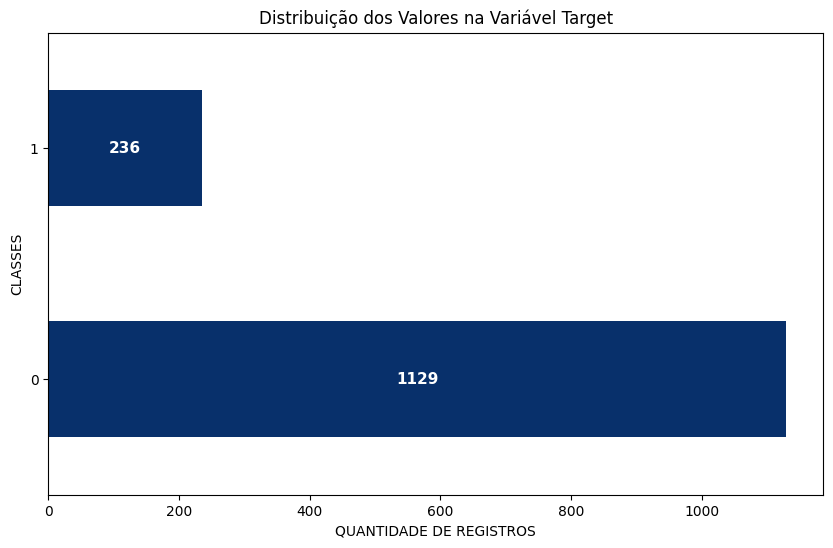

In [139]:
# verificar se a variável target está balanceada
fig, ax = plt.subplots(figsize=(10, 6))

contagem = (
    df_longitudinal["defasou_ano_seguinte"]
    .value_counts()
    .sort_index()
)

contagem.plot(
    kind="barh",
    color="#08306B",
    ax=ax
)

ax.bar_label(
    ax.containers[0],
    fmt="%d",
    label_type="center",
    color="white",
    fontsize=11,
    fontweight="bold"
)

plt.title("Distribuição dos Valores na Variável Target")
plt.xlabel("QUANTIDADE DE REGISTROS")
plt.ylabel("CLASSES")

plt.show()


**Conclusão do gráfico:** há muito mais amostras de alunos que não defasaram do que defasaram. Vou verificar como essa distribuição está em cada ano das amostras.

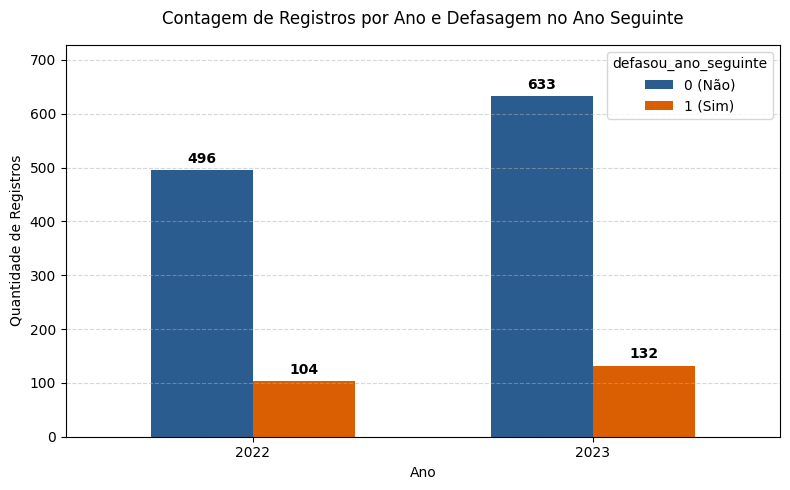

In [140]:
contagem = df_longitudinal.groupby(['Ano', 'defasou_ano_seguinte']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(8, 5))
contagem.plot(kind='bar', ax=ax, width=0.6, color=['#2b5c8f', '#d95f02'])

plt.title('Contagem de Registros por Ano e Defasagem no Ano Seguinte', fontsize=12, pad=15)
plt.xlabel('Ano', fontsize=10)
plt.ylabel('Quantidade de Registros', fontsize=10)
plt.xticks(rotation=0)
plt.legend(title='defasou_ano_seguinte', labels=['0 (Não)', '1 (Sim)'])
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Aumenta a margem do eixo Y em 15% para que os rótulos fiquem bem visíveis
ax.margins(y=0.15)

# Adiciona os rótulos de contagem
for p in ax.patches:
    val = int(p.get_height())
    if val > 0:
        ax.annotate(f'{val}',
                    (p.get_x() + p.get_width() / 2., val),
                    ha='center', va='bottom',
                    xytext=(0, 3), textcoords='offset points',
                    fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

**Conclusão do gráfico:** apesar das classes estarem em uma quantidade desproporcionais, as proporções dos valores da target está balanceada entre os anos.

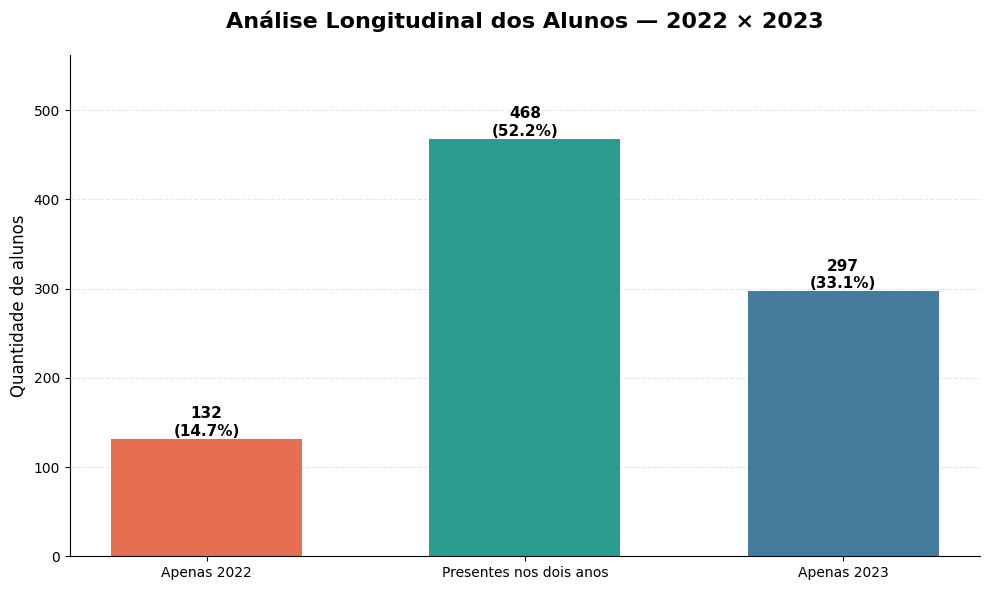

In [141]:
# quero visualizar quantos alunos tem registros:
# - Somente em 2022
# - Somente em 2023
# - Em ambos os anos

# conjuntos de alunos (RA) em cada período
ra_2022 = set(
    df_longitudinal.loc[
        df_longitudinal["Ano"] == 2022, "RA"
    ].dropna().unique()
)

ra_2023 = set(
    df_longitudinal.loc[
        df_longitudinal["Ano"] == 2023, "RA"
    ].dropna().unique()
)

# alunos que aparecem nos dois períodos
ra_ambos = ra_2022.intersection(ra_2023)

# alunos exclusivos de cada período
ra_apenas_2022 = ra_2022 - ra_2023
ra_apenas_2023 = ra_2023 - ra_2022

# quantidades
n_2022 = len(ra_2022)
n_2023 = len(ra_2023)
n_ambos = len(ra_ambos)
n_apenas_2022 = len(ra_apenas_2022)
n_apenas_2023 = len(ra_apenas_2023)

# categorias do gráfico
categorias = [
    "Apenas 2022",
    "Presentes nos dois anos",
    "Apenas 2023"
]

quantidades = [
    n_apenas_2022,
    n_ambos,
    n_apenas_2023
]

# percentuais em relação ao total de alunos únicos dos dois anos
total_alunos = len(ra_2022.union(ra_2023))

percentuais = [
    n_apenas_2022 / total_alunos * 100 if total_alunos > 0 else 0,
    n_ambos / total_alunos * 100 if total_alunos > 0 else 0,
    n_apenas_2023 / total_alunos * 100 if total_alunos > 0 else 0
]


fig, ax = plt.subplots(figsize=(10, 6))
cores = [
    "#E76F51",  # laranja/vermelho - apenas 2022
    "#2A9D8F",  # verde - ambos
    "#457B9D"   # azul - apenas 2023
]
barras = ax.bar(
    categorias,
    quantidades,
    color=cores,
    width=0.6
)
for barra, quantidade, percentual in zip(
    barras, quantidades, percentuais
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"{quantidade:,}\n({percentual:.1f}%)".replace(",", "."),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )
ax.set_title(
    "Análise Longitudinal dos Alunos — 2022 × 2023",
    fontsize=16,
    fontweight="bold",
    pad=20
)
ax.set_ylabel(
    "Quantidade de alunos",
    fontsize=12
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)
ax.set_axisbelow(True)
ax.set_ylim(0, max(quantidades) * 1.2 if max(quantidades) > 0 else 1)
plt.tight_layout()
plt.show()


In [142]:
# agora, para ter certeza, vou checar que nenhum aluno está aparecendo mais de
# uma vez em um ano

# quantidade de registros por aluno e ano
duplicidades = (
    df_longitudinal
    .groupby(["Ano", "RA"])
    .size()
    .reset_index(name="n_registros")
)

# apenas alunos com mais de um registro no mesmo ano
duplicidades = duplicidades[
    duplicidades["n_registros"] > 1
]

print(f"Quantidade de RA/Ano com múltiplos registros: {len(duplicidades)}")

print("\nQuantidade máxima de registros para um mesmo RA/Ano:")
print(
    duplicidades["n_registros"].max()
    if len(duplicidades) > 0
    else 1
)

print("\nPrimeiros casos:")
print(duplicidades.head(20))

Quantidade de RA/Ano com múltiplos registros: 0

Quantidade máxima de registros para um mesmo RA/Ano:
1

Primeiros casos:
Empty DataFrame
Columns: [Ano, RA, n_registros]
Index: []


**Conclusão do análise:** como esperado, nenhum aluno tem mais de um registro em um ano.

In [143]:
# verificar se há alguma variável sem valores distintos, ou seja, se a coluna
# tem o mesmo valor para todas as linhas.

df_longitudinal.nunique()

,0
RA,897
Nome,897
Ano,2
Gênero,2
Idade,19
Ano ingresso,8
Fase_num,9
Nº Av,3
IAA,37
IDA,87


**Conclusão da análise:** apenas para checar e confirmar. Nenhuma feature precisará ser dropada por não possui valores distintos.

In [144]:
df_longitudinal.columns

Index(['RA', 'Nome', 'Ano', 'Gênero', 'Idade', 'Ano ingresso', 'Fase_num', 'Nº Av', 'IAA', 'IDA', 'IEG', 'IPP', 'IPS', 'IPV', 'Defasagem', 'Pedra 21', 'Pedra_atual', 'INDE_atual', 'ano_seguinte', 'defasagem_ano_seguinte', 'defasou_ano_seguinte'], dtype='object')

In [145]:
import seaborn as sns

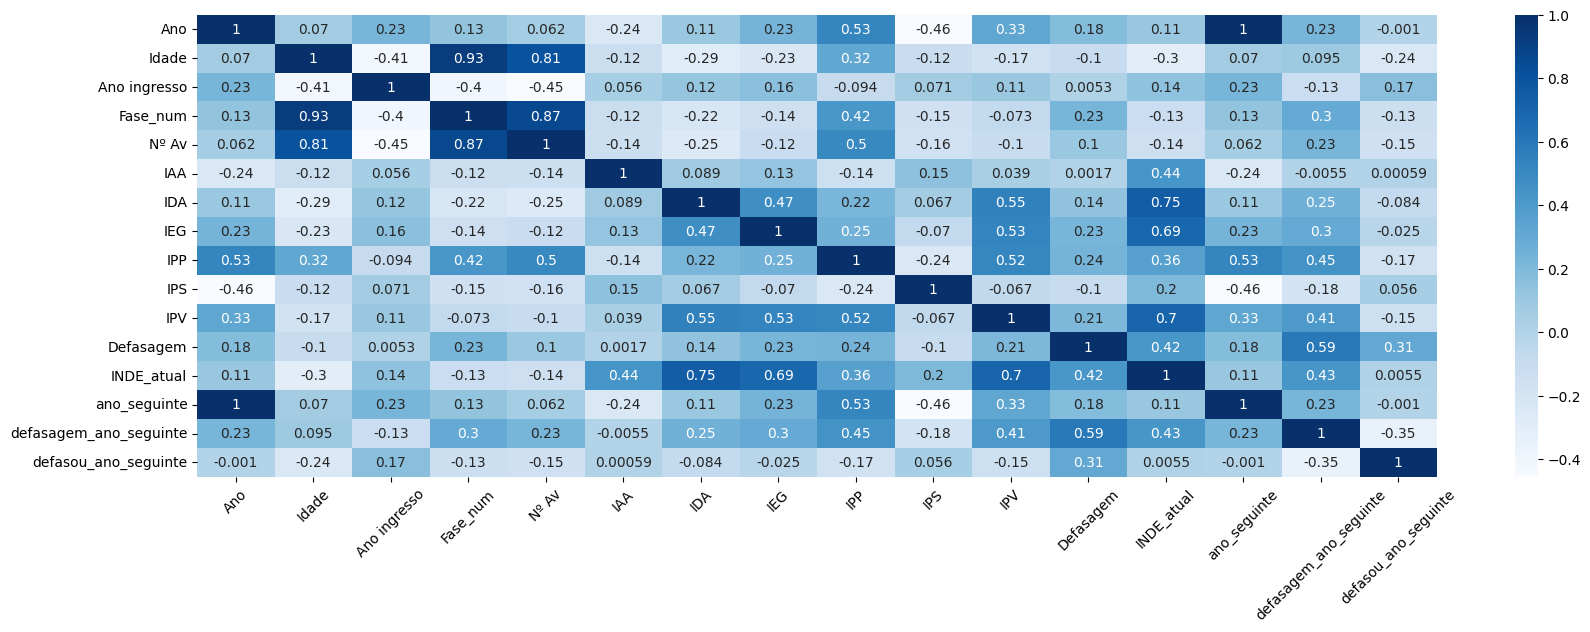

In [146]:
# vou verificar se alguma variável tem alta correlação com outra variável.

df_variaveis_continuas = df_longitudinal[[
    'Ano',
    'Idade',
    'Ano ingresso',
    'Fase_num',
    'Nº Av',
    'IAA',
    'IDA',
    'IEG',
    'IPP',
    'IPS',
    'IPV',
    'Defasagem',
    'INDE_atual',
    'ano_seguinte',
    'defasagem_ano_seguinte',
    'defasou_ano_seguinte'

]]

corr = df_variaveis_continuas.corr()
plt.figure(figsize = (20,6))
sns.heatmap(corr, cmap="Blues", annot=True)
plt.xticks(rotation=45)
plt.show()

**Conclusão geral:** a base de dados tem proporções desbalanceadas em relação a variável target, mas possui balanceamento da quantidade de registros por ano. Por conta deste desbalanceamento provavelmente modelos baseados em árvores de decisão devem ter uma performance melhor.

## ETAPA 6: Feature engineering

Para agregar ao modelo, vou seguir conceitos aprendidos ao longo do curso, de que em casos que envolvem linha do tempo, quaisquer novas features que se possa criar com dados do passado, desde que não sejam redundantes, podem ajudar no desempenho do modelo, e que dados do futuro não devem ser atribuídos ao modelo, para não gerar data leakage, portanto, seguindo este conceitos, nesta etapa irei criar as seguintes features:
* "status_historico"
* "Pedra_anterior"

"status_historico" (condição -> valor recebido):
* Aluno possui registro de ano anterior e possui valor da Pedra daquele ano anterior -> "Com histórico"
* Aluno possui registro de ano anterior e NÃO possui valor da Pedra daquele ano anterior -> "Dado anterior ausente"
* Aluno não possui registro de anterior, ou seja, aluno ingressou naquele ano avaliado -> "Novo aluno"

"Pedra_anterior" (condição -> valor recebido):
* Aluno possui registro de ano anterior e possui valor da Pedra daquele ano anterior -> recebe valor da Pedra do ano anterior
* Não atendeu a condição inicial -> recebe valor nulo

Essa informação é possível para talbém alunos de 2022 por causa da coluna "Pedra 21".

Posteriormente na etapa da pipeline, a coluna de "status_historico" e "Pedra_anterior" irão ser transformada por OneHotEncoding.

In [147]:
df_longitudinal.columns

Index(['RA', 'Nome', 'Ano', 'Gênero', 'Idade', 'Ano ingresso', 'Fase_num', 'Nº Av', 'IAA', 'IDA', 'IEG', 'IPP', 'IPS', 'IPV', 'Defasagem', 'Pedra 21', 'Pedra_atual', 'INDE_atual', 'ano_seguinte', 'defasagem_ano_seguinte', 'defasou_ano_seguinte'], dtype='object')

In [148]:
# só vou confirmar que a coluna "Ano ingresso" não tem nulos
df_longitudinal['Ano ingresso'].isna().sum()

np.int64(0)

In [149]:
# vou criar a feature da Pedra do ano anterior do aluno
df_longitudinal["Pedra_anterior"] = "Sem histórico"

# os alunos de 2022 devem receber da coluna "Pedra 21" o valor da Pedra do ano anterior
mask_2022 = df_longitudinal["Ano"] == 2022

# preencher valores ausentes com "Sem histórico"
df_longitudinal.loc[mask_2022, "Pedra_anterior"] = (
    df_longitudinal.loc[mask_2022, "Pedra 21"]
    .fillna("Sem histórico")
)

pedra_anterior = (
    df_longitudinal[["RA", "Ano", "Pedra_atual"]]
    .copy()
)

pedra_anterior["Ano"] = pedra_anterior["Ano"] + 1

pedra_anterior = pedra_anterior.rename(
    columns={
        "Pedra_atual": "Pedra_anterior_2023"
    }
)

df_longitudinal = df_longitudinal.merge(
    pedra_anterior[["RA", "Ano", "Pedra_anterior_2023"]],
    on=["RA", "Ano"],
    how="left"
)

# os alunos de 2023 vão receber esse valor do seu registro de 2022
mask_2023 = df_longitudinal["Ano"] == 2023

df_longitudinal.loc[mask_2023, "Pedra_anterior"] = (
    df_longitudinal.loc[mask_2023, "Pedra_anterior_2023"]
)

# preencher valores ausentes com "Sem histórico"
df_longitudinal["Pedra_anterior"] = (
    df_longitudinal["Pedra_anterior"]
    .fillna("Sem histórico")
)

# remover a coluna auxiliar, não será mais necessária
df_longitudinal = df_longitudinal.drop(
    columns=["Pedra_anterior_2023"]
)


In [150]:
# visualizar amostras para ver as mudanças
df_longitudinal.sample(10)

,RA,Nome,Ano,Gênero,Idade,Ano ingresso,Fase_num,Nº Av,IAA,IDA,IEG,IPP,IPS,IPV,Defasagem,Pedra 21,Pedra_atual,INDE_atual,ano_seguinte,defasagem_ano_seguinte,defasou_ano_seguinte,Pedra_anterior
533,RA-382,Aluno-382,2023,Masculino,15,2017,3,4,0.0,5.2,9.4,7.500000,6.26,7.1725,-2,Ágata,Ágata,6.223833,2024.0,-1.0,0,Ágata
357,RA-236,Aluno-236,2022,Feminino,12,2022,3,4,9.6,3.7,7.5,7.184000,7.50,7.2080,0,NaN,Ametista,7.110000,2023.0,0.0,0,Sem histórico
590,RA-418,Aluno-418,2023,Feminino,11,2020,3,4,8.8,8.1,10.0,8.125000,2.52,8.0450,1,Topázio,Topázio,8.168600,2024.0,1.0,0,Topázio
1292,RA-92,Aluno-92,2023,Feminino,17,2016,6,4,9.6,6.7,9.4,7.187500,5.63,7.0450,-1,Ametista,Ametista,7.375917,2024.0,0.0,0,Ágata
720,RA-513,Aluno-513,2023,Masculino,10,2021,2,3,9.5,7.5,9.7,8.541667,2.52,9.0075,0,Topázio,Topázio,8.297867,2024.0,1.0,0,Topázio
562,RA-401,Aluno-401,2022,Feminino,12,2021,2,3,6.9,4.3,9.6,5.806000,7.50,6.7220,-1,Quartzo,Ágata,6.645000,2023.0,-1.0,0,Quartzo
295,RA-178,Aluno-178,2023,Feminino,14,2016,4,4,7.9,5.9,8.7,7.656250,2.52,8.4200,0,Ametista,Ametista,7.406658,2024.0,0.0,0,Ágata
161,RA-12,Aluno-12,2022,Feminino,17,2020,7,4,0.0,1.5,4.0,7.642000,6.90,6.3890,0,Ágata,Quartzo,4.832000,2023.0,0.0,0,Ágata
406,RA-276,Aluno-276,2022,Feminino,14,2017,3,4,7.1,4.3,5.7,7.320000,5.60,5.1250,-1,Quartzo,Quartzo,5.527000,2023.0,0.0,0,Quartzo
617,RA-434,Aluno-434,2022,Masculino,11,2022,2,3,9.0,5.7,8.1,6.374000,7.50,6.7780,0,NaN,Ametista,7.403000,2023.0,-1.0,1,Sem histórico


In [151]:
df_longitudinal = df_longitudinal[['RA', 'Nome', 'Ano', 'Gênero', 'Idade', 'Ano ingresso', 'Fase_num', 'Nº Av', 'IAA', 'IDA', 'IEG', 'IPP', 'IPS', 'IPV', 'Pedra_anterior', 'Defasagem', 'INDE_atual', 'defasou_ano_seguinte']]

In [152]:
df_longitudinal.columns

Index(['RA', 'Nome', 'Ano', 'Gênero', 'Idade', 'Ano ingresso', 'Fase_num', 'Nº Av', 'IAA', 'IDA', 'IEG', 'IPP', 'IPS', 'IPV', 'Pedra_anterior', 'Defasagem', 'INDE_atual', 'defasou_ano_seguinte'], dtype='object')

## ETAPA 7: Pipeline

 A pipeline dos dados consistirá em:
1) gerar a feature "tempo_de_projeto" a partir de dados que já devem ser préviamente inputados. Essa feature será para tentar agregar ao modelo e consiste ao tempo total que o aluno faz parte da Passos Mágicos;
2) preencher os valores nulos da coluna "INDE_anterior" com o valor da mediana dos INDE disponíveis;
3) excluir as features que não devem ir para modelo
4) aplicar a técnica de One-Hot Encoding para as variáveis qualitativas que não possuem ordem;
5) deixar as variáveis numéricas na mesma escala;
6) transformar em binário as colunas que possuem apenas dois tipos de valores possíveis.




In [153]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler
from sklearn.utils.validation import check_is_fitted

In [154]:
# classe para criar a feature de tempo total que o aluno participa das Passos
# Mágicos
class CreateTempoPrograma(BaseEstimator, TransformerMixin):

    def fit(self, df, y=None):
        return self

    def transform(self, df):
        df = df.copy()

        df["Tempo_programa"] = (
            df["Ano"] - df["Ano ingresso"]
        )

        return df

In [155]:
class CreateStatusHistorico(BaseEstimator, TransformerMixin):

    def fit(self, df, y=None):
        return self

    def transform(self, df):

        df = df.copy()

        df["status_historico"] = np.where(
            df["Ano ingresso"] == df["Ano"],
            "Novo aluno",
            np.where(
                df["Pedra_anterior"] != "Sem histórico",
                "Com histórico",
                "Sem histórico"
            )
        )

        return df

**Decisões e justificativas das features que NÃO serão usadas no modelo**:
* **RA, Nome, Ano**: serão mantidos apenas para rastrear alunos e validar resultados
* **Ano ingresso**: uma nova feature que possui uma interpretação mais útil e comparável entre os períodos será originada dessa feature, por isso ela não vai para o modelo.
* **Gênero**: será preservada porque pode ser usada para análise exploratória e futura avaliação de desempenho do modelo entre grupos, porém, ela não será utilizada inicialmente como variável preditora. Esse tipo de característica pessoal não afeta diretamente para definir o risco educacional.


In [156]:
# classe para excluir as variáveis que não irão para o modelo
class DropFeatures(BaseEstimator, TransformerMixin):
    def __init__(
        self,
        feature_to_drop=None
    ):
        if feature_to_drop is None:
            feature_to_drop = [
                'RA',
                'Nome',
                'Ano',
                'Ano ingresso',
                'Gênero',
            ]

        self.feature_to_drop = feature_to_drop

    def fit(self, df, y=None):
        return self

    def transform(self, df):

        df = df.copy()

        return df.drop(
            columns=self.feature_to_drop,
            errors='ignore'
        )

In [157]:
# classe para preencher os valores nulos com a mediana nas features dos indicadores
# e da quantidade de avaliadores.
class FillMissingWithMedian(BaseEstimator, TransformerMixin):

    def __init__(self, colunas=None):
        if colunas is None:
            colunas = ['Nº Av', 'IAA', 'IDA', 'IEG', 'IPP', 'IPS', 'IPV', 'INDE_atual']

        self.colunas = colunas

    def fit(self, df, y=None):

        # calcula as medianas SOMENTE nos dados usados no fit
        # no treinamento normal: somente 2022
        # na validação cruzada: somente o fold de treino
        self.medianas_ = (
            df[self.colunas]
            .median()
        )

        return self

    def transform(self, df):

        df = df.copy()

        df[self.colunas] = (
            df[self.colunas]
            .fillna(self.medianas_)
        )

        return df

In [158]:
# classe para deixar as variáveis na mesma escala
class StandardScalerFeatures(BaseEstimator, TransformerMixin):
    def __init__(
        self,
        colunas_escala=None
    ):
        if colunas_escala is None:
            colunas_escala = [
                'Idade',
                'Fase_num',
                'Nº Av',
                'IAA',
                'IDA',
                'IEG',
                'IPP',
                'IPS',
                'IPV',
                'Defasagem',
                'INDE_atual',
                'Tempo_programa'
            ]

        self.colunas_escala = colunas_escala
        self.scaler = StandardScaler()

    def fit(self, df, y=None):

        self.scaler.fit(
            df[self.colunas_escala]
        )

        return self

    def transform(self, df):

        df = df.copy()

        df[self.colunas_escala] = (
            self.scaler.transform(
                df[self.colunas_escala]
            )
        )

        return df

In [159]:
# classe para aplicar a técnica de OneHotEnconding
class OneHotEncodingNames(BaseEstimator, TransformerMixin):
    def __init__(
        self,
        OneHotEncoding=None
    ):
        if OneHotEncoding is None:
            OneHotEncoding = [
                'Pedra_anterior',
                'status_historico'
            ]

        self.OneHotEncoding = OneHotEncoding

        self.encoder = OneHotEncoder(
            sparse_output=False,
            handle_unknown='ignore'
        )

    def fit(self, df, y=None):

        self.encoder.fit(
            df[self.OneHotEncoding]
        )

        # informa ao sklearn que este transformer foi ajustado
        self.is_fitted_ = True

        return self

    def transform(self, df):

        check_is_fitted(self, "is_fitted_")

        df = df.copy()

        encoded = self.encoder.transform(
            df[self.OneHotEncoding]
        )

        nomes = self.encoder.get_feature_names_out(
            self.OneHotEncoding
        )

        encoded = pd.DataFrame(
            encoded,
            columns=nomes,
            index=df.index
        )

        df = df.drop(
            columns=self.OneHotEncoding
        )

        df = pd.concat(
            [df, encoded],
            axis=1
        )

        return df

In [160]:
# montar a pipeline com as classes criadas
from sklearn.pipeline import Pipeline

In [161]:
pipeline = Pipeline([
    ('create_tempo_programa', CreateTempoPrograma()),
    ('create_status_historico', CreateStatusHistorico()),
    ('feature_dropper', DropFeatures()),
    ('fill_missing_median', FillMissingWithMedian()),
    ('standard_scaler', StandardScalerFeatures()),
    ('OneHotEncoding', OneHotEncodingNames()),
])

## ETAPA 8: Split de treino e teste

In [162]:
# split temporal = registros de 2022 para treino, e os registros de 2023 para teste
train = df_longitudinal[df_longitudinal["Ano"] == 2022].copy()
test = df_longitudinal[df_longitudinal["Ano"] == 2023].copy()

In [163]:
TARGET = "defasou_ano_seguinte"

# separar features e target ANTES do pré-processamento
X_train_raw = train.drop(columns=[TARGET])
y_treino = train[TARGET]

X_test_raw = test.drop(columns=[TARGET])
y_teste = test[TARGET]

In [164]:
# aplicar as transformações da pipeline no dataset
pipeline.fit(X_train_raw)

X_treino = pipeline.transform(X_train_raw)
X_teste = pipeline.transform(X_test_raw)

In [165]:
# visualizar se a pipeline está funcionando e se deu certo as transformações no dataset
X_treino.head()

,Idade,Fase_num,Nº Av,IAA,IDA,IEG,IPP,IPS,IPV,Defasagem,INDE_atual,Tempo_programa,Pedra_anterior_Ametista,Pedra_anterior_Quartzo,Pedra_anterior_Sem histórico,Pedra_anterior_Topázio,Pedra_anterior_Ágata,status_historico_Com histórico,status_historico_Novo aluno
0,2.660187,2.880233,1.327656,-0.078490,-1.305248,-3.078202,1.642106,-1.203140,-0.178129,-0.132688,-1.653344,2.405960,1.0,0.0,0.0,0.0,0.0,1.0,0.0
26,0.427862,1.169204,1.327656,-0.298042,0.440490,0.292493,1.712610,0.550798,0.255233,2.316930,0.943224,0.222033,1.0,0.0,0.0,0.0,0.0,1.0,0.0
36,2.288133,1.169204,1.327656,-0.298042,-1.463952,0.292493,0.637424,0.550798,-0.752585,-3.807114,-1.058949,-0.869931,0.0,0.0,1.0,0.0,0.0,0.0,1.0
49,1.171970,1.169204,1.327656,0.415503,0.493392,-0.220439,1.999914,2.304735,0.927448,-0.132688,0.793508,2.405960,1.0,0.0,0.0,0.0,0.0,1.0,0.0
61,1.171970,1.169204,1.327656,-0.517594,-0.987841,-1.392854,1.118614,0.550798,-0.962211,-0.132688,-1.122634,1.313996,0.0,0.0,0.0,0.0,1.0,1.0,0.0


## ETAPA 9: Treino e métricas de avaliação do modelo

Nesta etapa vou preparar a função que vai colocar o modelo de ML pra rodar e quais as métricas de desempenho ele vai retorar.

<br>

Métricas que vou utilizar:
  * **Curva ROC**: o quanto o modelo consegue distinguir as duas classes. Quanto mais próximo do 1 o valor do AUC for (ou, no gráfico, o quanto mais perto da esquerda a linha cresce antes da curva), mostra que o modelo está separando bem as classes.
  * **Matriz de Confusão**: ela mostra onde o modelo erra. Mostra a proporção de falsos positivos e falsos negativos que o modelo está classificando, ou seja, dá pra saber se o modelo tem a característica de preferir errar classificando como positivo ou ao contrário.
  * **Validação Cruzada**: mede se o modelo é estável ou não. (vou configurar o StratifiedKFold para dividir o df de treino em 5 partes, e veremos se em cada treino a taxa de acerto será próximas uma da outra, o que mostra que o modelo é estável, o se cada treino a acertivadade varia muito (modelo instável);
  * **Classification Report**:
    * **Precision**: dos que o modelo classificou como positivo, quanto ele realmente acertou.
    * **Recall**: da quantidade total de positivos, quanto o modelo acertou.
    * **F1-Score**: é o equilíbrio entre precision e recall, ou seja, um F1-Score alto mostra que o modelo está equilibrado, ele tanto é preciso (o que ele classifica como positivo, ele está acertando muito), e da quantidade total dos valores que são positivos, poucos ele está classificando como negativo (recall)
    * **Support**: não é uma métrica de desempenho, é apenas uma contagem, ele diz quantas amostras reais existem de cada classe no conjunto de teste.
    * **Accuracy**: a acurácia diz quanto que o modelo classificou corretamente, o quanto ele acertou.

In [166]:
# imports das classes de métricas de desempenho
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate

from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay,
    ConfusionMatrixDisplay,
    classification_report,
    precision_recall_curve,
    average_precision_score,
    auc,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score
)

from sklearn.base import clone

import warnings
warnings.filterwarnings("ignore")

In [167]:
# update: para conseguir aplicar o valor do threshold como parâmetro
def roda_modelo(modelo, threshold=0.50):
    modelo.fit(X_treino, y_treino)

    # Probabilidade de pertencer à classe positiva
    prob_predic = modelo.predict_proba(X_teste)[:, 1]

    # Aplicação manual do threshold
    y_pred = (prob_predic >= threshold).astype(int)

    print(f"\n{'='*78}")
    print(f"Modelo: {modelo.__class__.__name__}".center(78))
    print(f"Threshold utilizado: {threshold:.2f}".center(78))
    print(f"{'='*78}")

    # curva ROC
    print("\n- Curva ROC:")
    fig, ax = plt.subplots(figsize=(7, 7))
    RocCurveDisplay.from_predictions(
        y_teste,
        prob_predic,
        ax=ax
    )
    ax.set_title("Curva ROC", fontsize=15)
    plt.grid(True)
    plt.show()


    # curva precision-recall
    precision_curve, recall_curve, thresholds_pr = (
        precision_recall_curve(
            y_teste,
            prob_predic
        )
    )
    # área pelo método trapezoidal
    pr_auc = auc(
        recall_curve,
        precision_curve
    )
    # average Precision
    average_precision = average_precision_score(
        y_teste,
        prob_predic
    )
    print("\n- Curva Precision-Recall:")
    print(f"PR-AUC           : {pr_auc:.4f}")
    print(f"Average Precision: {average_precision:.4f}")
    fig, ax = plt.subplots(figsize=(7, 7))
    PrecisionRecallDisplay.from_predictions(
        y_teste,
        prob_predic,
        ax=ax
    )
    ax.set_title("Curva Precision-Recall", fontsize=15)
    plt.grid(True)
    plt.show()

    # matriz de confusão
    print(
        f"\n- Matriz de Confusão "
        f"(threshold = {threshold:.2f}):"
    )
    fig, ax = plt.subplots(figsize=(7, 7))
    ConfusionMatrixDisplay.from_predictions(
        y_teste,
        y_pred,
        normalize="true",
        display_labels=[
            "Não perdeu posição",
            "Perdeu posição"
        ],
        cmap=plt.cm.Blues,
        ax=ax
    )
    ax.set_title(
        "Matriz de Confusão\nNormalizada",
        fontsize=16,
        fontweight="bold"
    )
    ax.set_xlabel("Label predita", fontsize=18)
    ax.set_ylabel("Label verdadeira", fontsize=18)
    plt.grid(False)
    plt.show()

    # matriz de confusão
    skf = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    # A validação cruzada precisa executar TODA a cadeia de
    # pré-processamento dentro de cada fold.
    #
    # isso evita data leakage:
    # medianas e parâmetros de escala são aprendidos somente
    # no subconjunto de treino de cada fold.
    pipeline_cv = Pipeline([
        (
            'create_tempo_programa',
            CreateTempoPrograma()
        ),
        (
            'create_status_historico',
            CreateStatusHistorico()
        ),
        (
            'feature_dropper',
            DropFeatures()
        ),
        (
            'fill_missing_median',
            FillMissingWithMedian()
        ),
        (
            'standard_scaler',
            StandardScalerFeatures()
        ),
        (
            'OneHotEncoding',
            OneHotEncodingNames()
        ),

        # clone garante uma nova instância do modelo
        (
            'modelo',
            clone(modelo)
        )
    ])

    scoring = {
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc",
        "average_precision": "average_precision"
    }

    cv = cross_validate(
        pipeline_cv,
        X_train_raw,
        y_treino,
        cv=skf,
        scoring=scoring
    )

    print("\n- Validação Cruzada:")

    nomes_metricas = {
        "accuracy": "Accuracy",
        "balanced_accuracy": "Balanced Accuracy",
        "precision": "Precision",
        "recall": "Recall",
        "f1": "F1-Score",
        "roc_auc": "ROC-AUC",
        "average_precision": "Average Precision"
    }

    for metrica, nome in nomes_metricas.items():

        valores = cv[f"test_{metrica}"]

        print(f"\n{nome}:")
        print(f"  Folds : {valores}")
        print(f"  Média : {valores.mean():.4f}")
        print(f"  Desvio: {valores.std():.4f}")

    # classification report
    print(
        f"\n- Classification Report "
        f"(threshold = {threshold:.2f}):"
    )

    print(
        classification_report(
            y_teste,
            y_pred,
            target_names=[
                "Não perdeu posição",
                "Perdeu posição"
            ],
            zero_division=0
        )
    )

## ETAPA 10: Avaliação dos desempenhos e escolha do modelo

**Modelos escolhidos para testar inicialmente:**
  * Baseline
  * Logistic Regression
  * Random Forest Classifier
  * XGBoost
  * Light GBM


                           Modelo: DummyClassifier                            
                          Threshold utilizado: 0.50                           

- Curva ROC:


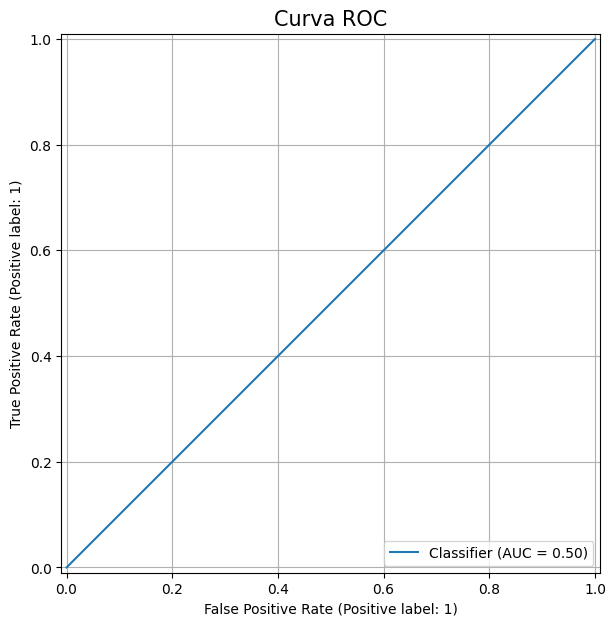


- Curva Precision-Recall:
PR-AUC           : 0.5863
Average Precision: 0.1725


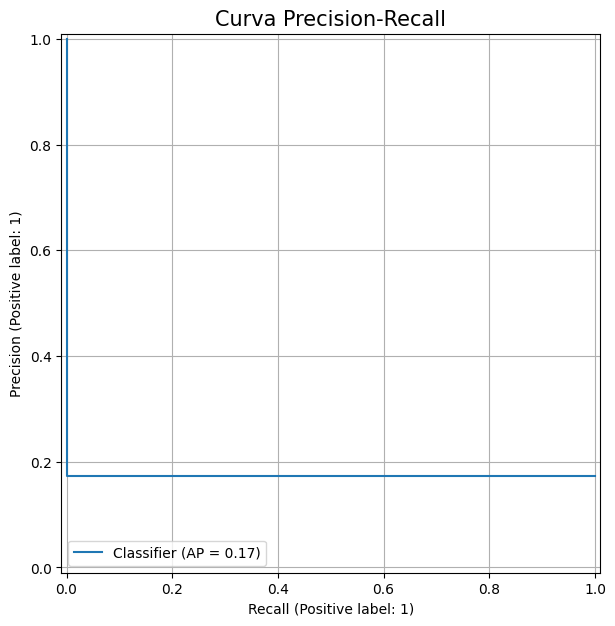


- Matriz de Confusão (threshold = 0.50):


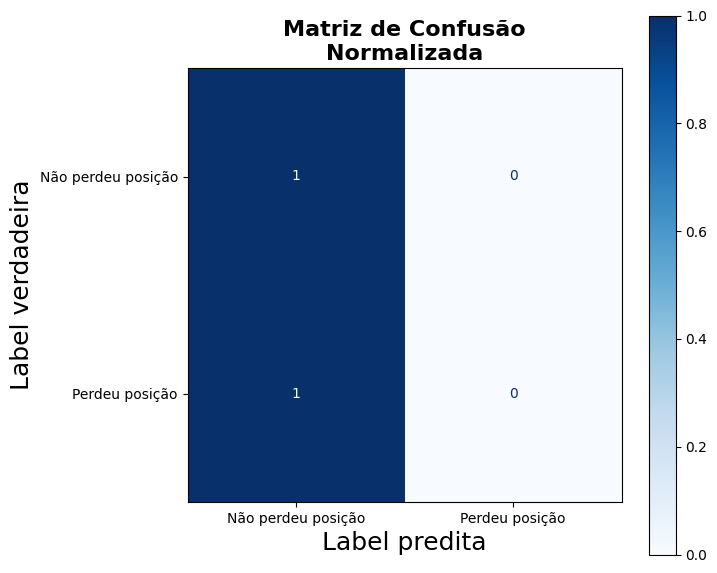


- Validação Cruzada:

Accuracy:
  Folds : [0.83333333 0.825      0.825      0.825      0.825     ]
  Média : 0.8267
  Desvio: 0.0033

Balanced Accuracy:
  Folds : [0.5 0.5 0.5 0.5 0.5]
  Média : 0.5000
  Desvio: 0.0000

Precision:
  Folds : [0. 0. 0. 0. 0.]
  Média : 0.0000
  Desvio: 0.0000

Recall:
  Folds : [0. 0. 0. 0. 0.]
  Média : 0.0000
  Desvio: 0.0000

F1-Score:
  Folds : [0. 0. 0. 0. 0.]
  Média : 0.0000
  Desvio: 0.0000

ROC-AUC:
  Folds : [0.5 0.5 0.5 0.5 0.5]
  Média : 0.5000
  Desvio: 0.0000

Average Precision:
  Folds : [0.16666667 0.175      0.175      0.175      0.175     ]
  Média : 0.1733
  Desvio: 0.0033

- Classification Report (threshold = 0.50):
                    precision    recall  f1-score   support

Não perdeu posição       0.83      1.00      0.91       633
    Perdeu posição       0.00      0.00      0.00       132

          accuracy                           0.83       765
         macro avg       0.41      0.50      0.45       765
      weighted avg   

In [168]:
from sklearn.dummy import DummyClassifier
modelo_baseline = DummyClassifier(strategy='most_frequent')
roda_modelo(modelo_baseline)

**Conclusões da performance do Baseline:**
* Baseline apenas para estabelecer a base mínima de acuracidade que os outros modelos devem bater: 83%


                          Modelo: LogisticRegression                          
                          Threshold utilizado: 0.50                           

- Curva ROC:


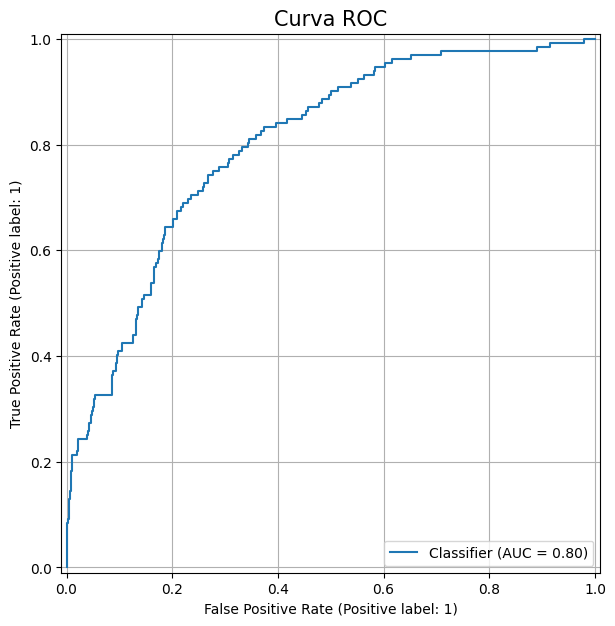


- Curva Precision-Recall:
PR-AUC           : 0.4929
Average Precision: 0.4957


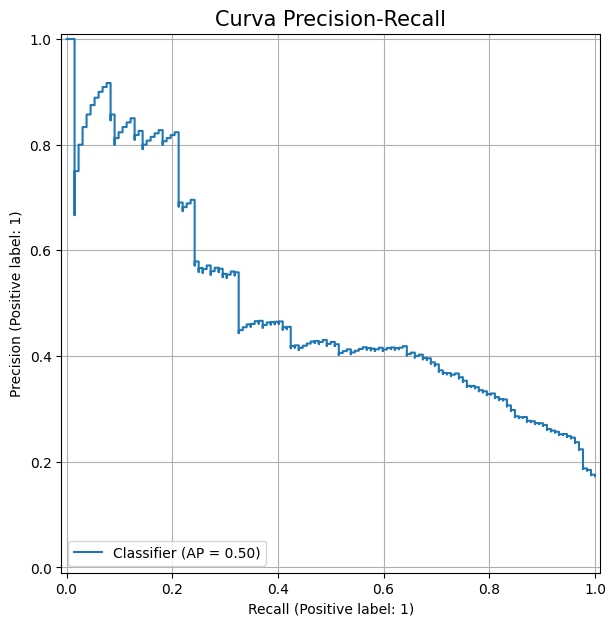


- Matriz de Confusão (threshold = 0.50):


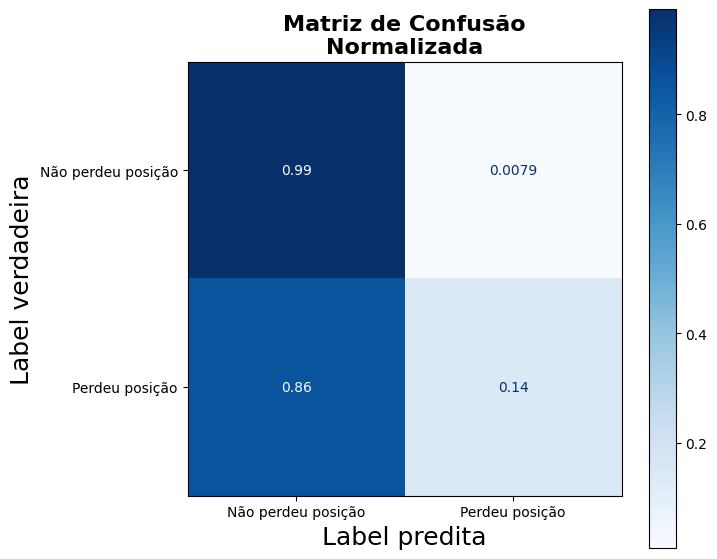


- Validação Cruzada:

Accuracy:
  Folds : [0.81666667 0.84166667 0.83333333 0.81666667 0.875     ]
  Média : 0.8367
  Desvio: 0.0215

Balanced Accuracy:
  Folds : [0.61       0.58513709 0.63636364 0.60750361 0.68037518]
  Média : 0.6239
  Desvio: 0.0326

Precision:
  Folds : [0.42857143 0.66666667 0.53846154 0.46153846 0.8       ]
  Média : 0.5790
  Desvio: 0.1375

Recall:
  Folds : [0.3        0.19047619 0.33333333 0.28571429 0.38095238]
  Média : 0.2981
  Desvio: 0.0630

F1-Score:
  Folds : [0.35294118 0.2962963  0.41176471 0.35294118 0.51612903]
  Média : 0.3860
  Desvio: 0.0746

ROC-AUC:
  Folds : [0.7855     0.83934584 0.82972583 0.74555075 0.92400192]
  Média : 0.8248
  Desvio: 0.0598

Average Precision:
  Folds : [0.49825592 0.51133011 0.48239942 0.39636748 0.77680449]
  Média : 0.5330
  Desvio: 0.1283

- Classification Report (threshold = 0.50):
                    precision    recall  f1-score   support

Não perdeu posição       0.85      0.99      0.91       633
    Perdeu p

In [169]:
from sklearn.linear_model import LogisticRegression
modelo_LogisticRegression = LogisticRegression(
    random_state=42,
    max_iter=1000
)
roda_modelo(modelo_LogisticRegression)

**Conclusões da performance do  Logistic Regression**:
* apresentou boa capacidade de separação (ROC-AUC 82%);
* baixo recall para a classe positiva.
* identificou apenas 14% dos alunos que defasou de fase, apesar da acuracidade de 79%.
* o modelo está conservador.


                        Modelo: RandomForestClassifier                        
                          Threshold utilizado: 0.50                           

- Curva ROC:


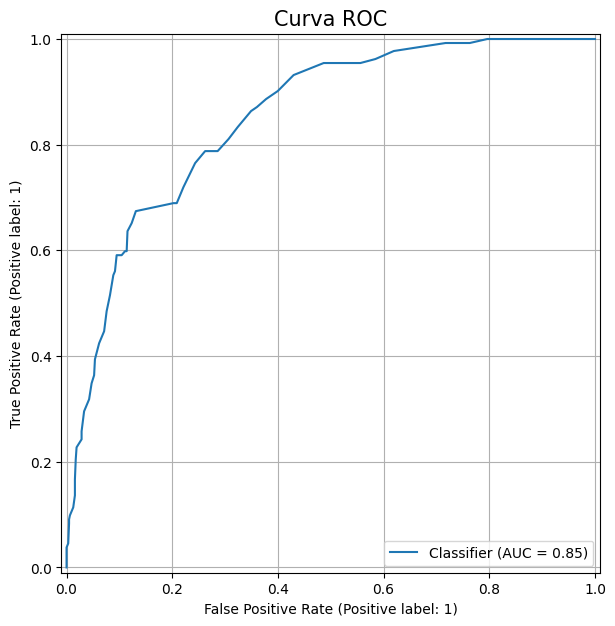


- Curva Precision-Recall:
PR-AUC           : 0.5481
Average Precision: 0.5450


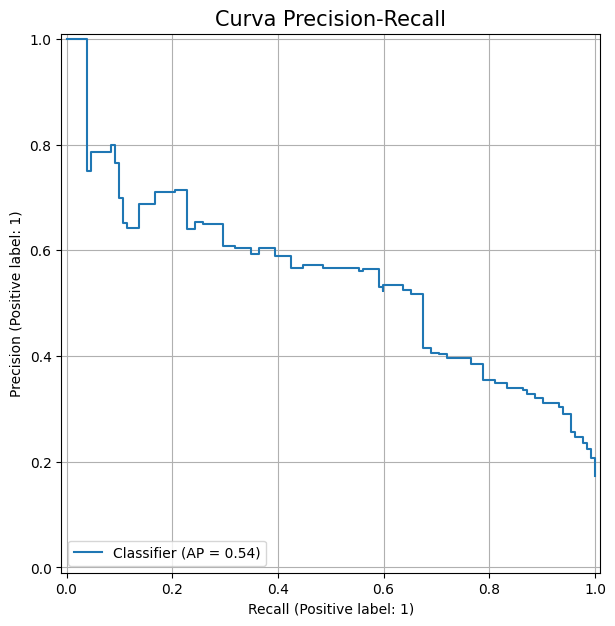


- Matriz de Confusão (threshold = 0.50):


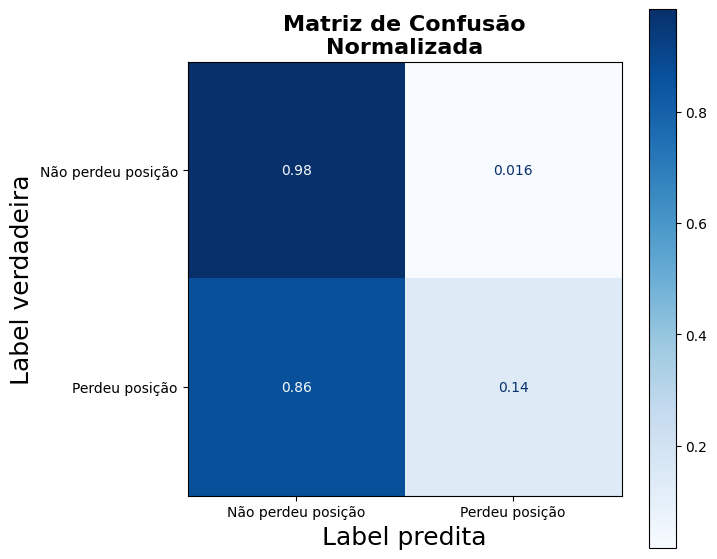


- Validação Cruzada:

Accuracy:
  Folds : [0.81666667 0.84166667 0.85833333 0.825      0.86666667]
  Média : 0.8417
  Desvio: 0.0190

Balanced Accuracy:
  Folds : [0.57       0.67893218 0.5952381  0.59379509 0.65656566]
  Média : 0.6189
  Desvio: 0.0415

Precision:
  Folds : [0.4        0.5625     1.         0.5        0.77777778]
  Média : 0.6481
  Desvio: 0.2152

Recall:
  Folds : [0.2        0.42857143 0.19047619 0.23809524 0.33333333]
  Média : 0.2781
  Desvio: 0.0906

F1-Score:
  Folds : [0.26666667 0.48648649 0.32       0.32258065 0.46666667]
  Média : 0.3725
  Desvio: 0.0875

ROC-AUC:
  Folds : [0.829      0.85257335 0.84944685 0.77368927 0.90572391]
  Média : 0.8421
  Desvio: 0.0426

Average Precision:
  Folds : [0.5015716  0.6092294  0.66886705 0.40707061 0.67903375]
  Média : 0.5732
  Desvio: 0.1043

- Classification Report (threshold = 0.50):
                    precision    recall  f1-score   support

Não perdeu posição       0.85      0.98      0.91       633
    Perdeu p

In [170]:
from sklearn.ensemble import RandomForestClassifier
modelo_RandomForest = RandomForestClassifier(
    random_state=42
)
roda_modelo(modelo_RandomForest)

**Conclusões da performance do Random Forest**:
* até que apresentou valores ok para a classe minoritária (alunos que defasaram), isso é bom, destaque para os valores de PR-AUC e Average Precision.


                            Modelo: XGBClassifier                             
                          Threshold utilizado: 0.50                           

- Curva ROC:


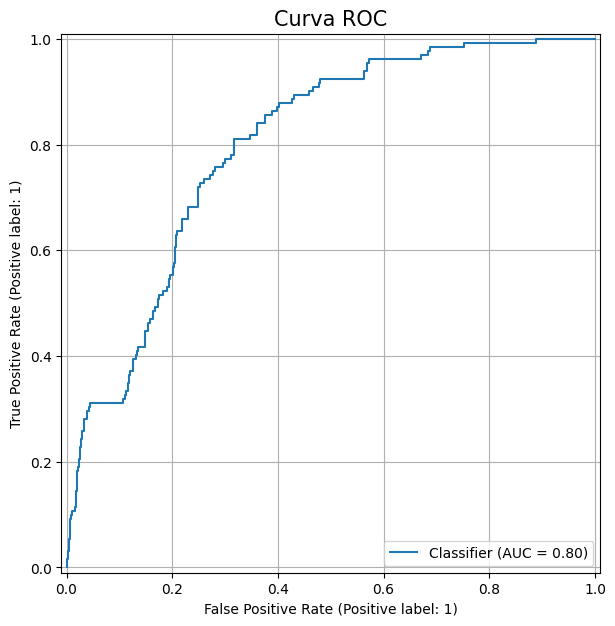


- Curva Precision-Recall:
PR-AUC           : 0.4346
Average Precision: 0.4408


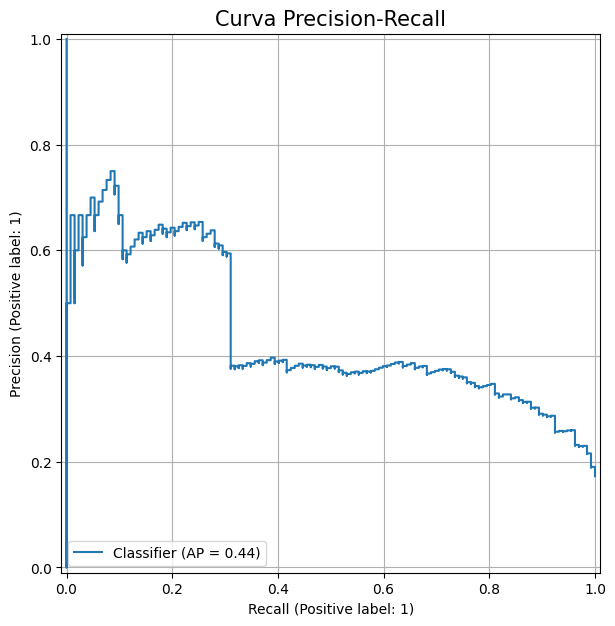


- Matriz de Confusão (threshold = 0.50):


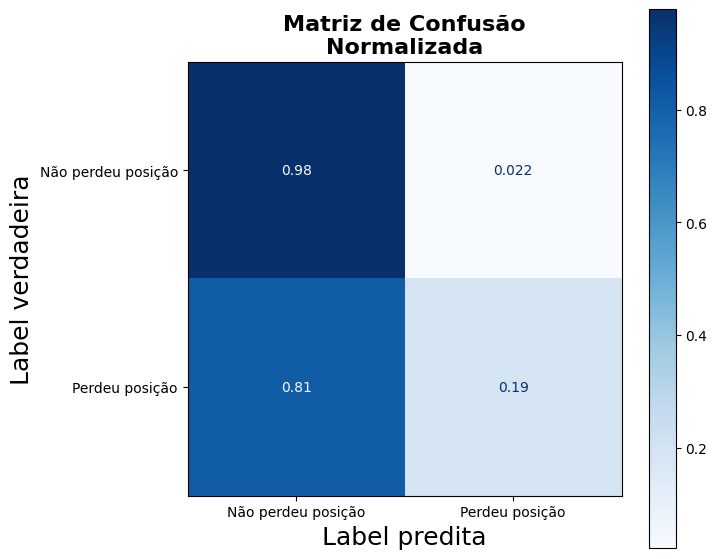


- Validação Cruzada:

Accuracy:
  Folds : [0.85833333 0.84166667 0.85833333 0.80833333 0.89166667]
  Média : 0.8517
  Desvio: 0.0271

Balanced Accuracy:
  Folds : [0.675      0.66017316 0.63275613 0.6024531  0.74675325]
  Média : 0.6634
  Desvio: 0.0485

Precision:
  Folds : [0.61538462 0.57142857 0.75       0.42857143 0.78571429]
  Média : 0.6302
  Desvio: 0.1287

Recall:
  Folds : [0.4        0.38095238 0.28571429 0.28571429 0.52380952]
  Média : 0.3752
  Desvio: 0.0880

F1-Score:
  Folds : [0.48484848 0.45714286 0.4137931  0.34285714 0.62857143]
  Média : 0.4654
  Desvio: 0.0946

ROC-AUC:
  Folds : [0.8305     0.87205387 0.80567581 0.75276575 0.89321789]
  Média : 0.8308
  Desvio: 0.0496

Average Precision:
  Folds : [0.5623536  0.57798941 0.58050604 0.39158967 0.62919714]
  Média : 0.5483
  Desvio: 0.0815

- Classification Report (threshold = 0.50):
                    precision    recall  f1-score   support

Não perdeu posição       0.85      0.98      0.91       633
    Perdeu p

In [171]:
from xgboost import XGBClassifier
modelo_xgboost = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)
roda_modelo(modelo_xgboost)

**Conclusões da performance do XGBoost**:
* apresentou os valores médios dos outros modelos testados, superou no valor de recall, mas no geral também acertou pouco dos alunos que desafasaram de fase.


                            Modelo: LGBMClassifier                            
                          Threshold utilizado: 0.50                           

- Curva ROC:


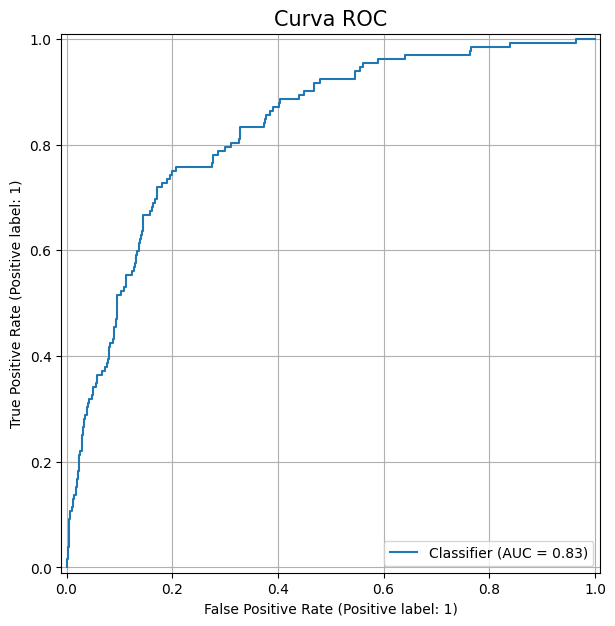


- Curva Precision-Recall:
PR-AUC           : 0.5051
Average Precision: 0.5087


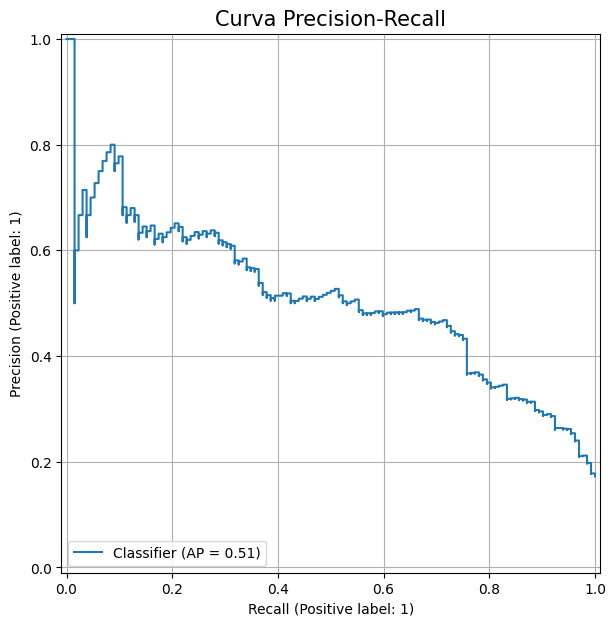


- Matriz de Confusão (threshold = 0.50):


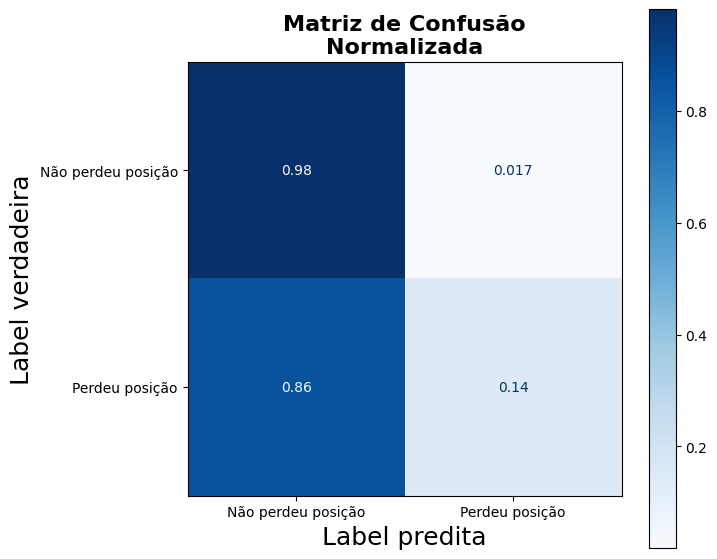


- Validação Cruzada:

Accuracy:
  Folds : [0.85833333 0.85       0.85       0.825      0.875     ]
  Média : 0.8517
  Desvio: 0.0162

Balanced Accuracy:
  Folds : [0.675      0.7027417  0.62770563 0.65007215 0.71789322]
  Média : 0.6747
  Desvio: 0.0331

Precision:
  Folds : [0.61538462 0.58823529 0.66666667 0.5        0.71428571]
  Média : 0.6169
  Desvio: 0.0727

Recall:
  Folds : [0.4        0.47619048 0.28571429 0.38095238 0.47619048]
  Média : 0.4038
  Desvio: 0.0707

F1-Score:
  Folds : [0.48484848 0.52631579 0.4        0.43243243 0.57142857]
  Média : 0.4830
  Desvio: 0.0619

ROC-AUC:
  Folds : [0.8385     0.87109187 0.82491582 0.74218374 0.9009139 ]
  Média : 0.8355
  Desvio: 0.0536

Average Precision:
  Folds : [0.53844448 0.57769395 0.55910797 0.38601299 0.61632971]
  Média : 0.5355
  Desvio: 0.0790

- Classification Report (threshold = 0.50):
                    precision    recall  f1-score   support

Não perdeu posição       0.85      0.98      0.91       633
    Perdeu p

In [172]:
from lightgbm import LGBMClassifier
modelo_lightgbm = LGBMClassifier(
    random_state=42,
    verbose=-1
)
roda_modelo(modelo_lightgbm, threshold=0.50)

**Conclusões da performance do LightGBM**:
* assim como os outros modelos, teve valores da maioria das métricas em uma média ok, mas acertou muito pouco dos casos positivos, menos que o XGBoost.
* os modelos estão favorecendo a classe majoritária.


___
**Como na base de dados a variável target tem um desbalanceamento grande entre as classes, vou testar os modelos com a configuração de balanceamento ativadas.**


                          Modelo: LogisticRegression                          
                          Threshold utilizado: 0.50                           

- Curva ROC:


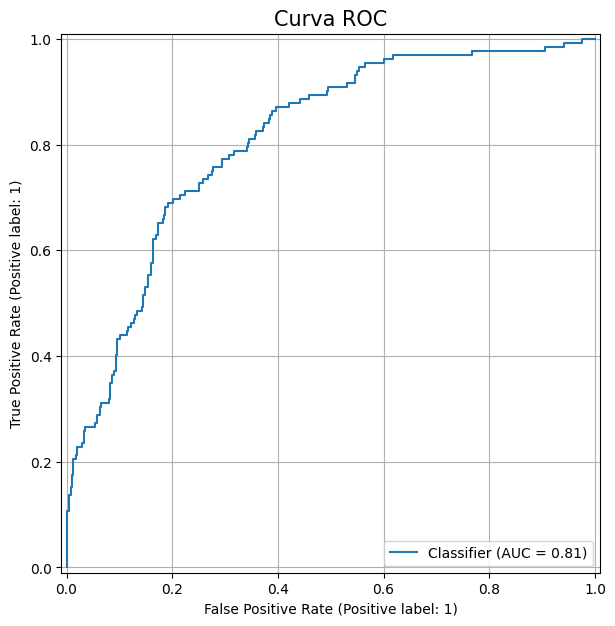


- Curva Precision-Recall:
PR-AUC           : 0.4926
Average Precision: 0.4961


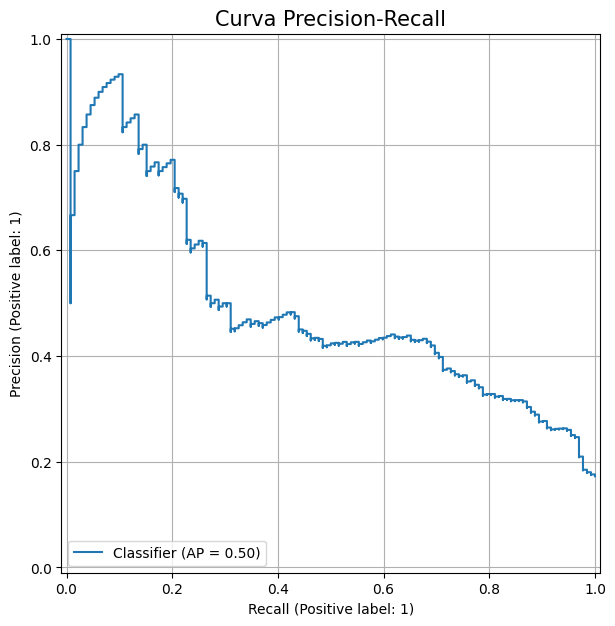


- Matriz de Confusão (threshold = 0.50):


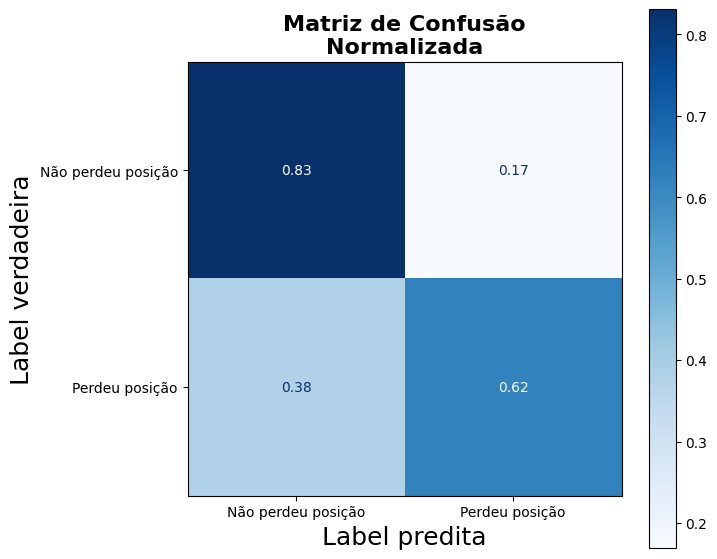


- Validação Cruzada:

Accuracy:
  Folds : [0.775      0.73333333 0.73333333 0.71666667 0.84166667]
  Média : 0.7600
  Desvio: 0.0452

Balanced Accuracy:
  Folds : [0.725      0.78210678 0.78210678 0.64069264 0.86652237]
  Média : 0.7593
  Desvio: 0.0745

Precision:
  Folds : [0.39393939 0.38297872 0.38297872 0.31428571 0.52777778]
  Média : 0.4004
  Desvio: 0.0697

Recall:
  Folds : [0.65       0.85714286 0.85714286 0.52380952 0.9047619 ]
  Média : 0.7586
  Desvio: 0.1468

F1-Score:
  Folds : [0.49056604 0.52941176 0.52941176 0.39285714 0.66666667]
  Média : 0.5218
  Desvio: 0.0880

ROC-AUC:
  Folds : [0.787      0.83982684 0.83164983 0.74025974 0.92159692]
  Média : 0.8241
  Desvio: 0.0604

Average Precision:
  Folds : [0.50279608 0.45785155 0.48134302 0.3379699  0.76835826]
  Média : 0.5097
  Desvio: 0.1414

- Classification Report (threshold = 0.50):
                    precision    recall  f1-score   support

Não perdeu posição       0.91      0.83      0.87       633
    Perdeu p

In [173]:
modelo_LogisticRegression_balanceado = LogisticRegression(
    random_state=42,
    max_iter=1000,
    class_weight="balanced"
)

roda_modelo(
    modelo_LogisticRegression_balanceado,
    threshold=0.50
)

**Conclusões da performance do LogisticRegression com o peso balanceado**:
* melhorou a identificação da classe positiva.
* os resultados das métricas de desempenho do modelo apresentaram um equilíbrio.


                        Modelo: RandomForestClassifier                        
                          Threshold utilizado: 0.50                           

- Curva ROC:


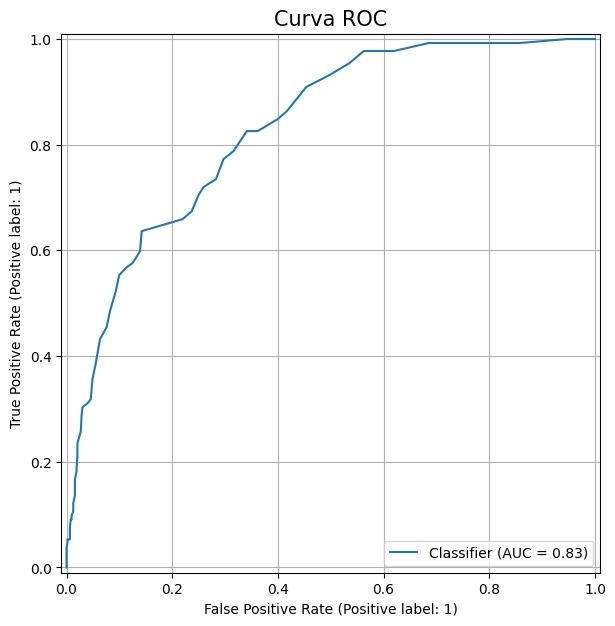


- Curva Precision-Recall:
PR-AUC           : 0.5236
Average Precision: 0.5205


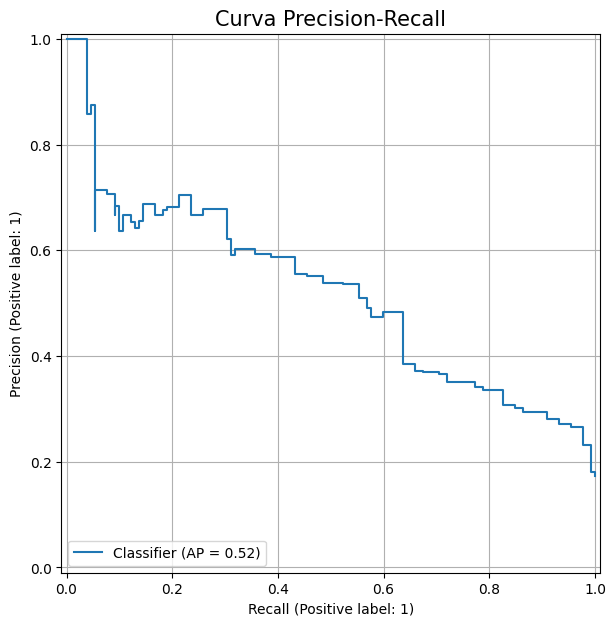


- Matriz de Confusão (threshold = 0.50):


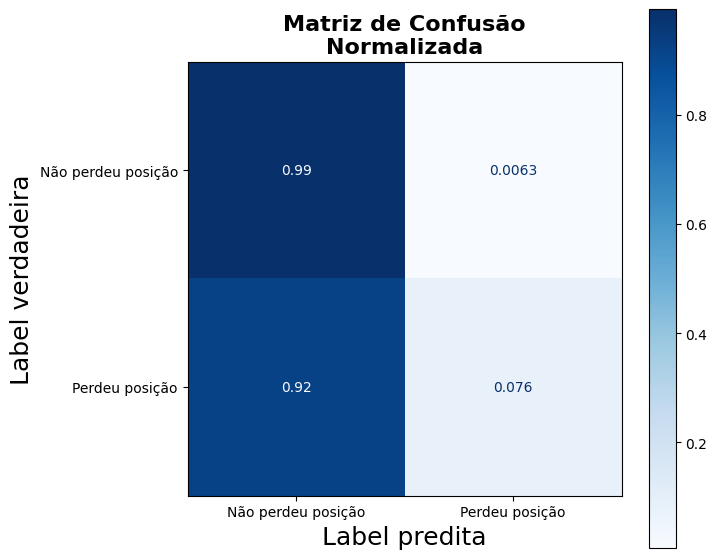


- Validação Cruzada:

Accuracy:
  Folds : [0.81666667 0.84166667 0.85833333 0.83333333 0.85833333]
  Média : 0.8417
  Desvio: 0.0158

Balanced Accuracy:
  Folds : [0.57       0.66017316 0.61399711 0.5988456  0.63275613]
  Média : 0.6152
  Desvio: 0.0305

Precision:
  Folds : [0.4        0.57142857 0.83333333 0.55555556 0.75      ]
  Média : 0.6221
  Desvio: 0.1532

Recall:
  Folds : [0.2        0.38095238 0.23809524 0.23809524 0.28571429]
  Média : 0.2686
  Desvio: 0.0624

F1-Score:
  Folds : [0.26666667 0.45714286 0.37037037 0.33333333 0.4137931 ]
  Média : 0.3683
  Desvio: 0.0656

ROC-AUC:
  Folds : [0.827      0.87181337 0.85810486 0.82515633 0.91726792]
  Média : 0.8599
  Desvio: 0.0338

Average Precision:
  Folds : [0.5068388  0.60011445 0.64110026 0.47917608 0.68884293]
  Média : 0.5832
  Desvio: 0.0793

- Classification Report (threshold = 0.50):
                    precision    recall  f1-score   support

Não perdeu posição       0.84      0.99      0.91       633
    Perdeu p

In [174]:
modelo_RandomForest_balanceado = RandomForestClassifier(
    random_state=42,
    class_weight="balanced"
)

roda_modelo(
    modelo_RandomForest_balanceado,
    threshold=0.50
)

**Conclusões da performance do RandomForest com o peso balanceado**:
* ainda está identificando muito pouco dos casos positivos, apenas 8%

In [175]:
# Para XGBoost e LightGBM calcular o peso a partir da própria distribuição do treino
qtd_classe_0 = (y_treino == 0).sum()
qtd_classe_1 = (y_treino == 1).sum()

peso_classe_positiva = qtd_classe_0 / qtd_classe_1

print("Peso da classe positiva:", peso_classe_positiva)

Peso da classe positiva: 4.769230769230769



                            Modelo: XGBClassifier                             
                          Threshold utilizado: 0.50                           

- Curva ROC:


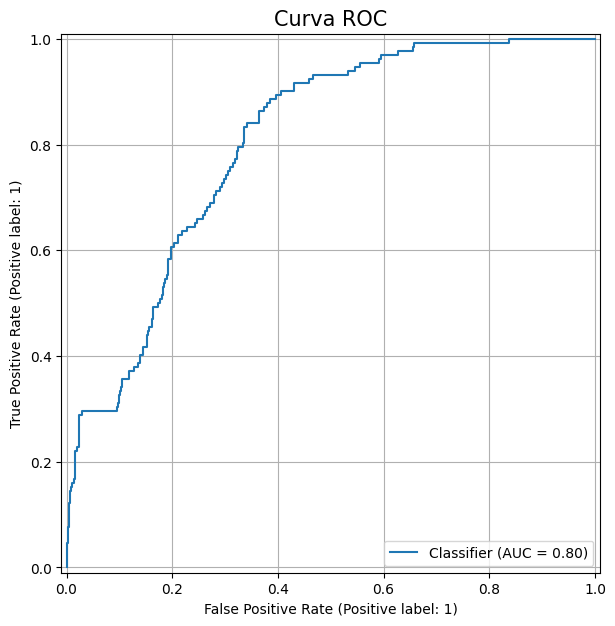


- Curva Precision-Recall:
PR-AUC           : 0.4685
Average Precision: 0.4721


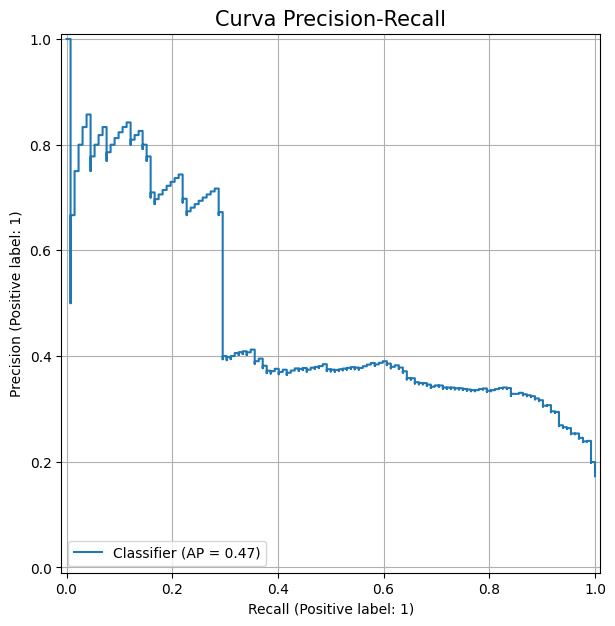


- Matriz de Confusão (threshold = 0.50):


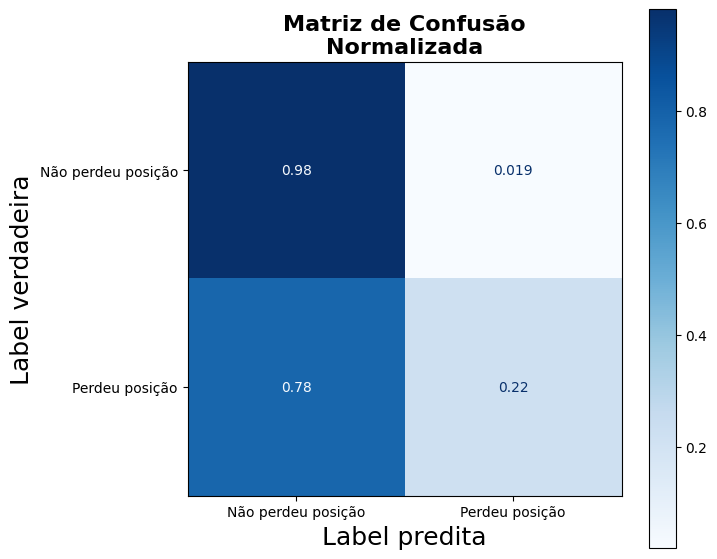


- Validação Cruzada:

Accuracy:
  Folds : [0.875      0.84166667 0.85833333 0.80833333 0.89166667]
  Média : 0.8550
  Desvio: 0.0287

Balanced Accuracy:
  Folds : [0.745      0.67893218 0.70779221 0.62121212 0.76551227]
  Média : 0.7037
  Desvio: 0.0509

Precision:
  Folds : [0.64705882 0.5625     0.625      0.4375     0.75      ]
  Média : 0.6044
  Desvio: 0.1030

Recall:
  Folds : [0.55       0.42857143 0.47619048 0.33333333 0.57142857]
  Média : 0.4719
  Desvio: 0.0861

F1-Score:
  Folds : [0.59459459 0.48648649 0.54054054 0.37837838 0.64864865]
  Média : 0.5297
  Desvio: 0.0930

ROC-AUC:
  Folds : [0.8535     0.85762386 0.85954786 0.75276575 0.8956229 ]
  Média : 0.8438
  Desvio: 0.0480

Average Precision:
  Folds : [0.5695231  0.59003615 0.64522379 0.4163079  0.64461518]
  Média : 0.5731
  Desvio: 0.0839

- Classification Report (threshold = 0.50):
                    precision    recall  f1-score   support

Não perdeu posição       0.86      0.98      0.92       633
    Perdeu p

In [176]:
modelo_xgboost_balanceado = XGBClassifier(
    random_state=42,
    eval_metric="logloss",
    scale_pos_weight=peso_classe_positiva
)

roda_modelo(
    modelo_xgboost_balanceado,
    threshold=0.50
)

**Conclusões da performance do XGBoost com o peso balanceado**:

* também continuou detectando poucos casos positivos;



                            Modelo: LGBMClassifier                            
                          Threshold utilizado: 0.50                           

- Curva ROC:


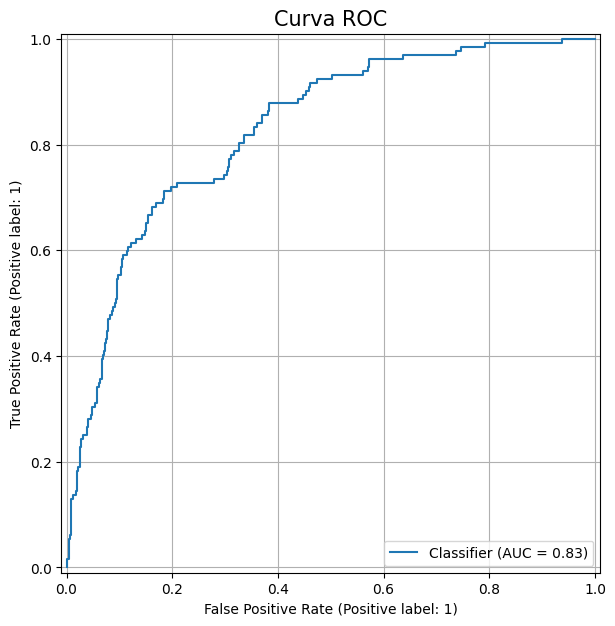


- Curva Precision-Recall:
PR-AUC           : 0.4961
Average Precision: 0.5005


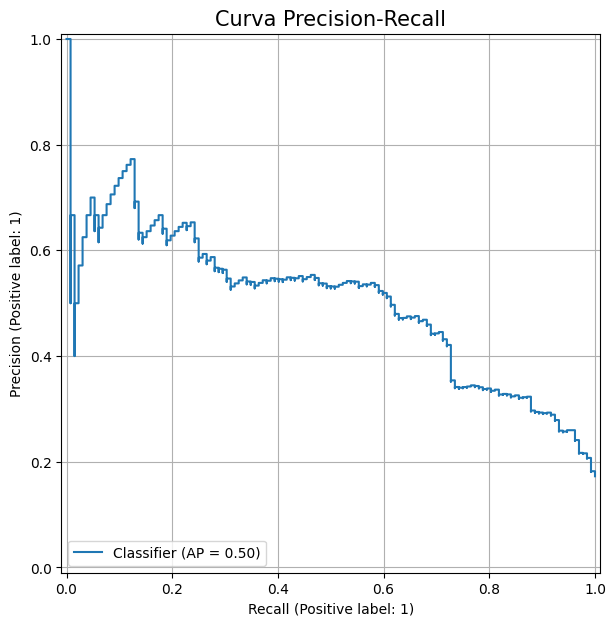


- Matriz de Confusão (threshold = 0.50):


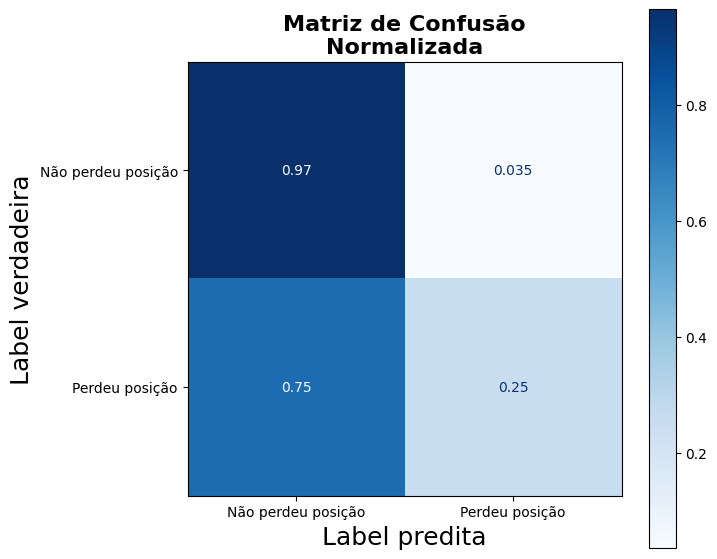


- Validação Cruzada:

Accuracy:
  Folds : [0.84166667 0.81666667 0.85       0.80833333 0.89166667]
  Média : 0.8417
  Desvio: 0.0293

Balanced Accuracy:
  Folds : [0.705      0.68253968 0.64646465 0.63997114 0.78427128]
  Média : 0.6916
  Desvio: 0.0521

Precision:
  Folds : [0.52631579 0.47619048 0.63636364 0.44444444 0.72222222]
  Média : 0.5611
  Desvio: 0.1036

Recall:
  Folds : [0.5        0.47619048 0.33333333 0.38095238 0.61904762]
  Média : 0.4619
  Desvio: 0.0994

F1-Score:
  Folds : [0.51282051 0.47619048 0.4375     0.41025641 0.66666667]
  Média : 0.5007
  Desvio: 0.0900

ROC-AUC:
  Folds : [0.8325     0.84896585 0.84656085 0.74025974 0.91293891]
  Média : 0.8362
  Desvio: 0.0555

Average Precision:
  Folds : [0.53298155 0.53248883 0.55113246 0.40230155 0.61636233]
  Média : 0.5271
  Desvio: 0.0695

- Classification Report (threshold = 0.50):
                    precision    recall  f1-score   support

Não perdeu posição       0.86      0.97      0.91       633
    Perdeu p

In [177]:
modelo_lightgbm_balanceado = LGBMClassifier(
    random_state=42,
    verbose=-1,
    scale_pos_weight=peso_classe_positiva
)

roda_modelo(
    modelo_lightgbm_balanceado,
    threshold=0.50
)

**Conclusões da performance do LightGBM com o peso balanceado**:
* também identificou poucos casos postivos (25%) e acertou apenas 60% dos que indicou como aluno com risco de defasagem.
* resultados bem fracos no geral para todos os modelos.


___
**Como mais uma tentativa de melhorar a performance, vou testar outros valores de threshold. Quero ver se em valores um pouco abaixo dos 50%, ou seja, com o ponto de corte menor, ele vai classificar mais casos como positivo, espero que algum modelo mantenha uma precisão boa.**

<br>

Vou testar com os modelos **Logistic Regression, Random Forest e LightGBM** que foram os menos piores nesses últimos testes.**

<br>

**UPDATE:**
<br>
Eu comecei mudando o valor do threshold um por um para ir testando, mas ao ver que não era produtivo, consultei um assitente de IA para ver uma forma de criar um script para testar vários valores de uma vez, além do assistente me fornecer uma maneira para testar vários valores de uma vez, ele me instruiu que em casos de bases longitunais, o correto é escolher o valor do threhold com base somente nos dados de treino. Depois ao escolher um valor para cada modelo, deve-se testar o desempenho na base de teste e ai sim ver qual perfomou melhor.
**

In [178]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

def testar_thresholds_cv(
    modelo,
    thresholds=None
):

    if thresholds is None:
        thresholds = [
            0.15,
            0.20,
            0.25,
            0.30,
            0.35,
            0.40,
            0.45,
            0.50
        ]

    skf = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    pipeline_threshold = Pipeline([
        (
            'create_tempo_programa',
            CreateTempoPrograma()
        ),
        (
            'create_stutus_historico',
            CreateStatusHistorico()
        ),
        (
            'feature_dropper',
            DropFeatures()
        ),
        (
            'fill_missing_median',
            FillMissingWithMedian()
        ),
        (
            'standard_scaler',
            StandardScalerFeatures()
        ),
        (
            'OneHotEncoding',
            OneHotEncodingNames()
        ),
        (
            'modelo',
            clone(modelo)
        )
    ])

    # probabilidades out-of-fold:
    # cada aluno é previsto por um modelo que não foi treinado nele
    probabilidades_oof = cross_val_predict(
        pipeline_threshold,
        X_train_raw,
        y_treino,
        cv=skf,
        method="predict_proba"
    )[:, 1]

    resultados = []

    for threshold in thresholds:

        y_pred_threshold = (
            probabilidades_oof >= threshold
        ).astype(int)

        resultados.append({
            "threshold": threshold,

            "precision": precision_score(
                y_treino,
                y_pred_threshold,
                zero_division=0
            ),

            "recall": recall_score(
                y_treino,
                y_pred_threshold,
                zero_division=0
            ),

            "f1": f1_score(
                y_treino,
                y_pred_threshold,
                zero_division=0
            ),

            "balanced_accuracy": balanced_accuracy_score(
                y_treino,
                y_pred_threshold
            )
        })

    return pd.DataFrame(resultados)

In [179]:
resultado_threshold_logistic = testar_thresholds_cv(
    modelo_LogisticRegression_balanceado
)

resultado_threshold_logistic

,threshold,precision,recall,f1,balanced_accuracy
0,0.15,0.239234,0.961538,0.383142,0.660205
1,0.20,0.252604,0.932692,0.397541,0.677032
2,0.25,0.279883,0.923077,0.429530,0.712547
3,0.30,0.289308,0.884615,0.436019,0.714485
4,0.35,0.322807,0.884615,0.473008,0.747751
5,0.40,0.346154,0.865385,0.494505,0.761321
6,0.45,0.359307,0.798077,0.495522,0.749845
7,0.50,0.398990,0.759615,0.523179,0.759848


**Escolha para o Logistic Regression:** 40% - valores mais equilibrados na base de treino.

In [180]:
resultado_threshold_rf = testar_thresholds_cv(
    modelo_RandomForest_balanceado
)

resultado_threshold_rf

,threshold,precision,recall,f1,balanced_accuracy
0,0.15,0.380753,0.875000,0.530612,0.788306
1,0.20,0.438776,0.826923,0.573333,0.802574
2,0.25,0.506329,0.769231,0.610687,0.805986
3,0.30,0.528000,0.634615,0.576419,0.757832
4,0.35,0.608247,0.567308,0.587065,0.745347
5,0.40,0.602564,0.451923,0.516484,0.694712
6,0.45,0.610169,0.346154,0.441718,0.649891
7,0.50,0.604167,0.278846,0.381579,0.620270


**Escolha para o Random Forest:** 25% - valores mais equilibrados na base de treino.

In [181]:
resultado_threshold_lgbm = testar_thresholds_cv(
    modelo_lightgbm_balanceado
)

resultado_threshold_lgbm

,threshold,precision,recall,f1,balanced_accuracy
0,0.15,0.416216,0.740385,0.532872,0.761321
1,0.20,0.436709,0.663462,0.526718,0.742013
2,0.25,0.475177,0.644231,0.546939,0.747519
3,0.30,0.500000,0.634615,0.559322,0.750775
4,0.35,0.487805,0.576923,0.528634,0.724953
5,0.40,0.504505,0.538462,0.520930,0.713787
6,0.45,0.520000,0.500000,0.509804,0.701613
7,0.50,0.551724,0.461538,0.502618,0.691455


**Escolha para o LightGBM:** 30% - valores mais equilibrados na base de treino.

In [182]:
# definir função para rodar os modelos com o threshold escolhido na base de treino
# e ver o desempenho de cada.
from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
)

def avaliar_teste_temporal(
    modelo,
    threshold,
    nome_modelo
):

    # nova instância para a avaliação final
    modelo_teste = clone(modelo)

    # treinar somente com os dados de 2022
    modelo_teste.fit(
        X_treino,
        y_treino
    )

    # probabilidades para 2023 -> 2024
    probabilidades = modelo_teste.predict_proba(
        X_teste
    )[:, 1]

    # aplicar o threshold escolhido anteriormente por CV
    y_pred = (
        probabilidades >= threshold
    ).astype(int)

    # métricas
    precision_curve, recall_curve, _ = (
        precision_recall_curve(
            y_teste,
            probabilidades
        )
    )

    pr_auc = auc(
        recall_curve,
        precision_curve
    )

    print("\n" + "=" * 70)
    print(nome_modelo)
    print(f"Threshold: {threshold:.2f}")
    print("=" * 70)

    print(
        f"\nROC-AUC: "
        f"{roc_auc_score(y_teste, probabilidades):.4f}"
    )

    print(
        f"PR-AUC: "
        f"{pr_auc:.4f}"
    )

    print(
        f"Average Precision: "
        f"{average_precision_score(y_teste, probabilidades):.4f}"
    )

    print(
        f"\nAccuracy: "
        f"{accuracy_score(y_teste, y_pred):.4f}"
    )

    print(
        f"Balanced Accuracy: "
        f"{balanced_accuracy_score(y_teste, y_pred):.4f}"
    )

    print(
        f"Precision classe positiva: "
        f"{precision_score(y_teste, y_pred, zero_division=0):.4f}"
    )

    print(
        f"Recall classe positiva: "
        f"{recall_score(y_teste, y_pred, zero_division=0):.4f}"
    )

    print(
        f"F1 classe positiva: "
        f"{f1_score(y_teste, y_pred, zero_division=0):.4f}"
    )

    # matriz de confusão
    print("\nMatriz de confusão - valores absolutos:")

    print(
        confusion_matrix(
            y_teste,
            y_pred
        )
    )

    print("\nMatriz de confusão - normalizada:")

    print(
        confusion_matrix(
            y_teste,
            y_pred,
            normalize="true"
        )
    )


    # classification report
    print("\nClassification Report:")

    print(
        classification_report(
            y_teste,
            y_pred,
            target_names=[
                "Não perdeu posição",
                "Perdeu posição"
            ],
            zero_division=0
        )
    )

    return modelo_teste

In [183]:
modelo_logistic_teste = avaliar_teste_temporal(
    modelo_LogisticRegression_balanceado,
    threshold=0.40,
    nome_modelo="Logistic Regression Balanceada"
)


Logistic Regression Balanceada
Threshold: 0.40

ROC-AUC: 0.8084
PR-AUC: 0.4926
Average Precision: 0.4961

Accuracy: 0.7542
Balanced Accuracy: 0.7376
Precision classe positiva: 0.3852
Recall classe positiva: 0.7121
F1 classe positiva: 0.5000

Matriz de confusão - valores absolutos:
[[483 150]
 [ 38  94]]

Matriz de confusão - normalizada:
[[0.76303318 0.23696682]
 [0.28787879 0.71212121]]

Classification Report:
                    precision    recall  f1-score   support

Não perdeu posição       0.93      0.76      0.84       633
    Perdeu posição       0.39      0.71      0.50       132

          accuracy                           0.75       765
         macro avg       0.66      0.74      0.67       765
      weighted avg       0.83      0.75      0.78       765



**Logistic Regression**: identificou mais casos de alunos que defasaram, mas gerou muitos falsos positivos para isso

In [184]:
modelo_rf_teste = avaliar_teste_temporal(
    modelo_RandomForest_balanceado,
    threshold=0.25,
    nome_modelo="Random Forest Balanceado"
)


Random Forest Balanceado
Threshold: 0.25

ROC-AUC: 0.8305
PR-AUC: 0.5236
Average Precision: 0.5205

Accuracy: 0.8405
Balanced Accuracy: 0.7268
Precision classe positiva: 0.5368
Recall classe positiva: 0.5530
F1 classe positiva: 0.5448

Matriz de confusão - valores absolutos:
[[570  63]
 [ 59  73]]

Matriz de confusão - normalizada:
[[0.90047393 0.09952607]
 [0.4469697  0.5530303 ]]

Classification Report:
                    precision    recall  f1-score   support

Não perdeu posição       0.91      0.90      0.90       633
    Perdeu posição       0.54      0.55      0.54       132

          accuracy                           0.84       765
         macro avg       0.72      0.73      0.72       765
      weighted avg       0.84      0.84      0.84       765



**Random Forest**: identificou bem menos casos positivos que o Logistic Regression, mas não gerou tantos falsos alertas, está bem mais equilibrado que o modelo anterior testado.

In [185]:
modelo_lgbm_teste = avaliar_teste_temporal(
    modelo_lightgbm_balanceado,
    threshold=0.30,
    nome_modelo="LightGBM Balanceado"
)


LightGBM Balanceado
Threshold: 0.30

ROC-AUC: 0.8281
PR-AUC: 0.4961
Average Precision: 0.5005

Accuracy: 0.8379
Balanced Accuracy: 0.6682
Precision classe positiva: 0.5400
Recall classe positiva: 0.4091
F1 classe positiva: 0.4655

Matriz de confusão - valores absolutos:
[[587  46]
 [ 78  54]]

Matriz de confusão - normalizada:
[[0.92733017 0.07266983]
 [0.59090909 0.40909091]]

Classification Report:
                    precision    recall  f1-score   support

Não perdeu posição       0.88      0.93      0.90       633
    Perdeu posição       0.54      0.41      0.47       132

          accuracy                           0.84       765
         macro avg       0.71      0.67      0.68       765
      weighted avg       0.82      0.84      0.83       765



**LightGBM**: Precisão de 54% e recall de 41%, inferior ao Random Forest.

___
**MODELO ESCOLHIDO/VENCEDOR: Random Forest - com balanceamento - threshold de 25%**

Em todos os testes foi o que performeu com maior equilibrado, eu gostaria de resultados melhores, mas acho que não vai mudar muito pelas amostras que temos e pelas features que determinam se um perfil de risco de defasagem. Perdeu somente em recall para o Logistic Random, mas esse gerou vários alertas falsos, portanto minha decisão é o Random Forest balanceado com threshold de 25%.

## ETAPA 11: Salvando o joblib do modelo vencedor

**Vou retreinar o modelo, agora com a base inteira para aproveitar todo o histórico possível antes do deploy.**

In [186]:
# retreinar usan todos os registros os de 2022-2023 e 2023-2024 para o arquivo
# .joblib ficar mais enxuto.
TARGET = "defasou_ano_seguinte"

X_final_raw = df_longitudinal.drop(
    columns=[TARGET]
).copy()

y_final = (
    df_longitudinal[TARGET]
    .astype(int)
    .copy()
)

print("Base final para produção:")
print("X:", X_final_raw.shape)
print("y:", y_final.shape)

print("\nDistribuição da target:")
print(
    y_final
    .value_counts()
    .sort_index()
)

Base final para produção:
X: (1365, 17)
y: (1365,)

Distribuição da target:
defasou_ano_seguinte
0    1129
1     236
Name: count, dtype: int64


In [187]:
# treinar o pré-processador final

# clone cria uma nova pipeline sem carregar os parâmetros
# aprendidos anteriormente somente com 2022
pipeline_final = clone(pipeline)

pipeline_final.fit(
    X_final_raw
)

X_final = pipeline_final.transform(
    X_final_raw
)

# treinar o modelo final
modelo_final = RandomForestClassifier(
    random_state=42,
    class_weight="balanced"
)

modelo_final.fit(
    X_final,
    y_final
)


threshold_final = 0.25

In [188]:

from pathlib import Path
import joblib

In [189]:
# salvar o joblib
artefato_modelo = {
    "preprocessador": pipeline_final,
    "modelo": modelo_final,
    "threshold": threshold_final,

    # metadados úteis para validação no deploy
    "nome_modelo": "RandomForestClassifier",
    "class_weight": "balanced",
    "target": TARGET,
    "features_entrada": X_final_raw.columns.tolist()
}

joblib.dump(
    artefato_modelo,
    "random_forest_balanceado_threshold_025.joblib"
)


['random_forest_balanceado_threshold_025.joblib']